In [4]:
# ============================================================
# 1. INSTALAÇÃO DO LIGHTGBM
# ============================================================

%pip install -q lightgbm

import lightgbm as lgb

print("LightGBM instalado com sucesso!")
print("Versão:", lgb.__version__)

Note: you may need to restart the kernel to use updated packages.
LightGBM instalado com sucesso!
Versão: 4.7.0



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
# ============================================================
# 1. PREPARAÇÃO DO AMBIENTE
# FRAUDRADAR - EXPERIMENTO LIGHTGBM
# ============================================================

# Manipulação e análise de dados
from pathlib import Path
import gc
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Machine Learning
import lightgbm as lgb

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ============================================================
# CONFIGURAÇÕES DE REPRODUTIBILIDADE
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# ============================================================
# CONFIGURAÇÕES VISUAIS
# ============================================================

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["figure.dpi"] = 110

warnings.filterwarnings("default")

# ============================================================
# IDENTIFICAÇÃO DO AMBIENTE
# ============================================================

print("=== AMBIENTE DO FRAUDRADAR ===")

print("Python: ambiente atual do Jupyter")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("LightGBM:", lgb.__version__)

print("\n=== CONFIGURAÇÕES ===")
print("Seed:", SEED)

print("\nAmbiente preparado com sucesso!")

=== AMBIENTE DO FRAUDRADAR ===
Python: ambiente atual do Jupyter
NumPy: 2.5.4
Pandas: 3.1.0
Matplotlib: 3.11.2
LightGBM: 4.7.0

=== CONFIGURAÇÕES ===
Seed: 42

Ambiente preparado com sucesso!


In [2]:
# ============================================================
# 2. LOCALIZAÇÃO DO DATASET
# ============================================================

# Diretório Downloads do usuário
pasta_downloads = Path.home() / "Downloads"

# Possíveis localizações do arquivo
candidatos = [
    pasta_downloads / "SAML-D.csv",
    pasta_downloads / "archive" / "SAML-D.csv"
]

# Procurar o arquivo nos caminhos conhecidos
caminho = next(
    (arquivo for arquivo in candidatos if arquivo.is_file()),
    None
)

# Caso não seja encontrado, procurar em subpastas
if caminho is None:

    encontrados = list(
        pasta_downloads.rglob("SAML-D.csv")
    )

    if encontrados:
        caminho = encontrados[0]

# Validar localização
if caminho is None:

    raise FileNotFoundError(
        "SAML-D.csv não encontrado na pasta Downloads."
    )

# Informações do arquivo
tamanho_bytes = caminho.stat().st_size
tamanho_mb = tamanho_bytes / (1024 ** 2)
tamanho_gb = tamanho_bytes / (1024 ** 3)

print("=== DATASET LOCALIZADO ===")

print("Arquivo:", caminho)
print(f"Tamanho: {tamanho_mb:.2f} MB")
print(f"Tamanho: {tamanho_gb:.2f} GB")

print("\nArquivo encontrado com sucesso!")

=== DATASET LOCALIZADO ===
Arquivo: C:\Users\Aluno\Downloads\archive\SAML-D.csv
Tamanho: 950.02 MB
Tamanho: 0.93 GB

Arquivo encontrado com sucesso!


3. CARREGAMENTO E CONHECIMENTO DO DATASET

Nesta etapa, será realizado o carregamento integral do dataset SAML-D. O objetivo é conhecer sua estrutura, dimensões, variáveis, tipos de dados e período abrangido.

O carregamento utilizará tipos de dados definidos previamente para melhorar a utilização de memória e preservar o significado das variáveis.

In [3]:
# ============================================================
# 3. CARREGAMENTO DO DATASET SAML-D
# ============================================================

print("Carregando o dataset completo...")

inicio_carregamento = time.perf_counter()

# Definição dos tipos de dados
tipos = {
    "Time": "string",
    "Date": "string",
    "Sender_account": "int64",
    "Receiver_account": "int64",
    "Amount": "float64",
    "Payment_currency": "category",
    "Received_currency": "category",
    "Sender_bank_location": "category",
    "Receiver_bank_location": "category",
    "Payment_type": "category",
    "Is_laundering": "int8",
    "Laundering_type": "category"
}

# Carregar TODOS os registros
df = pd.read_csv(
    caminho,
    dtype=tipos,
    low_memory=False
)

# Criar variável temporal
df["timestamp"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

tempo_carregamento = time.perf_counter() - inicio_carregamento

# ============================================================
# PRIMEIRAS INFORMAÇÕES DO DATASET
# ============================================================

print("\n=== CARREGAMENTO CONCLUÍDO ===")

print(f"Tempo de carregamento: {tempo_carregamento:.2f} segundos")

print("\nDimensões do dataset:")
print(f"Registros: {len(df):,}")
print(f"Colunas: {len(df.columns)}")

print("\nPeríodo abrangido:")

print("Primeira data:", df["timestamp"].min())
print("Última data:", df["timestamp"].max())

print("\nDatas inválidas:")
print(df["timestamp"].isna().sum())

print("\nMemória utilizada:")

memoria_gb = (
    df.memory_usage(deep=True).sum() / (1024 ** 3)
)

print(f"{memoria_gb:.2f} GB")

# ============================================================
# ESTRUTURA DAS COLUNAS
# ============================================================

print("\n=== ESTRUTURA DAS VARIÁVEIS ===")

display(
    pd.DataFrame({
        "Coluna": df.columns,
        "Tipo de dado": df.dtypes.astype(str).values,
        "Valores não nulos": df.notna().sum().values,
        "Valores ausentes": df.isna().sum().values
    })
)

# ============================================================
# PRIMEIROS REGISTROS
# ============================================================

print("\n=== PRIMEIRAS TRANSAÇÕES ===")

display(df.head(10))

Carregando o dataset completo...

=== CARREGAMENTO CONCLUÍDO ===
Tempo de carregamento: 8.79 segundos

Dimensões do dataset:
Registros: 9,504,852
Colunas: 13

Período abrangido:
Primeira data: 2022-10-07 10:35:19
Última data: 2023-08-23 10:57:12

Datas inválidas:
0

Memória utilizada:
1.37 GB

=== ESTRUTURA DAS VARIÁVEIS ===


,Coluna,Tipo de dado,Valores não nulos,Valores ausentes
0,Time,string,9504852,0
1,Date,string,9504852,0
2,Sender_account,int64,9504852,0
3,Receiver_account,int64,9504852,0
4,Amount,float64,9504852,0
5,Payment_currency,category,9504852,0
6,Received_currency,category,9504852,0
7,Sender_bank_location,category,9504852,0
8,Receiver_bank_location,category,9504852,0
9,Payment_type,category,9504852,0



=== PRIMEIRAS TRANSAÇÕES ===


,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type,timestamp
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits,2022-10-07 10:35:19
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out,2022-10-07 10:35:20
2,10:35:20,2022-10-07,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out,2022-10-07 10:35:20
3,10:35:21,2022-10-07,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In,2022-10-07 10:35:21
4,10:35:21,2022-10-07,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits,2022-10-07 10:35:21
5,10:35:21,2022-10-07,8974559268,3143547511,5130.99,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Group,2022-10-07 10:35:21
6,10:35:23,2022-10-07,980191499,8577635959,12176.52,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Small_Fan_Out,2022-10-07 10:35:23
7,10:35:23,2022-10-07,8057793308,9350896213,56.90,UK pounds,UK pounds,UK,UK,Credit card,0,Normal_Small_Fan_Out,2022-10-07 10:35:23
8,10:35:26,2022-10-07,6116657264,656192169,4738.45,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Fan_Out,2022-10-07 10:35:26
9,10:35:29,2022-10-07,7421451752,2755709071,5883.87,Indian rupee,UK pounds,UK,UK,Credit card,0,Normal_Fan_Out,2022-10-07 10:35:29


4. ANÁLISE DA QUALIDADE DOS DADOS

A qualidade dos dados influencia diretamente a confiabilidade dos modelos de classificação. Nesta etapa, investigamos duplicidades, inconsistências financeiras, identificadores, sequência temporal e coerência dos rótulos.

In [4]:
# ============================================================
# 4. ANÁLISE DA QUALIDADE DOS DADOS
# ============================================================

print("=" * 65)
print("ANÁLISE DA QUALIDADE DO DATASET")
print("=" * 65)

total_registros = len(df)


# ============================================================
# 4.1 DUPLICIDADES
# ============================================================

print("\n=== 4.1 DUPLICIDADES ===")

# Colunas originais do CSV
colunas_originais = [
    coluna for coluna in df.columns
    if coluna != "timestamp"
]

# Registros inteiramente duplicados
duplicados_exatos = df.duplicated(
    subset=colunas_originais
).sum()

# Possíveis duplicidades de operações
# Mesma origem, destino, horário, valor e características financeiras
chave_operacao = [
    "Sender_account",
    "Receiver_account",
    "timestamp",
    "Amount",
    "Payment_currency",
    "Received_currency",
    "Payment_type"
]

duplicados_operacao = df.duplicated(
    subset=chave_operacao
).sum()

print(f"Registros duplicados exatos: {duplicados_exatos:,}")

print(
    "Possíveis operações duplicadas pela assinatura definida:",
    f"{duplicados_operacao:,}"
)


# ============================================================
# 4.2 VALORES FINANCEIROS
# ============================================================

print("\n=== 4.2 ANÁLISE DOS VALORES FINANCEIROS ===")

valores_invalidos = (
    ~np.isfinite(df["Amount"].to_numpy())
).sum()

valores_negativos = (df["Amount"] < 0).sum()

valores_zero = (df["Amount"] == 0).sum()

valores_positivos = (df["Amount"] > 0).sum()

resumo_valores = pd.DataFrame({
    "Condição": [
        "Valores positivos",
        "Valores iguais a zero",
        "Valores negativos",
        "Valores não finitos"
    ],
    "Quantidade": [
        valores_positivos,
        valores_zero,
        valores_negativos,
        valores_invalidos
    ]
})

resumo_valores["Percentual (%)"] = (
    resumo_valores["Quantidade"] / total_registros * 100
)

display(
    resumo_valores.round(4)
)


# ============================================================
# 4.3 IDENTIFICADORES DAS CONTAS
# ============================================================

print("\n=== 4.3 IDENTIFICADORES DAS CONTAS ===")

remetentes_invalidos = (
    df["Sender_account"] <= 0
).sum()

destinatarios_invalidos = (
    df["Receiver_account"] <= 0
).sum()

transferencias_proprias = (
    df["Sender_account"] == df["Receiver_account"]
).sum()

print(
    "Identificadores inválidos de remetentes:",
    f"{remetentes_invalidos:,}"
)

print(
    "Identificadores inválidos de destinatários:",
    f"{destinatarios_invalidos:,}"
)

print(
    "Transferências entre a mesma conta:",
    f"{transferencias_proprias:,}"
)


# ============================================================
# 4.4 ORDEM CRONOLÓGICA
# ============================================================

print("\n=== 4.4 ORDEM CRONOLÓGICA ===")

ordem_cronologica = df["timestamp"].is_monotonic_increasing

inversoes_temporais = (
    df["timestamp"].diff() < pd.Timedelta(0)
).sum()

print("Dataset originalmente ordenado:", ordem_cronologica)

print(
    "Inversões temporais entre registros consecutivos:",
    f"{inversoes_temporais:,}"
)


# ============================================================
# 4.5 CONSISTÊNCIA DA VARIÁVEL-ALVO
# ============================================================

print("\n=== 4.5 CONSISTÊNCIA DOS RÓTULOS ===")

print("Valores encontrados em Is_laundering:")

display(
    df["Is_laundering"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Quantidade")
)

rotulos_invalidos = (
    ~df["Is_laundering"].isin([0, 1])
).sum()

print("Rótulos diferentes de 0 e 1:", rotulos_invalidos)

print("\nRelação entre Is_laundering e Laundering_type:")

distribuicao_tipos = pd.crosstab(
    df["Is_laundering"],
    df["Laundering_type"],
    margins=True
)

display(distribuicao_tipos)


# ============================================================
# 4.6 RESUMO GERAL
# ============================================================

print("\n=== RESUMO DA QUALIDADE DOS DADOS ===")

resumo_qualidade = pd.DataFrame({
    "Verificação": [
        "Valores ausentes",
        "Datas inválidas",
        "Duplicidades exatas",
        "Valores não finitos",
        "Valores negativos",
        "Valores iguais a zero",
        "Contas remetentes inválidas",
        "Contas destinatárias inválidas",
        "Transferências próprias",
        "Rótulos inválidos"
    ],
    "Quantidade": [
        df.isna().sum().sum(),
        df["timestamp"].isna().sum(),
        duplicados_exatos,
        valores_invalidos,
        valores_negativos,
        valores_zero,
        remetentes_invalidos,
        destinatarios_invalidos,
        transferencias_proprias,
        rotulos_invalidos
    ]
})

display(resumo_qualidade)

print("\nInvestigação de qualidade concluída!")

ANÁLISE DA QUALIDADE DO DATASET

=== 4.1 DUPLICIDADES ===
Registros duplicados exatos: 0
Possíveis operações duplicadas pela assinatura definida: 0

=== 4.2 ANÁLISE DOS VALORES FINANCEIROS ===


,Condição,Quantidade,Percentual (%)
0,Valores positivos,9504852,100.0
1,Valores iguais a zero,0,0.0
2,Valores negativos,0,0.0
3,Valores não finitos,0,0.0



=== 4.3 IDENTIFICADORES DAS CONTAS ===
Identificadores inválidos de remetentes: 0
Identificadores inválidos de destinatários: 0
Transferências entre a mesma conta: 0

=== 4.4 ORDEM CRONOLÓGICA ===
Dataset originalmente ordenado: True
Inversões temporais entre registros consecutivos: 0

=== 4.5 CONSISTÊNCIA DOS RÓTULOS ===
Valores encontrados em Is_laundering:


,Quantidade
Is_laundering,
0,9494979
1,9873


Rótulos diferentes de 0 e 1: 0

Relação entre Is_laundering e Laundering_type:


Laundering_type,Behavioural_Change_1,Behavioural_Change_2,Bipartite,Cash_Withdrawal,Cycle,Deposit-Send,Fan_In,Fan_Out,Gather-Scatter,Layered_Fan_In,...,Normal_Plus_Mutual,Normal_Small_Fan_Out,Normal_single_large,Over-Invoicing,Scatter-Gather,Single_large,Smurfing,Stacked Bipartite,Structuring,All
Is_laundering,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0,...,155041,3477717,20641,0,0,0,0,0,0,9494979
1,394,345,383,1334,382,945,364,237,354,656,...,0,0,0,54,338,250,932,506,1870,9873
All,394,345,383,1334,382,945,364,237,354,656,...,155041,3477717,20641,54,338,250,932,506,1870,9504852



=== RESUMO DA QUALIDADE DOS DADOS ===


,Verificação,Quantidade
0,Valores ausentes,0
1,Datas inválidas,0
2,Duplicidades exatas,0
3,Valores não finitos,0
4,Valores negativos,0
5,Valores iguais a zero,0
6,Contas remetentes inválidas,0
7,Contas destinatárias inválidas,0
8,Transferências próprias,0
9,Rótulos inválidos,0



Investigação de qualidade concluída!


5.1 DISTRIBUIÇÃO DA VARIÁVEL-ALVO

O objetivo desta análise é identificar a distribuição das transações normais e suspeitas. Em problemas de prevenção à lavagem de dinheiro, o desbalanceamento das classes é uma característica importante, pois as operações suspeitas representam uma pequena parcela do volume total de transações.

=== DISTRIBUIÇÃO DA VARIÁVEL-ALVO ===


,Classificação,Quantidade,Percentual (%)
0,Normal,9494979,99.89613
1,Suspeita,9873,0.10387



=== PROPORÇÃO DAS CLASSES ===
Transações normais: 9,494,979 (99.8961%)
Transações suspeitas: 9,873 (0.1039%)

Relação entre as classes: 961.7 transações normais para cada transação suspeita.


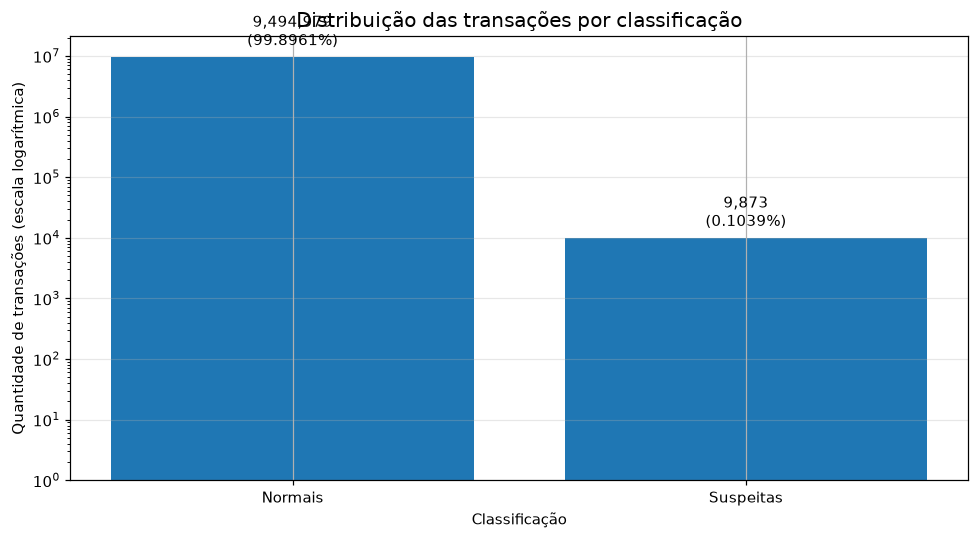

In [5]:
# ============================================================
# 5.1 DISTRIBUIÇÃO DAS CLASSES
# ============================================================

print("=== DISTRIBUIÇÃO DA VARIÁVEL-ALVO ===")

# Contabilizar as classes
contagem_classes = (
    df["Is_laundering"]
    .value_counts()
    .sort_index()
)

total_transacoes = len(df)

# Construir tabela de distribuição
resumo_classes = pd.DataFrame({
    "Classificação": [
        "Normal",
        "Suspeita"
    ],
    "Quantidade": [
        contagem_classes.loc[0],
        contagem_classes.loc[1]
    ]
})

resumo_classes["Percentual (%)"] = (
    resumo_classes["Quantidade"]
    / total_transacoes * 100
)

display(
    resumo_classes.round(5)
)


# ============================================================
# RELAÇÃO ENTRE AS CLASSES
# ============================================================

quantidade_normais = int(contagem_classes.loc[0])
quantidade_suspeitas = int(contagem_classes.loc[1])

proporcao_suspeitas = (
    quantidade_suspeitas / total_transacoes
)

relacao_classes = (
    quantidade_normais / quantidade_suspeitas
)

print("\n=== PROPORÇÃO DAS CLASSES ===")

print(
    f"Transações normais: {quantidade_normais:,} "
    f"({quantidade_normais / total_transacoes:.4%})"
)

print(
    f"Transações suspeitas: {quantidade_suspeitas:,} "
    f"({proporcao_suspeitas:.4%})"
)

print(
    f"\nRelação entre as classes: "
    f"{relacao_classes:.1f} transações normais "
    f"para cada transação suspeita."
)


# ============================================================
# GRÁFICO 1 - QUANTIDADE DE TRANSAÇÕES
# ESCALA LOGARÍTMICA
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5))

classes = ["Normais", "Suspeitas"]

quantidades = [
    quantidade_normais,
    quantidade_suspeitas
]

percentuais = [
    quantidade_normais / total_transacoes * 100,
    quantidade_suspeitas / total_transacoes * 100
]

barras = ax.bar(
    classes,
    quantidades,
    bottom=1
)

ax.set_yscale("log")

ax.set_title(
    "Distribuição das transações por classificação",
    fontsize=13
)

ax.set_xlabel("Classificação")
ax.set_ylabel("Quantidade de transações (escala logarítmica)")

ax.grid(
    axis="y",
    alpha=0.3
)

# Mostrar quantidade e percentual sobre cada barra
for barra, quantidade, percentual in zip(
    barras,
    quantidades,
    percentuais
):

    ax.annotate(
        f"{quantidade:,}\n({percentual:.4f}%)",
        xy=(
            barra.get_x() + barra.get_width() / 2,
            quantidade
        ),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

Conclusão da análise da variável-alvo

A análise identificou um desbalanceamento extremamente elevado entre as classes. Das 9.504.852 transações, 9.494.979 (99,8961%) são classificadas como normais, enquanto apenas 9.873 (0,1039%) são consideradas suspeitas.

Existe aproximadamente uma transação suspeita para cada 962 transações normais.

Esse cenário torna inadequada a utilização isolada da acurácia como métrica de avaliação, pois um classificador que sempre previsse a classe majoritária poderia apresentar excelente acurácia sem identificar nenhuma operação suspeita.

Por esse motivo, serão priorizadas métricas como Average Precision, precisão e recall em diferentes posições do ranking de alertas, além de estratégias para lidar com o desbalanceamento durante o treinamento.

5.2 DISTRIBUIÇÃO DAS MOEDAS

Esta análise investiga a diversidade de moedas utilizadas nas transações, sua frequência e sua relação com a ocorrência de operações suspeitas. A investigação também é importante para interpretar corretamente a variável financeira Amount, evitando comparações diretas entre valores expressos em moedas diferentes.

=== DISTRIBUIÇÃO DAS MOEDAS ===

=== DIVERSIDADE DE MOEDAS ===
Moedas de pagamento: 13
Moedas de recebimento: 13

=== MOEDAS DE PAGAMENTO ===


,transacoes,suspeitas,normais,percentual_transacoes,taxa_suspeitas
Payment_currency,,,,,
UK pounds,9099293,8830,9090463,95.7331,0.0970
Euro,117164,260,116904,1.2327,0.2219
Turkish lira,27996,73,27923,0.2945,0.2608
Swiss franc,27492,82,27410,0.2892,0.2983
Dirham,27263,89,27174,0.2868,0.3264
Pakistani rupee,27196,62,27134,0.2861,0.2280
Naira,27143,62,27081,0.2856,0.2284
US dollar,26061,60,26001,0.2742,0.2302
Yen,25562,65,25497,0.2689,0.2543



=== MOEDAS DE RECEBIMENTO ===


,transacoes,suspeitas,normais,percentual_transacoes,taxa_suspeitas
Received_currency,,,,,
UK pounds,8783655,6919,8776736,92.4123,0.0788
Euro,231911,716,231195,2.4399,0.3087
Pakistani rupee,45993,204,45789,0.4839,0.4435
Yen,45814,118,45696,0.4820,0.2576
Moroccan dirham,45748,285,45463,0.4813,0.6230
Albanian lek,45736,262,45474,0.4812,0.5729
Mexican Peso,45255,235,45020,0.4761,0.5193
Naira,45046,288,44758,0.4739,0.6393
Indian rupee,43757,172,43585,0.4604,0.3931


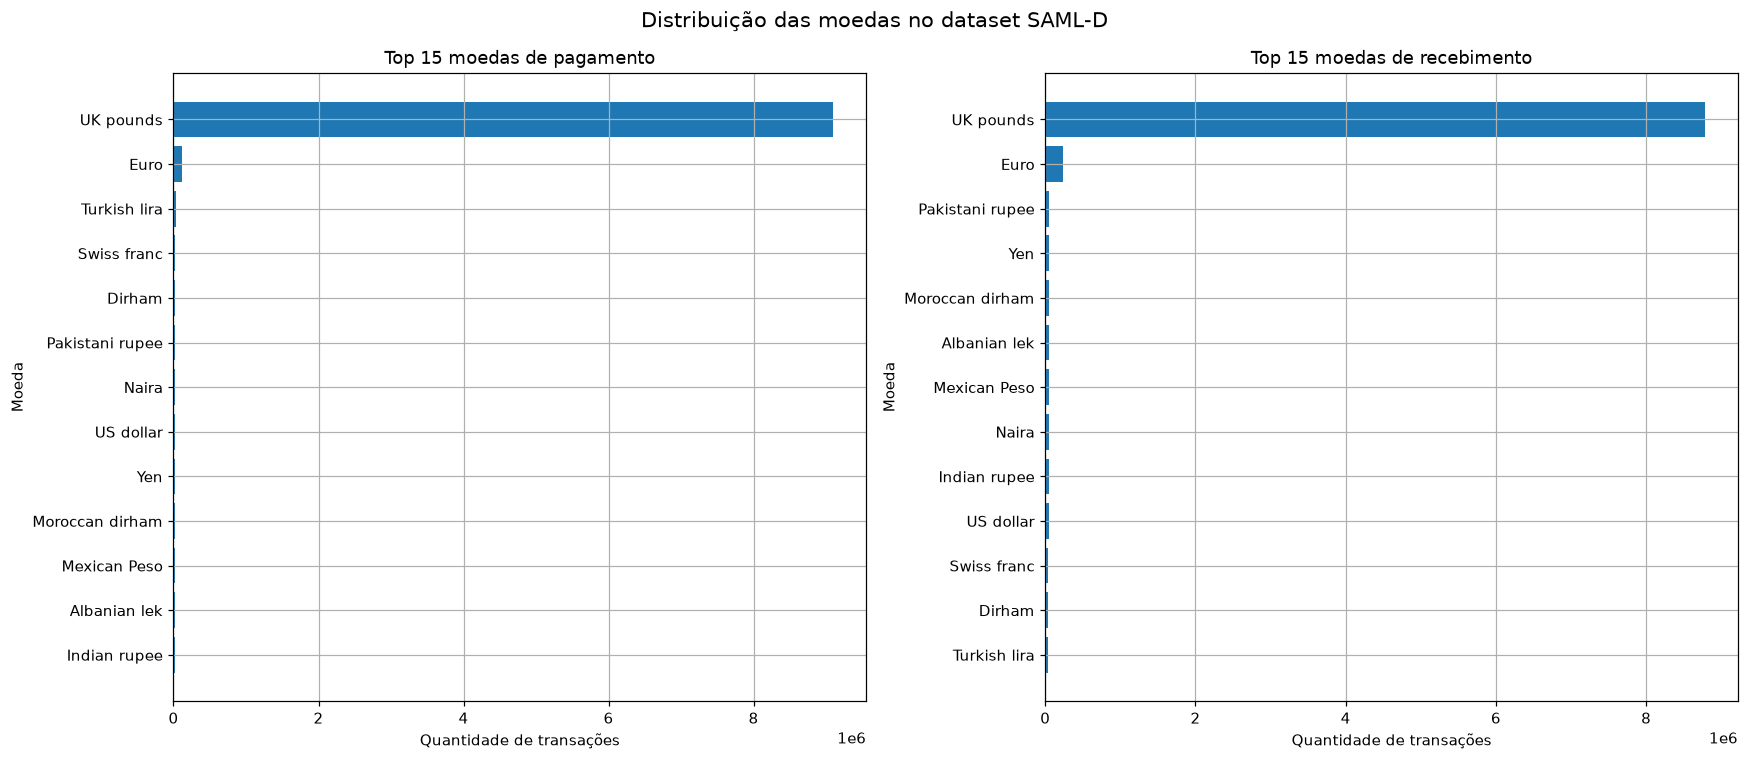


=== TAXA DE SUSPEITAS POR MOEDA DE PAGAMENTO ===


,transacoes,suspeitas,taxa_suspeitas
Payment_currency,,,
UK pounds,9099293,8830,0.0970
Euro,117164,260,0.2219
Turkish lira,27996,73,0.2608
Swiss franc,27492,82,0.2983
Dirham,27263,89,0.3264
Pakistani rupee,27196,62,0.2280
Naira,27143,62,0.2284
US dollar,26061,60,0.2302
Yen,25562,65,0.2543


In [6]:
# ============================================================
# 5.2 ANÁLISE DAS MOEDAS
# ============================================================

print("=== DISTRIBUIÇÃO DAS MOEDAS ===")


# ============================================================
# 1. RESUMO DAS MOEDAS DE PAGAMENTO E RECEBIMENTO
# ============================================================

def analisar_moedas(coluna):

    resumo = (
        df.groupby(coluna, observed=True)
        .agg(
            transacoes=("Is_laundering", "size"),
            suspeitas=("Is_laundering", "sum")
        )
    )

    resumo["normais"] = (
        resumo["transacoes"] - resumo["suspeitas"]
    )

    resumo["percentual_transacoes"] = (
        resumo["transacoes"] / len(df) * 100
    )

    resumo["taxa_suspeitas"] = (
        resumo["suspeitas"] / resumo["transacoes"] * 100
    )

    return resumo.sort_values(
        "transacoes",
        ascending=False
    )


resumo_pagamento = analisar_moedas(
    "Payment_currency"
)

resumo_recebimento = analisar_moedas(
    "Received_currency"
)


# ============================================================
# 2. QUANTIDADE DE MOEDAS DISTINTAS
# ============================================================

print("\n=== DIVERSIDADE DE MOEDAS ===")

print(
    "Moedas de pagamento:",
    df["Payment_currency"].nunique()
)

print(
    "Moedas de recebimento:",
    df["Received_currency"].nunique()
)


# ============================================================
# 3. TABELA DE MOEDAS DE PAGAMENTO
# ============================================================

print("\n=== MOEDAS DE PAGAMENTO ===")

display(
    resumo_pagamento.round(4)
)


# ============================================================
# 4. TABELA DE MOEDAS DE RECEBIMENTO
# ============================================================

print("\n=== MOEDAS DE RECEBIMENTO ===")

display(
    resumo_recebimento.round(4)
)


# ============================================================
# 5. GRÁFICOS DE FREQUÊNCIA DAS MOEDAS
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7)
)

# Moedas de pagamento
top_pagamento = (
    resumo_pagamento
    .head(15)
    .sort_values("transacoes")
)

axes[0].barh(
    top_pagamento.index.astype(str),
    top_pagamento["transacoes"]
)

axes[0].set_title(
    "Top 15 moedas de pagamento"
)

axes[0].set_xlabel(
    "Quantidade de transações"
)

axes[0].set_ylabel("Moeda")

# Moedas de recebimento
top_recebimento = (
    resumo_recebimento
    .head(15)
    .sort_values("transacoes")
)

axes[1].barh(
    top_recebimento.index.astype(str),
    top_recebimento["transacoes"]
)

axes[1].set_title(
    "Top 15 moedas de recebimento"
)

axes[1].set_xlabel(
    "Quantidade de transações"
)

axes[1].set_ylabel("Moeda")

plt.suptitle(
    "Distribuição das moedas no dataset SAML-D",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ============================================================
# 6. TAXA DE TRANSAÇÕES SUSPEITAS POR MOEDA
# ============================================================

print("\n=== TAXA DE SUSPEITAS POR MOEDA DE PAGAMENTO ===")

display(
    resumo_pagamento[
        [
            "transacoes",
            "suspeitas",
            "taxa_suspeitas"
        ]
    ].round(4)
)

5.3 DISTRIBUIÇÃO DOS VALORES FINANCEIROS

O objetivo desta investigação é identificar diferenças na distribuição dos valores movimentados entre transações normais e suspeitas.

Como o dataset apresenta 13 moedas diferentes, as comparações serão realizadas separadamente por moeda, evitando interpretações incorretas decorrentes de diferenças entre unidades monetárias.

Também será utilizada uma transformação logarítmica para facilitar a visualização de distribuições assimétricas e valores extremos.

=== ANÁLISE DOS VALORES FINANCEIROS ===

=== ESTATÍSTICAS POR MOEDA E CLASSE ===


transacoes      media   minimo       maximo  \
Payment_currency Is_laundering                                                
Albanian lek     0                   24714    9615.60    18.82    935820.72   
                 1                      64   10711.80  2800.75     75683.50   
Dirham           0                   27174    9907.22    17.17    956193.00   
                 1                      89   10902.37  2259.18     62867.86   
Euro             0                  116904   10523.27     9.15    995675.88   
                 1                     260   16758.71  1250.41    294167.63   
Indian rupee     0                   24589   10217.45    13.41    985678.03   
                 1                      68    9736.18  2618.80     67635.42   
Mexican Peso     0                   24784   10212.47     5.90    992045.52   
                 1                      68   54143.33  2302.40   1928846.51   
Moroccan dirham  0                   25305   10072.20    18.17    883295.90   
                 1                      90  129704.58   903.59   5881588.23   
Naira            0                   27081   10438.99    13.91    980326.83   
                 1                      62    6858.63  2291.54     30192.52   
Pakistani rupee  0                   27134   10131.44    10.14    893360.76   
                 1                      62    9650.83  1919.90     50791.97   
Swiss franc      0                   27410   10391.66    14.01    980925.83   
                 1                      82  137133.25  2172.76   6812158.18   
Turkish lira     0                   27923    9786.11    15.25    990051.52   
                 1                      73   11315.23  2652.74    104896.34   
UK pounds        0                 9090463    8664.10     3.73    999962.19   
                 1                    8830   41243.59    15.82  12618498.40   
US dollar        0                   26001   10162.21    20.23    881277.95   
                 1                      60   11610.23  1098.71     47342.12   
Yen              0                   25497    9925.67    10.47    828398.20   
                 1                      65   11070.95  2608.19     66876.85   

                                    p05      p25  mediana       p75       p90  \
Payment_currency Is_laundering                                                  
Albanian lek     0               433.33  3903.94  7154.86  11633.08  17860.48   
                 1              3477.85  4749.34  6506.99  11294.90  19458.98   
Dirham           0               535.34  4593.84  7161.28  11694.16  17438.53   
                 1              2995.96  4245.38  6289.90   9798.31  27129.44   
Euro             0               736.79  4972.83  7642.74  12156.18  18712.64   
                 1              3053.31  4470.51  6497.50  11887.84  39587.85   
Indian rupee     0               573.35  4646.09  7323.48  11936.55  17799.35   
                 1              2755.22  4088.46  6020.89   9534.08  20789.37   
Mexican Peso     0               540.09  4632.99  7395.62  11741.61  18899.45   
                 1              3432.30  5009.02  6709.14  11178.06  19205.08   
Moroccan dirham  0               529.98  4691.97  7396.86  11705.47  18058.93   
                 1              3513.85  5092.43  7781.63  14283.00  44060.88   
Naira            0               608.13  4792.45  7657.93  11907.06  18173.00   
                 1              2751.26  4201.09  5757.16   7813.92  12254.97   
Pakistani rupee  0               693.35  4866.28  7586.68  11728.31  18172.26   
                 1              2965.16  4544.74  6922.39   9431.68  17075.87   
Swiss franc      0               610.07  4709.80  7537.40  11924.61  18279.61   
                 1              3060.90  4676.92  6871.62  10020.87  23978.10   
Turkish lira     0               513.73  4565.34  7232.73  11747.80  18036.55   
                 1              3151.19  4685.39  6286.73   9789.67  21013.10   
UK pounds        0               211.


=== DISTRIBUIÇÃO DOS VALORES EM UK POUNDS ===


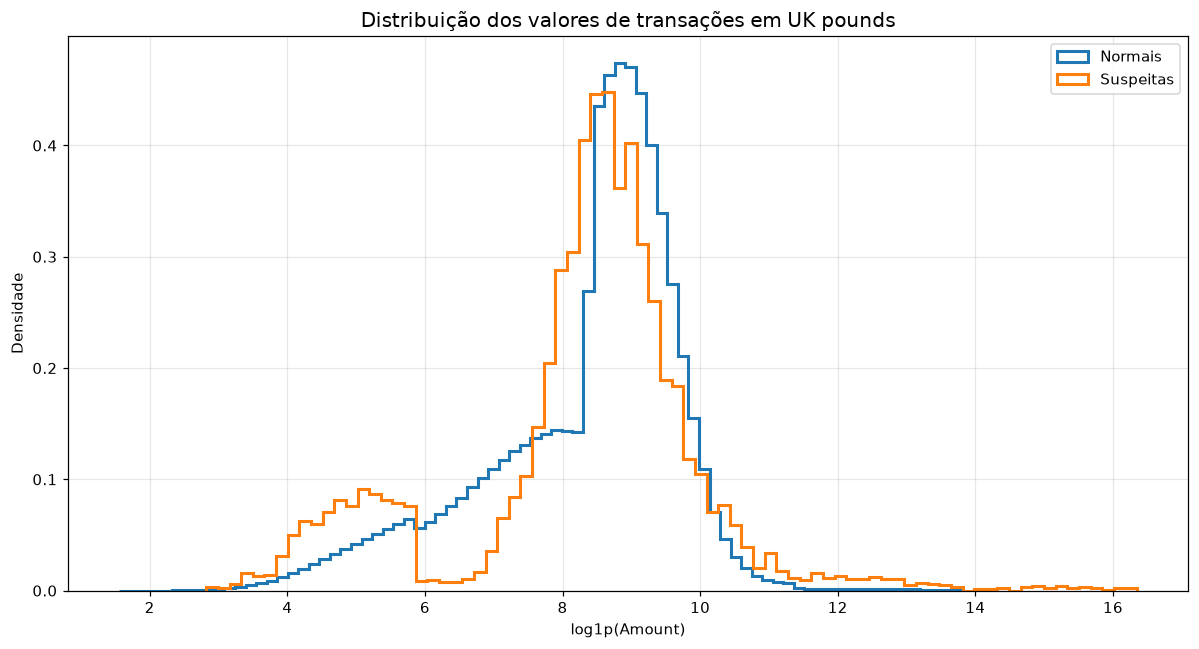


=== BOXPLOTS POR MOEDA ===


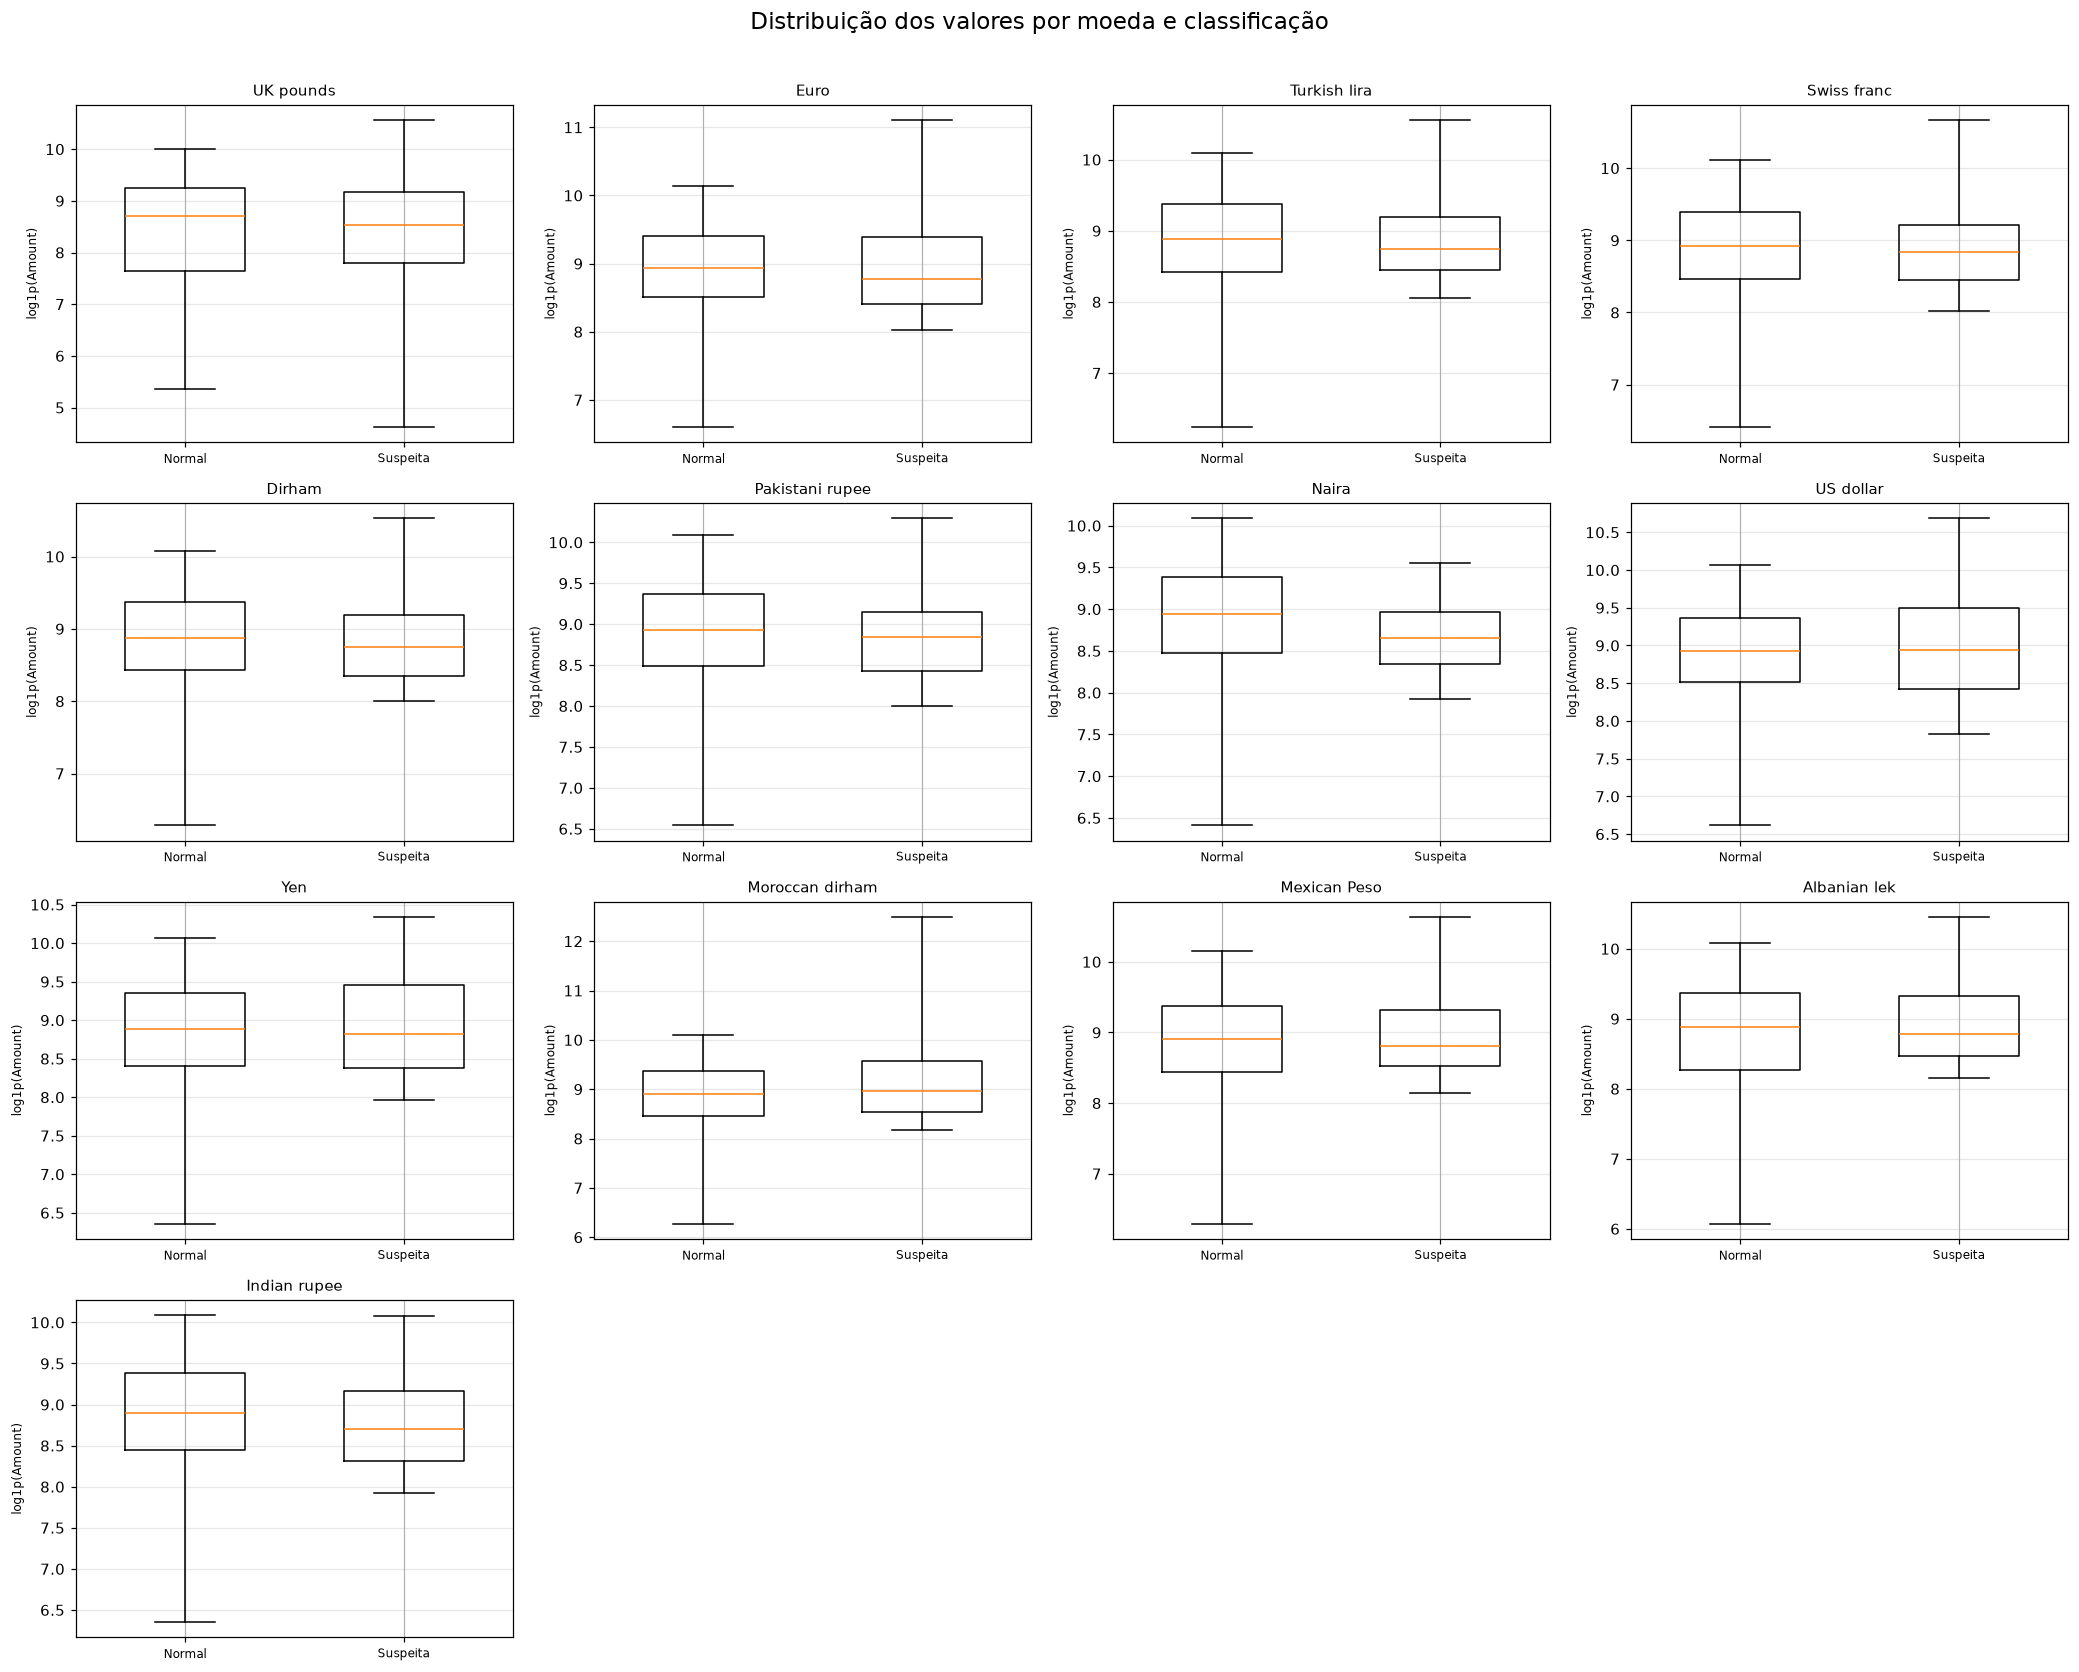


=== COMPARAÇÃO DAS MEDIANAS ===


transacoes        mediana                p95             \
Is_laundering             0     1        0        1         0          1   
Payment_currency                                                           
Albanian lek          24714    64  7154.86  6506.99  23832.51   34732.94   
Dirham                27174    89  7161.28  6289.90  23679.27   37250.53   
Euro                 116904   260  7642.74  6497.50  25429.53   66535.65   
Indian rupee          24589    68  7323.48  6020.89  24032.40   23943.53   
Mexican Peso          24784    68  7395.62  6709.14  25546.06   41611.14   
Moroccan dirham       25305    90  7396.86  7781.63  24168.97  266510.89   
Naira                 27081    62  7657.93  5757.16  23989.51   14016.04   
Pakistani rupee       27134    62  7586.68  6922.39  24053.94   29467.56   
Swiss franc           27410    82  7537.40  6871.62  24666.96   42819.65   
Turkish lira          27923    73  7232.73  6286.73  24141.59   38375.82   
UK pounds           9090463  8830  6047.08  5091.06  21926.03   38619.46   
US dollar             26001    60  7546.90  7641.64  23419.41   43619.52   
Yen                   25497    65  7178.11  6791.24  23622.40   30963.07   

                       p99              
Is_laundering            0           1  
Payment_currency                        
Albanian lek      48922.28    52116.95  
Dirham            49462.57    58730.15  
Euro              53604.74   154557.24  
Indian rupee      55993.23    66606.85  
Mexican Peso      50473.20  1380757.83  
Moroccan dirham   48566.94  2993771.11  
Naira             58323.06    21540.31  
Pakistani rupee   46927.72    46467.66  
Swiss franc       52354.13  4237820.37  
Turkish lira      48043.61    73336.16  
UK pounds         44566.67   421175.14  
US dollar         48302.31    47276.38  
Yen               52550.32    56184.58


Análise dos valores financeiros concluída!


In [7]:
# ============================================================
# 5.3 DISTRIBUIÇÃO DOS VALORES FINANCEIROS
# ============================================================

print("=== ANÁLISE DOS VALORES FINANCEIROS ===")


# ============================================================
# 1. ESTATÍSTICAS DESCRITIVAS POR MOEDA E CLASSIFICAÇÃO
# ============================================================

print("\n=== ESTATÍSTICAS POR MOEDA E CLASSE ===")

grupos_valores = df.groupby(
    ["Payment_currency", "Is_laundering"],
    observed=True
)["Amount"]

# Estatísticas de frequência
quantidades = grupos_valores.size().rename("transacoes")

# Percentis
percentis = grupos_valores.quantile(
    [0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).unstack()

# Estatísticas gerais
estatisticas = grupos_valores.agg(
    media="mean",
    minimo="min",
    maximo="max"
)

resumo_amount = pd.concat(
    [quantidades, estatisticas, percentis],
    axis=1
)

resumo_amount = resumo_amount.rename(columns={
    0.05: "p05",
    0.25: "p25",
    0.50: "mediana",
    0.75: "p75",
    0.90: "p90",
    0.95: "p95",
    0.99: "p99"
})

display(resumo_amount.round(2))


# ============================================================
# 2. HISTOGRAMA - UK POUNDS
# ============================================================

print("\n=== DISTRIBUIÇÃO DOS VALORES EM UK POUNDS ===")

# Selecionar somente transações realizadas em UK pounds
mask_uk = df["Payment_currency"].eq("UK pounds")

valores_normais_uk = np.log1p(
    df.loc[
        mask_uk & df["Is_laundering"].eq(0),
        "Amount"
    ].to_numpy(dtype=np.float32)
)

valores_suspeitos_uk = np.log1p(
    df.loc[
        mask_uk & df["Is_laundering"].eq(1),
        "Amount"
    ].to_numpy(dtype=np.float32)
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    valores_normais_uk,
    bins=80,
    density=True,
    histtype="step",
    linewidth=2,
    label="Normais"
)

ax.hist(
    valores_suspeitos_uk,
    bins=80,
    density=True,
    histtype="step",
    linewidth=2,
    label="Suspeitas"
)

ax.set_title(
    "Distribuição dos valores de transações em UK pounds",
    fontsize=13
)

ax.set_xlabel("log1p(Amount)")
ax.set_ylabel("Densidade")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 3. BOXPLOTS POR MOEDA E CLASSIFICAÇÃO
# ============================================================

print("\n=== BOXPLOTS POR MOEDA ===")

# Calcular os quantis na escala original.
# Como log1p é uma transformação monotônica,
# podemos transformar os quantis diretamente.

moedas_ordenadas = (
    df.groupby(
        "Payment_currency",
        observed=True
    )
    .size()
    .sort_values(ascending=False)
    .index
)

# Criar grade de gráficos
fig, axes = plt.subplots(
    4,
    4,
    figsize=(19, 15)
)

axes = axes.flatten()

for i, moeda in enumerate(moedas_ordenadas):

    ax = axes[i]

    dados_boxplot = []

    for classe in [0, 1]:

        valores = resumo_amount.loc[
            (moeda, classe)
        ]

        dados_boxplot.append({
            "label": (
                "Normal" if classe == 0
                else "Suspeita"
            ),

            # Limites dos bigodes: percentis 5 e 95
            "whislo": np.log1p(valores["p05"]),

            # Limites da caixa: percentis 25 e 75
            "q1": np.log1p(valores["p25"]),
            "med": np.log1p(valores["mediana"]),
            "q3": np.log1p(valores["p75"]),

            "whishi": np.log1p(valores["p95"])
        })

    ax.bxp(
        dados_boxplot,
        showfliers=False,
        widths=0.55
    )

    ax.set_title(str(moeda), fontsize=10)

    ax.set_xticks(
        [1, 2],
        ["Normal", "Suspeita"]
    )

    ax.set_ylabel(
        "log1p(Amount)",
        fontsize=8
    )

    ax.tick_params(axis="x", labelsize=8)

    ax.grid(
        axis="y",
        alpha=0.3
    )


# Remover painéis não utilizados
for j in range(len(moedas_ordenadas), len(axes)):
    fig.delaxes(axes[j])


plt.suptitle(
    "Distribuição dos valores por moeda e classificação",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()


# ============================================================
# 4. COMPARAÇÃO DAS MEDIANAS
# ============================================================

print("\n=== COMPARAÇÃO DAS MEDIANAS ===")

comparacao_mediana = resumo_amount[
    ["transacoes", "mediana", "p95", "p99"]
].unstack("Is_laundering")

display(
    comparacao_mediana.round(2)
)

print("\nAnálise dos valores financeiros concluída!")

5.3.1 DISTRIBUIÇÃO GLOBAL DOS VALORES

Considerando que a variável Amount está padronizada em libras esterlinas, esta análise compara a distribuição financeira de todas as transações, independentemente das moedas de pagamento e recebimento.

=== DISTRIBUIÇÃO GLOBAL DE AMOUNT ===

=== ESTATÍSTICAS POR CLASSIFICAÇÃO ===


,transacoes,media,minimo,maximo,mediana,p90,p95,p99
Normal,9494979,8729.88,3.73,999962.19,6114.63,16558.43,22031.33,44938.16
Suspeita,9873,40587.67,15.82,12618498.40,5322.79,21197.62,39698.43,419540.08


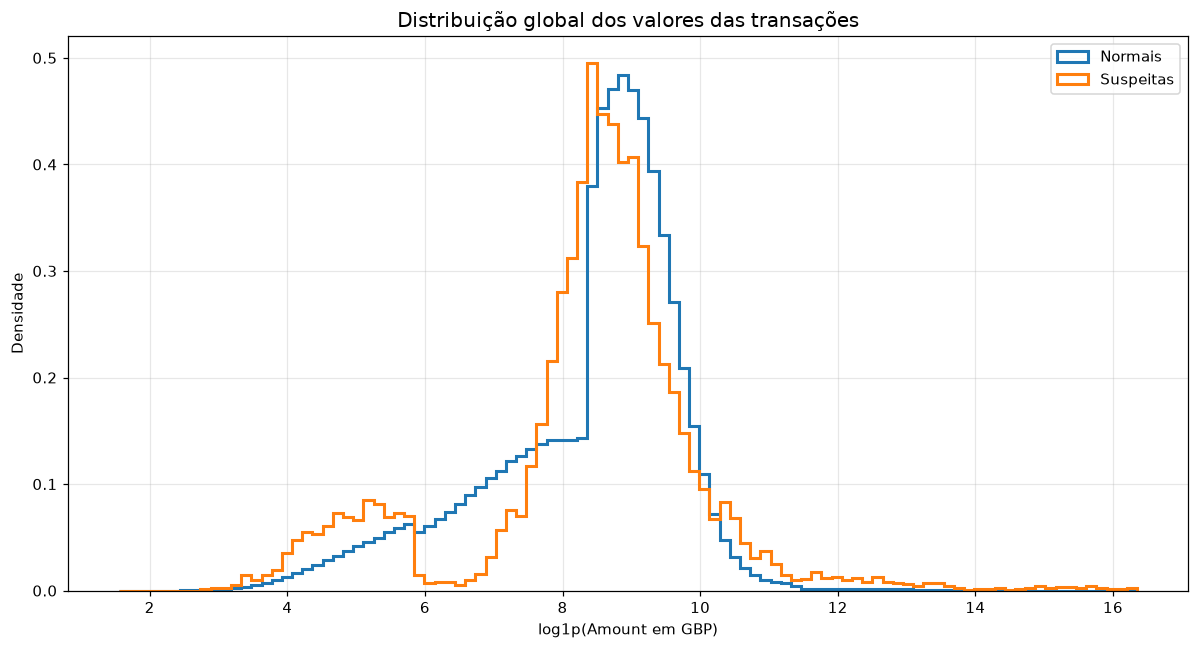


Análise global concluída!


In [8]:
# ============================================================
# 5.3.1 DISTRIBUIÇÃO GLOBAL DOS VALORES
# ============================================================

print("=== DISTRIBUIÇÃO GLOBAL DE AMOUNT ===")

# Estatísticas por classe
grupo = df.groupby("Is_laundering")["Amount"]

resumo_global = grupo.agg(
    transacoes="size",
    media="mean",
    minimo="min",
    maximo="max"
)

# Calcular percentis
percentis = grupo.quantile(
    [0.50, 0.90, 0.95, 0.99]
).unstack()

percentis.columns = [
    "mediana",
    "p90",
    "p95",
    "p99"
]

resumo_global = resumo_global.join(percentis)

resumo_global.index = [
    "Normal",
    "Suspeita"
]

print("\n=== ESTATÍSTICAS POR CLASSIFICAÇÃO ===")

display(resumo_global.round(2))


# ============================================================
# TRANSFORMAÇÃO LOGARÍTMICA
# ============================================================

log_amount_global = np.log1p(
    df["Amount"].to_numpy(dtype=np.float32)
)

labels = df["Is_laundering"].to_numpy()


# ============================================================
# HISTOGRAMA GLOBAL
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

# Utilizar intervalos iguais para as duas classes
bins = np.histogram_bin_edges(
    log_amount_global,
    bins=100
)

for classe, nome in [
    (0, "Normais"),
    (1, "Suspeitas")
]:

    valores = log_amount_global[
        labels == classe
    ]

    ax.hist(
        valores,
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2,
        label=nome
    )


ax.set_title(
    "Distribuição global dos valores das transações",
    fontsize=13
)

ax.set_xlabel("log1p(Amount em GBP)")
ax.set_ylabel("Densidade")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\nAnálise global concluída!")

Conclusão da análise dos valores financeiros

A distribuição dos valores apresenta sobreposição significativa entre transações normais e suspeitas. A mediana das operações suspeitas é inferior à das operações normais, demonstrando que movimentações suspeitas não estão necessariamente associadas a valores elevados.

Entretanto, os percentis superiores apresentam diferenças expressivas. O percentil 99 das operações suspeitas alcança £419.540,08, contra £44.938,16 nas operações normais.

Esses resultados indicam que valores financeiros podem contribuir para a identificação de operações suspeitas, principalmente quando combinados com outras características comportamentais e temporais.

Para a modelagem, será mantida a transformação logarítmica dos valores, complementada por estatísticas agregadas das janelas.

5.4 DISTRIBUIÇÃO DOS TIPOS DE PAGAMENTO

Esta investigação busca identificar a frequência das modalidades de pagamento e verificar possíveis associações entre cada modalidade e a ocorrência de transações suspeitas.

Serão analisadas tanto a quantidade absoluta de operações suspeitas quanto a proporção de suspeitas dentro de cada modalidade.

=== DISTRIBUIÇÃO DOS TIPOS DE PAGAMENTO ===

=== ESTATÍSTICAS POR TIPO DE PAGAMENTO ===


,total_transacoes,transacoes_suspeitas,transacoes_normais,participacao_dataset,taxa_suspeitas,participacao_suspeitas
Payment_type,,,,,,
Credit card,2012909,1136,2011773,21.1777,0.0564,11.5061
Debit card,2012103,1124,2010979,21.1692,0.0559,11.3846
Cheque,2011419,1087,2010332,21.1620,0.0540,11.0098
ACH,2008807,1159,2007648,21.1345,0.0577,11.7391
Cross-border,933931,2628,931303,9.8258,0.2814,26.6180
Cash Withdrawal,300477,1334,299143,3.1613,0.4440,13.5116
Cash Deposit,225206,1405,223801,2.3694,0.6239,14.2307


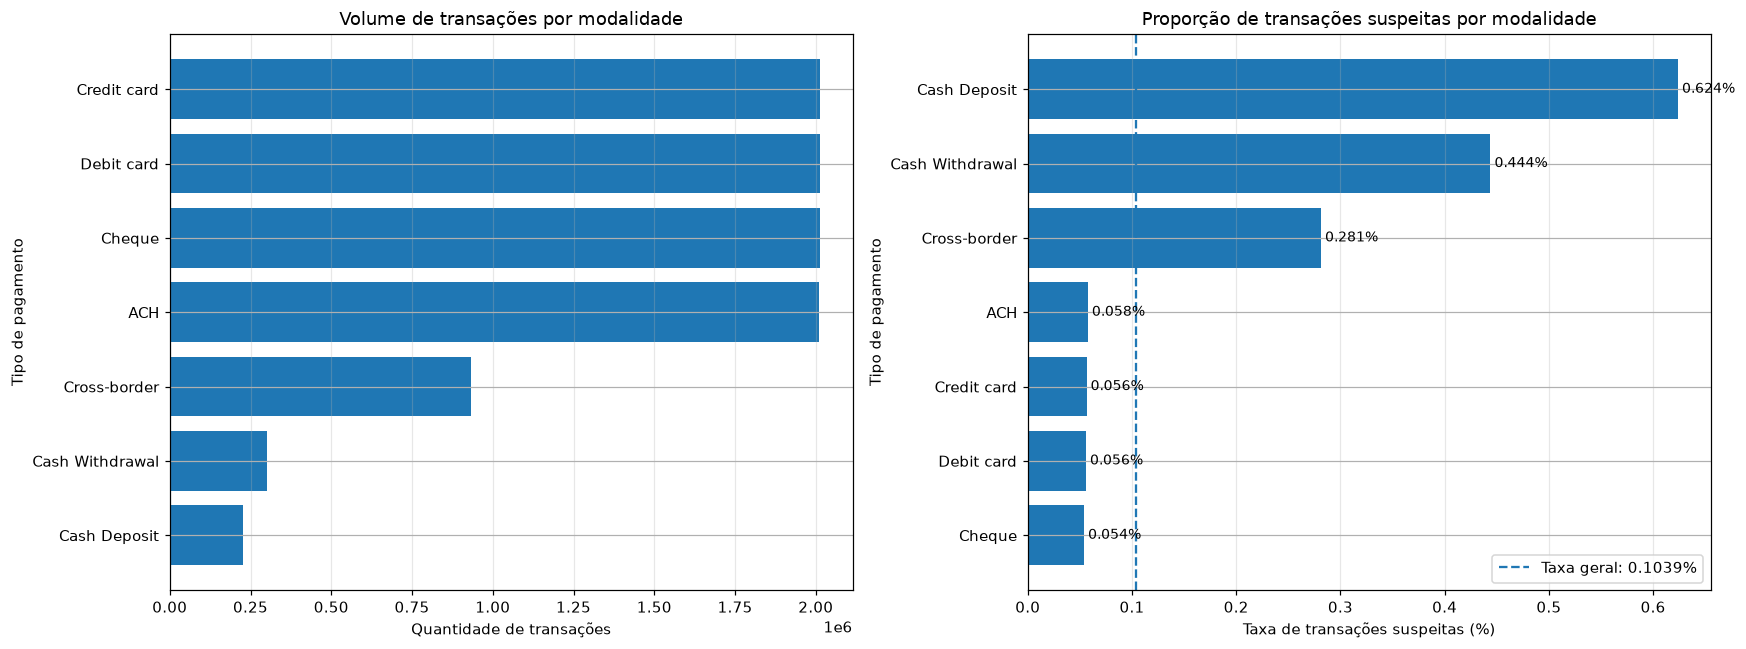


=== RANKING POR TAXA DE SUSPEITAS ===


,total_transacoes,transacoes_suspeitas,taxa_suspeitas,participacao_suspeitas
Payment_type,,,,
Cash Deposit,225206,1405,0.6239,14.2307
Cash Withdrawal,300477,1334,0.4440,13.5116
Cross-border,933931,2628,0.2814,26.6180
ACH,2008807,1159,0.0577,11.7391
Credit card,2012909,1136,0.0564,11.5061
Debit card,2012103,1124,0.0559,11.3846
Cheque,2011419,1087,0.0540,11.0098



Análise dos tipos de pagamento concluída!


In [9]:
# ============================================================
# 5.4 ANÁLISE DOS TIPOS DE PAGAMENTO
# ============================================================

print("=== DISTRIBUIÇÃO DOS TIPOS DE PAGAMENTO ===")


# ============================================================
# 1. AGRUPAMENTO POR TIPO DE PAGAMENTO
# ============================================================

resumo_pagamentos = (
    df.groupby(
        "Payment_type",
        observed=True
    )
    .agg(
        total_transacoes=("Is_laundering", "size"),
        transacoes_suspeitas=("Is_laundering", "sum")
    )
)

resumo_pagamentos["transacoes_normais"] = (
    resumo_pagamentos["total_transacoes"]
    - resumo_pagamentos["transacoes_suspeitas"]
)

# Percentual de participação no dataset
resumo_pagamentos["participacao_dataset"] = (
    resumo_pagamentos["total_transacoes"]
    / len(df) * 100
)

# Taxa de suspeitas dentro de cada modalidade
resumo_pagamentos["taxa_suspeitas"] = (
    resumo_pagamentos["transacoes_suspeitas"]
    / resumo_pagamentos["total_transacoes"] * 100
)

# Participação de cada modalidade no total de suspeitas
resumo_pagamentos["participacao_suspeitas"] = (
    resumo_pagamentos["transacoes_suspeitas"]
    / df["Is_laundering"].sum() * 100
)

resumo_pagamentos = resumo_pagamentos.sort_values(
    "total_transacoes",
    ascending=False
)


# ============================================================
# 2. TABELA GERAL
# ============================================================

print("\n=== ESTATÍSTICAS POR TIPO DE PAGAMENTO ===")

display(
    resumo_pagamentos.round(4)
)


# ============================================================
# 3. GRÁFICO DE VOLUME DE TRANSAÇÕES
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6)
)

volume = resumo_pagamentos.sort_values(
    "total_transacoes"
)

axes[0].barh(
    volume.index.astype(str),
    volume["total_transacoes"]
)

axes[0].set_title(
    "Volume de transações por modalidade"
)

axes[0].set_xlabel("Quantidade de transações")
axes[0].set_ylabel("Tipo de pagamento")

axes[0].grid(
    axis="x",
    alpha=0.3
)


# ============================================================
# 4. GRÁFICO DA TAXA DE SUSPEITAS
# ============================================================

taxas = resumo_pagamentos.sort_values(
    "taxa_suspeitas"
)

barras = axes[1].barh(
    taxas.index.astype(str),
    taxas["taxa_suspeitas"]
)

# Taxa geral de suspeitas como referência
taxa_geral = df["Is_laundering"].mean() * 100

axes[1].axvline(
    taxa_geral,
    linestyle="--",
    label=f"Taxa geral: {taxa_geral:.4f}%"
)

axes[1].set_title(
    "Proporção de transações suspeitas por modalidade"
)

axes[1].set_xlabel("Taxa de transações suspeitas (%)")
axes[1].set_ylabel("Tipo de pagamento")

axes[1].legend()
axes[1].grid(
    axis="x",
    alpha=0.3
)

# Mostrar valores nas barras
for barra, valor in zip(
    barras,
    taxas["taxa_suspeitas"]
):

    axes[1].text(
        valor,
        barra.get_y() + barra.get_height() / 2,
        f" {valor:.3f}%",
        va="center",
        fontsize=9
    )


plt.tight_layout()
plt.show()


# ============================================================
# 5. RANKING DAS MODALIDADES POR TAXA DE SUSPEITAS
# ============================================================

print("\n=== RANKING POR TAXA DE SUSPEITAS ===")

ranking_pagamentos = (
    resumo_pagamentos[
        [
            "total_transacoes",
            "transacoes_suspeitas",
            "taxa_suspeitas",
            "participacao_suspeitas"
        ]
    ]
    .sort_values(
        "taxa_suspeitas",
        ascending=False
    )
)

display(
    ranking_pagamentos.round(4)
)

print("\nAnálise dos tipos de pagamento concluída!")

5.5 ANÁLISE TEMPORAL DAS TRANSAÇÕES

O objetivo desta investigação é compreender como as movimentações financeiras se distribuem ao longo do dia e da semana.

Serão comparadas a frequência das transações e a proporção de operações suspeitas em cada período, buscando identificar possíveis padrões temporais associados à variável-alvo.

=== ANÁLISE TEMPORAL ===


C:\Users\Aluno\AppData\Local\Temp\ipykernel_9864\748416439.py:15: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  .dt.dayofweek


Horas distintas: 24
Dias da semana: 7

=== DISTRIBUIÇÃO POR HORÁRIO ===


,total_transacoes,suspeitas,normais,taxa_suspeitas
hour,,,,
0,121548,136,121412,0.1119
1,121964,122,121842,0.1000
2,121627,138,121489,0.1135
3,121282,138,121144,0.1138
4,121568,126,121442,0.1036
5,122114,140,121974,0.1146
6,121484,146,121338,0.1202
7,142497,222,142275,0.1558
8,538992,632,538360,0.1173



=== DISTRIBUIÇÃO POR DIA DA SEMANA ===


,total_transacoes,suspeitas,normais,taxa_suspeitas
Segunda-feira,1389246,1472,1387774,0.1060
Terça-feira,1369343,1424,1367919,0.1040
Quarta-feira,1366034,1433,1364601,0.1049
Quinta-feira,1350706,1455,1349251,0.1077
Sexta-feira,1369872,1483,1368389,0.1083
Sábado,1336623,1310,1335313,0.0980
Domingo,1323028,1296,1321732,0.0980


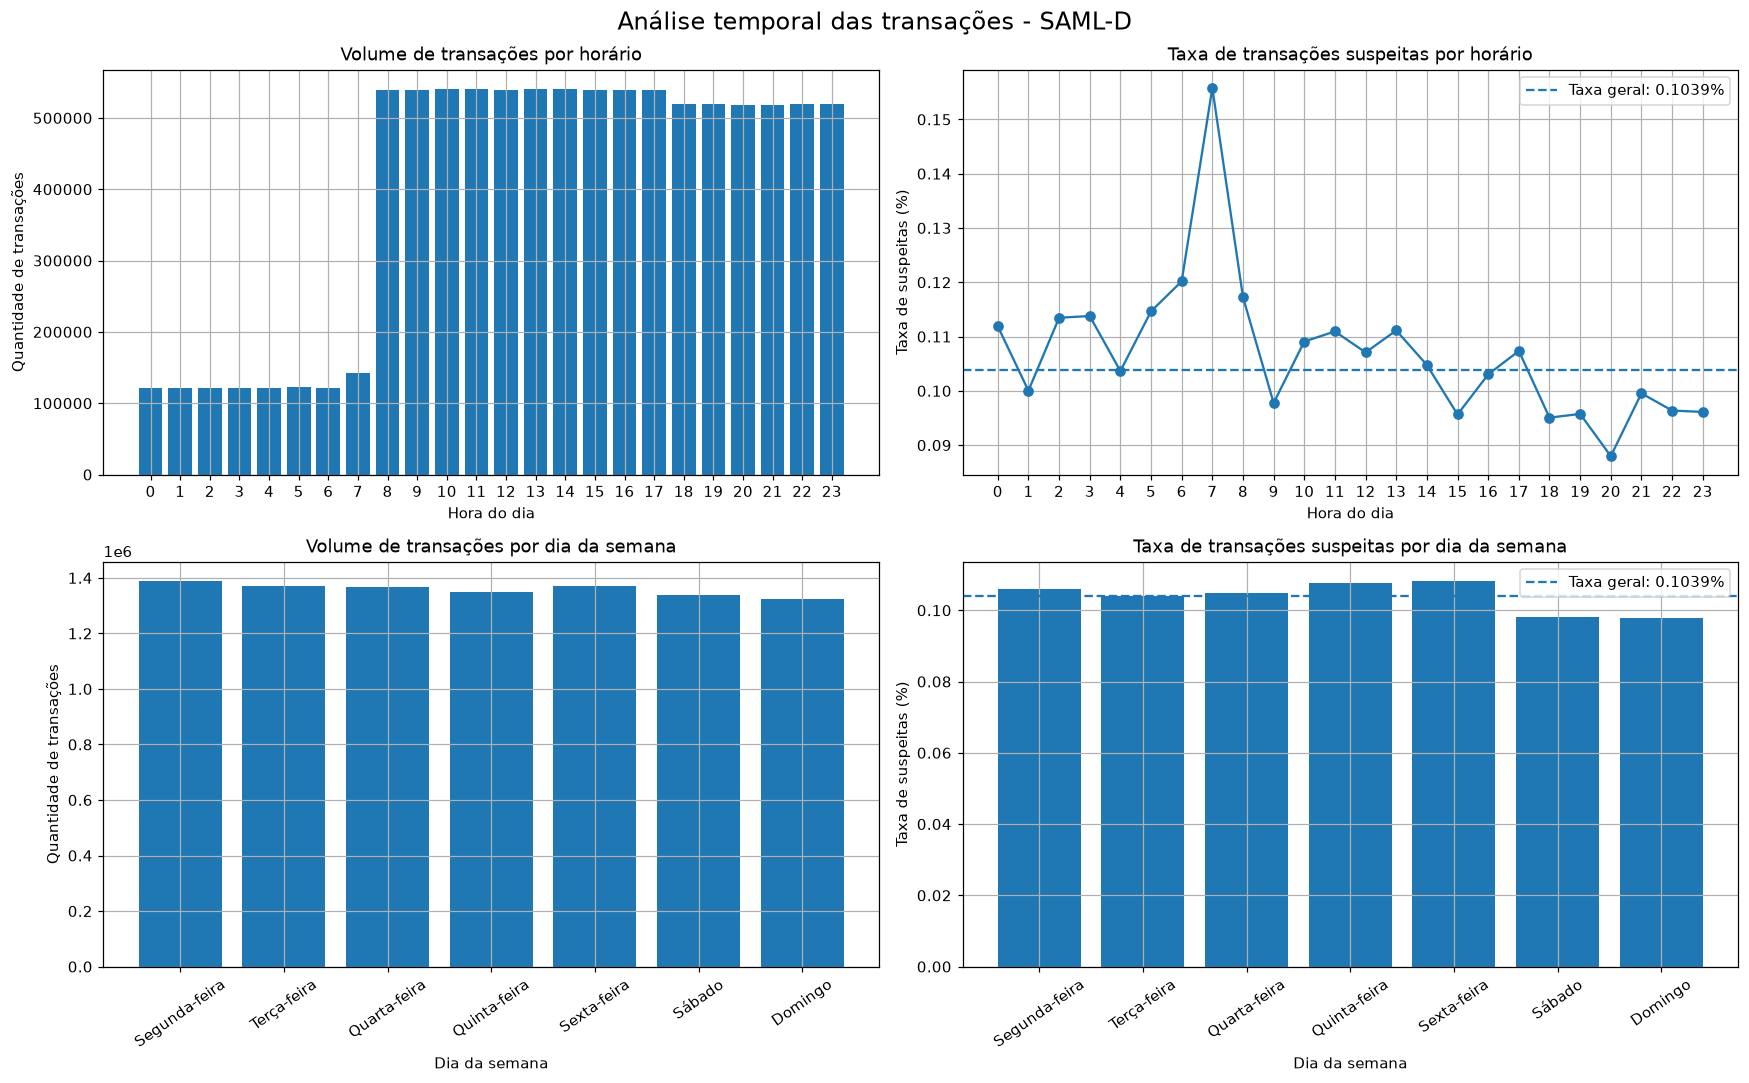


=== HORÁRIOS COM MAIOR TAXA DE SUSPEITAS ===


,total_transacoes,suspeitas,normais,taxa_suspeitas
hour,,,,
7,142497,222,142275,0.1558
6,121484,146,121338,0.1202
8,538992,632,538360,0.1173
5,122114,140,121974,0.1146
3,121282,138,121144,0.1138
2,121627,138,121489,0.1135
0,121548,136,121412,0.1119
13,540796,601,540195,0.1111
11,539901,599,539302,0.1109



=== DIAS COM MAIOR TAXA DE SUSPEITAS ===


,total_transacoes,suspeitas,normais,taxa_suspeitas
Sexta-feira,1369872,1483,1368389,0.1083
Quinta-feira,1350706,1455,1349251,0.1077
Segunda-feira,1389246,1472,1387774,0.1060
Quarta-feira,1366034,1433,1364601,0.1049
Terça-feira,1369343,1424,1367919,0.1040
Sábado,1336623,1310,1335313,0.0980
Domingo,1323028,1296,1321732,0.0980



Análise temporal concluída!


In [10]:
# ============================================================
# 5.5 ANÁLISE TEMPORAL DAS TRANSAÇÕES
# ============================================================

print("=== ANÁLISE TEMPORAL ===")

# ============================================================
# 1. EXTRAIR HORA E DIA DA SEMANA
# ============================================================

df["hour"] = df["timestamp"].dt.hour.astype("int8")

df["weekday"] = (
    df["timestamp"]
    .dt.dayofweek
    .astype("int8")
)

dias_semana = [
    "Segunda-feira",
    "Terça-feira",
    "Quarta-feira",
    "Quinta-feira",
    "Sexta-feira",
    "Sábado",
    "Domingo"
]

print("Horas distintas:", df["hour"].nunique())

print("Dias da semana:", df["weekday"].nunique())


# ============================================================
# 2. AGRUPAR TRANSAÇÕES POR HORA
# ============================================================

resumo_horario = (
    df.groupby("hour", observed=True)
    .agg(
        total_transacoes=("Is_laundering", "size"),
        suspeitas=("Is_laundering", "sum")
    )
)

resumo_horario["normais"] = (
    resumo_horario["total_transacoes"]
    - resumo_horario["suspeitas"]
)

resumo_horario["taxa_suspeitas"] = (
    resumo_horario["suspeitas"]
    / resumo_horario["total_transacoes"] * 100
)

# Garantir todas as 24 horas
resumo_horario = resumo_horario.reindex(
    range(24),
    fill_value=0
)

print("\n=== DISTRIBUIÇÃO POR HORÁRIO ===")

display(resumo_horario.round(4))


# ============================================================
# 3. AGRUPAR TRANSAÇÕES POR DIA DA SEMANA
# ============================================================

resumo_semana = (
    df.groupby("weekday", observed=True)
    .agg(
        total_transacoes=("Is_laundering", "size"),
        suspeitas=("Is_laundering", "sum")
    )
)

resumo_semana["normais"] = (
    resumo_semana["total_transacoes"]
    - resumo_semana["suspeitas"]
)

resumo_semana["taxa_suspeitas"] = (
    resumo_semana["suspeitas"]
    / resumo_semana["total_transacoes"] * 100
)

# Garantir todos os dias
resumo_semana = resumo_semana.reindex(
    range(7),
    fill_value=0
)

resumo_semana.index = dias_semana

print("\n=== DISTRIBUIÇÃO POR DIA DA SEMANA ===")

display(resumo_semana.round(4))


# ============================================================
# 4. GRÁFICOS DE ANÁLISE TEMPORAL
# ============================================================

taxa_geral = df["Is_laundering"].mean() * 100

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10)
)

# ------------------------------------------------------------
# GRÁFICO 1 - VOLUME POR HORA
# ------------------------------------------------------------

axes[0, 0].bar(
    resumo_horario.index,
    resumo_horario["total_transacoes"]
)

axes[0, 0].set_title(
    "Volume de transações por horário"
)

axes[0, 0].set_xlabel("Hora do dia")
axes[0, 0].set_ylabel("Quantidade de transações")

axes[0, 0].set_xticks(range(24))

# ------------------------------------------------------------
# GRÁFICO 2 - TAXA DE SUSPEITAS POR HORA
# ------------------------------------------------------------

axes[0, 1].plot(
    resumo_horario.index,
    resumo_horario["taxa_suspeitas"],
    marker="o"
)

axes[0, 1].axhline(
    taxa_geral,
    linestyle="--",
    label=f"Taxa geral: {taxa_geral:.4f}%"
)

axes[0, 1].set_title(
    "Taxa de transações suspeitas por horário"
)

axes[0, 1].set_xlabel("Hora do dia")
axes[0, 1].set_ylabel("Taxa de suspeitas (%)")

axes[0, 1].set_xticks(range(24))
axes[0, 1].legend()


# ------------------------------------------------------------
# GRÁFICO 3 - VOLUME POR DIA DA SEMANA
# ------------------------------------------------------------

axes[1, 0].bar(
    resumo_semana.index,
    resumo_semana["total_transacoes"]
)

axes[1, 0].set_title(
    "Volume de transações por dia da semana"
)

axes[1, 0].set_xlabel("Dia da semana")
axes[1, 0].set_ylabel("Quantidade de transações")

axes[1, 0].tick_params(
    axis="x",
    rotation=35
)


# ------------------------------------------------------------
# GRÁFICO 4 - TAXA DE SUSPEITAS POR DIA DA SEMANA
# ------------------------------------------------------------

axes[1, 1].bar(
    resumo_semana.index,
    resumo_semana["taxa_suspeitas"]
)

axes[1, 1].axhline(
    taxa_geral,
    linestyle="--",
    label=f"Taxa geral: {taxa_geral:.4f}%"
)

axes[1, 1].set_title(
    "Taxa de transações suspeitas por dia da semana"
)

axes[1, 1].set_xlabel("Dia da semana")
axes[1, 1].set_ylabel("Taxa de suspeitas (%)")

axes[1, 1].tick_params(
    axis="x",
    rotation=35
)

axes[1, 1].legend()


# ------------------------------------------------------------
# FINALIZAÇÃO
# ------------------------------------------------------------

fig.suptitle(
    "Análise temporal das transações - SAML-D",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ============================================================
# 5. IDENTIFICAR OS PERÍODOS COM MAIOR TAXA
# ============================================================

print("\n=== HORÁRIOS COM MAIOR TAXA DE SUSPEITAS ===")

display(
    resumo_horario.sort_values(
        "taxa_suspeitas",
        ascending=False
    ).head(10).round(4)
)

print("\n=== DIAS COM MAIOR TAXA DE SUSPEITAS ===")

display(
    resumo_semana.sort_values(
        "taxa_suspeitas",
        ascending=False
    ).round(4)
)

print("\nAnálise temporal concluída!")

Conclusão da análise temporal

A distribuição das transações apresenta diferenças de volume entre os horários, com uma concentração significativamente maior entre 08h e 23h. O horário das 07h apresentou a maior taxa de transações suspeitas, de 0,1558%, aproximadamente 1,5 vez a taxa geral.

Em relação aos dias da semana, sexta-feira apresentou a maior taxa de suspeitas (0,1083%), enquanto sábado e domingo apresentaram as menores taxas (0,0980%).

Os resultados indicam que as características temporais podem contribuir para a identificação de padrões suspeitos, especialmente quando combinadas com informações financeiras e comportamentais.

Entretanto, as diferenças observadas devem ser interpretadas como associações presentes no dataset, sem estabelecer relações causais.

5.6 EVOLUÇÃO TEMPORAL DAS TRANSAÇÕES

Esta análise investiga a evolução das transações e das operações suspeitas durante todo o período do dataset. Serão utilizadas agregações diárias e mensais, além de uma média móvel ponderada de sete dias para facilitar a identificação de tendências.

=== EVOLUÇÃO TEMPORAL ===

=== RESUMO DIÁRIO ===


,total_transacoes,suspeitas,normais,taxa_suspeitas,taxa_7d
count,321.0000,321.0000,321.0000,321.0000,315.0000
mean,29610.1308,30.7570,29579.3738,0.1040,0.1035
std,2288.1291,10.2994,2286.2860,0.0343,0.0276
min,8400.0000,7.0000,8393.0000,0.0348,0.0550
25%,28506.0000,22.0000,28469.0000,0.0759,0.0805
50%,29491.0000,30.0000,29459.0000,0.1028,0.1048
75%,30739.0000,39.0000,30709.0000,0.1285,0.1252
max,36645.0000,59.0000,36597.0000,0.2033,0.1618



=== RESUMO MENSAL ===


,total_transacoes,suspeitas,normais,taxa_suspeitas
mes,,,,
2022-10,708654,694,707960,0.0979
2022-11,897621,794,896827,0.0885
2022-12,900341,907,899434,0.1007
2023-01,908320,940,907380,0.1035
2023-02,904806,946,903860,0.1046
2023-03,908562,927,907635,0.1020
2023-04,902883,962,901921,0.1065
2023-05,917601,866,916735,0.0944
2023-06,897243,1024,896219,0.1141


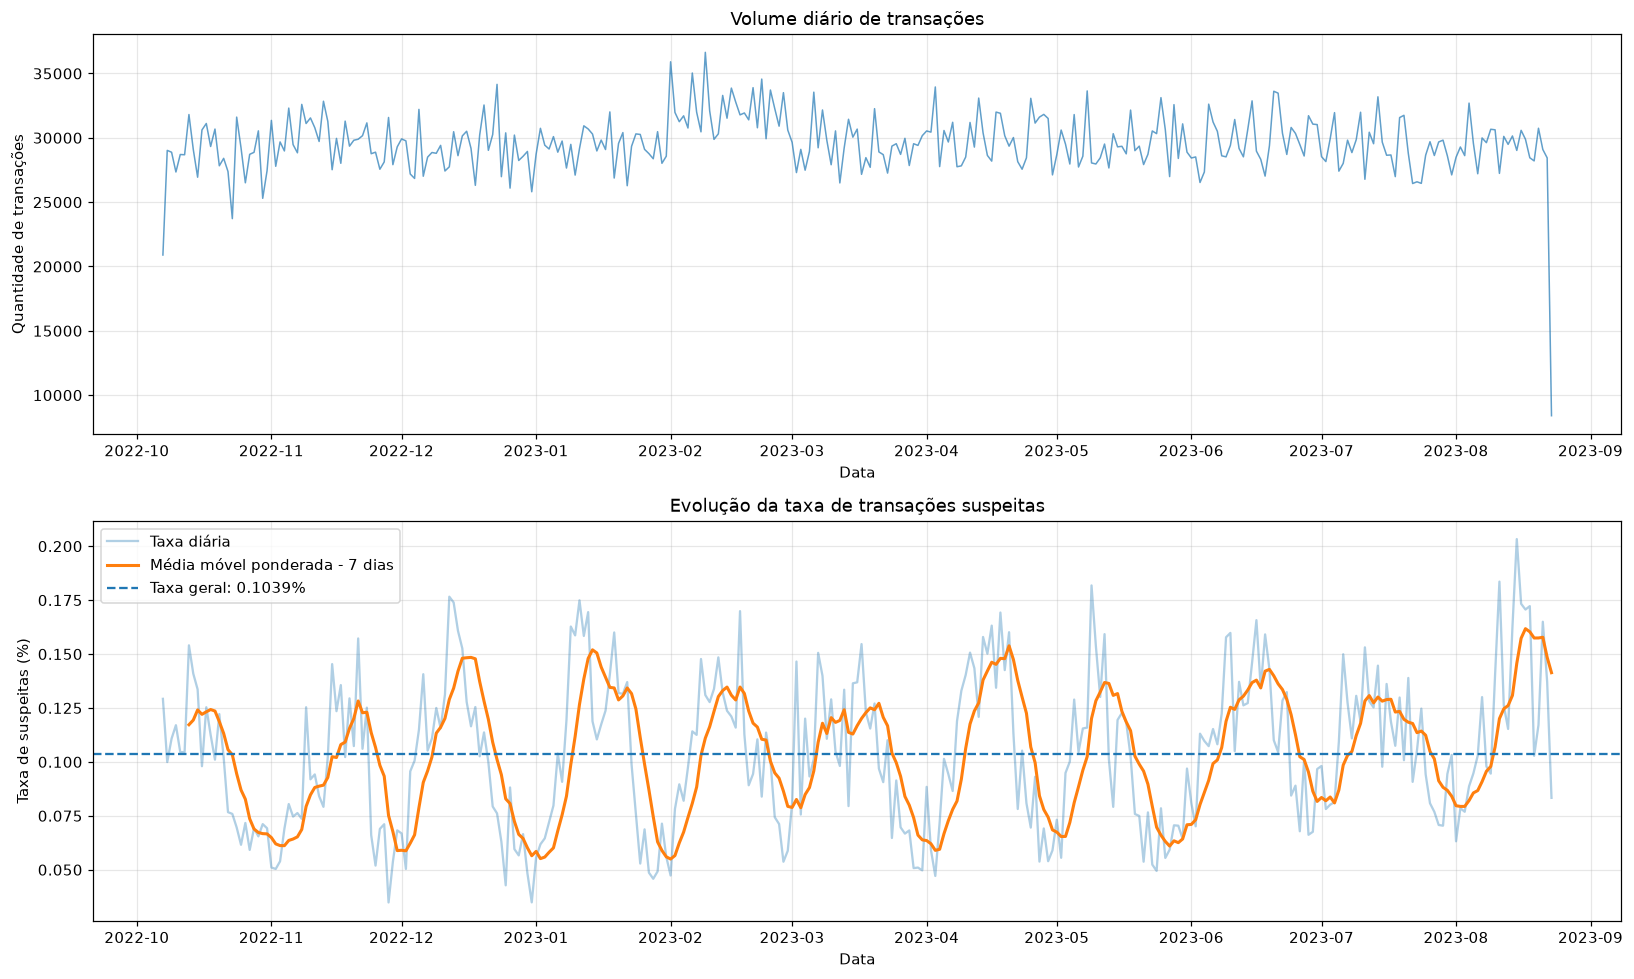

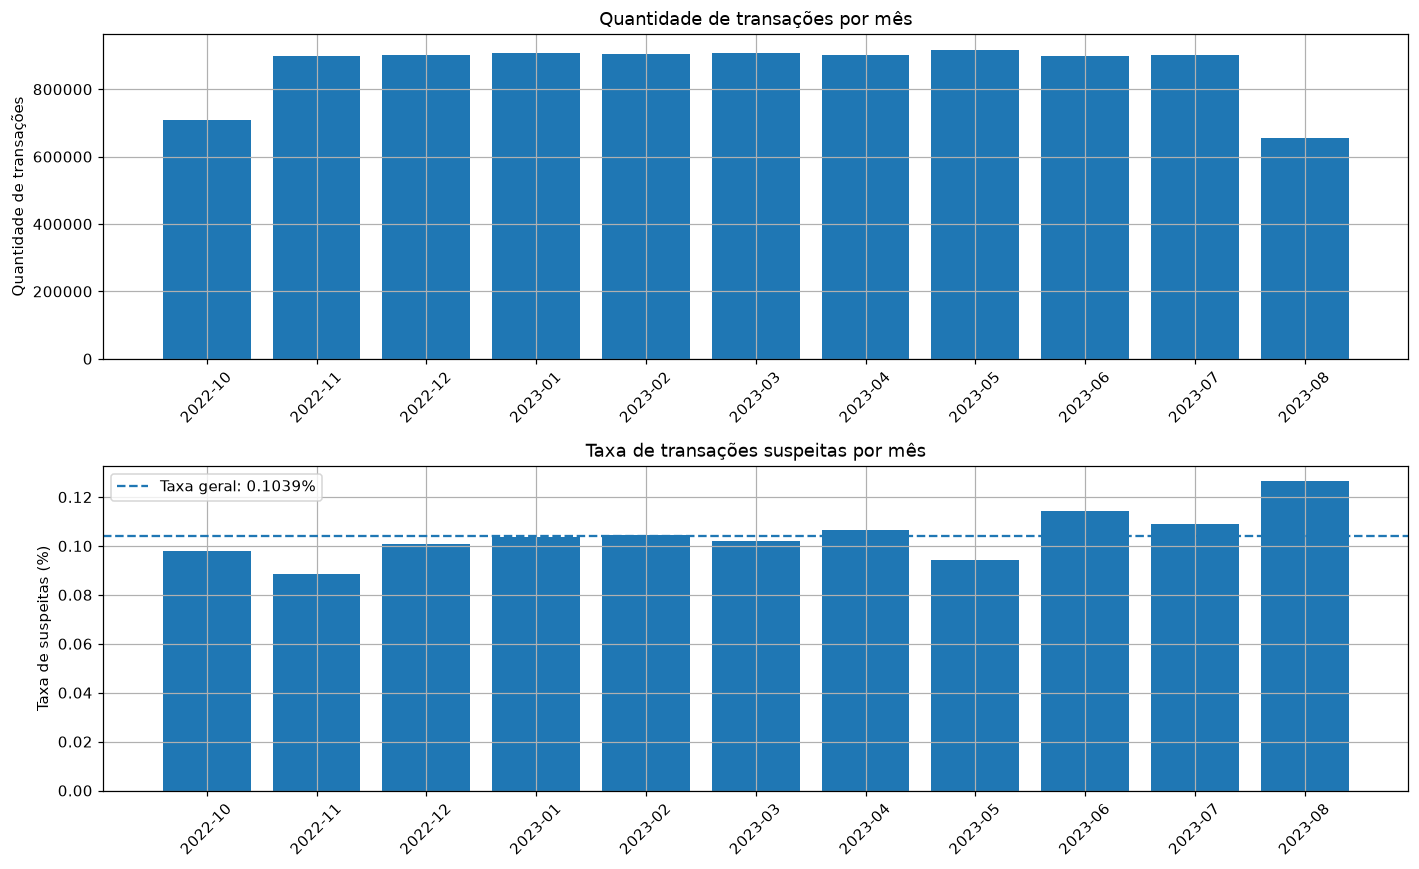


=== RANKING MENSAL ===


,total_transacoes,suspeitas,normais,taxa_suspeitas
mes,,,,
2023-08,656582,830,655752,0.1264
2023-06,897243,1024,896219,0.1141
2023-07,902239,983,901256,0.1090
2023-04,902883,962,901921,0.1065
2023-02,904806,946,903860,0.1046
2023-01,908320,940,907380,0.1035
2023-03,908562,927,907635,0.1020
2022-12,900341,907,899434,0.1007
2022-10,708654,694,707960,0.0979



Análise da evolução temporal concluída!


In [11]:
# ============================================================
# 5.6 EVOLUÇÃO TEMPORAL DAS TRANSAÇÕES
# ============================================================

print("=== EVOLUÇÃO TEMPORAL ===")


# ============================================================
# 1. AGREGAÇÃO DIÁRIA
# ============================================================

df["data"] = df["timestamp"].dt.floor("D")

resumo_diario = (
    df.groupby("data")
    .agg(
        total_transacoes=("Is_laundering", "size"),
        suspeitas=("Is_laundering", "sum")
    )
)

# Garantir calendário contínuo
calendario = pd.date_range(
    start=resumo_diario.index.min(),
    end=resumo_diario.index.max(),
    freq="D"
)

resumo_diario = resumo_diario.reindex(
    calendario,
    fill_value=0
)

resumo_diario.index.name = "data"

resumo_diario["normais"] = (
    resumo_diario["total_transacoes"]
    - resumo_diario["suspeitas"]
)

resumo_diario["taxa_suspeitas"] = (
    resumo_diario["suspeitas"]
    / resumo_diario["total_transacoes"].replace(0, np.nan)
    * 100
)

# Média móvel ponderada: soma das suspeitas / soma das transações
resumo_diario["taxa_7d"] = (
    resumo_diario["suspeitas"].rolling(7).sum()
    / resumo_diario["total_transacoes"].rolling(7).sum()
    * 100
)

print("\n=== RESUMO DIÁRIO ===")

display(
    resumo_diario.describe().round(4)
)


# ============================================================
# 2. AGREGAÇÃO MENSAL
# ============================================================

df["mes"] = df["timestamp"].dt.to_period("M")

resumo_mensal = (
    df.groupby("mes")
    .agg(
        total_transacoes=("Is_laundering", "size"),
        suspeitas=("Is_laundering", "sum")
    )
)

resumo_mensal["normais"] = (
    resumo_mensal["total_transacoes"]
    - resumo_mensal["suspeitas"]
)

resumo_mensal["taxa_suspeitas"] = (
    resumo_mensal["suspeitas"]
    / resumo_mensal["total_transacoes"]
    * 100
)

print("\n=== RESUMO MENSAL ===")

display(
    resumo_mensal.round(4)
)


# ============================================================
# 3. GRÁFICOS DIÁRIOS
# ============================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(15, 9)
)

# Volume de transações por dia
axes[0].plot(
    resumo_diario.index,
    resumo_diario["total_transacoes"],
    alpha=0.7,
    linewidth=1
)

axes[0].set_title(
    "Volume diário de transações"
)

axes[0].set_xlabel("Data")
axes[0].set_ylabel("Quantidade de transações")

axes[0].grid(alpha=0.3)


# Taxa diária e média móvel
axes[1].plot(
    resumo_diario.index,
    resumo_diario["taxa_suspeitas"],
    alpha=0.35,
    label="Taxa diária"
)

axes[1].plot(
    resumo_diario.index,
    resumo_diario["taxa_7d"],
    linewidth=2,
    label="Média móvel ponderada - 7 dias"
)

taxa_geral = df["Is_laundering"].mean() * 100

axes[1].axhline(
    taxa_geral,
    linestyle="--",
    label=f"Taxa geral: {taxa_geral:.4f}%"
)

axes[1].set_title(
    "Evolução da taxa de transações suspeitas"
)

axes[1].set_xlabel("Data")
axes[1].set_ylabel("Taxa de suspeitas (%)")

axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 4. GRÁFICOS MENSAIS
# ============================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(13, 8)
)

meses = resumo_mensal.index.astype(str)

# Volume mensal
axes[0].bar(
    meses,
    resumo_mensal["total_transacoes"]
)

axes[0].set_title(
    "Quantidade de transações por mês"
)

axes[0].set_ylabel("Quantidade de transações")
axes[0].tick_params(axis="x", rotation=45)


# Taxa mensal
axes[1].bar(
    meses,
    resumo_mensal["taxa_suspeitas"]
)

axes[1].axhline(
    taxa_geral,
    linestyle="--",
    label=f"Taxa geral: {taxa_geral:.4f}%"
)

axes[1].set_title(
    "Taxa de transações suspeitas por mês"
)

axes[1].set_ylabel("Taxa de suspeitas (%)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()


# ============================================================
# 5. IDENTIFICAR OS MESES COM MAIOR INCIDÊNCIA
# ============================================================

print("\n=== RANKING MENSAL ===")

display(
    resumo_mensal.sort_values(
        "taxa_suspeitas",
        ascending=False
    ).round(4)
)

print("\nAnálise da evolução temporal concluída!")

5.7 ANÁLISE DO COMPORTAMENTO DAS CONTAS

Esta investigação busca compreender como as transações financeiras estão distribuídas entre as contas do dataset.

Serão analisadas separadamente as atividades como remetente e destinatário, além da quantidade total de eventos associados a cada conta.

O objetivo é identificar padrões de concentração e compreender a quantidade de histórico disponível para a construção de sequências comportamentais.

ANÁLISE COMPORTAMENTAL DAS CONTAS

=== 1. FREQUÊNCIA DE MOVIMENTAÇÕES ===
Contas como remetentes: 292,715
Contas como destinatárias: 652,266
Contas presentes nos dois papéis: 89,521
Total de contas distintas: 855,460

=== DISTRIBUIÇÃO DAS MOVIMENTAÇÕES ===


,Como remetente,Como destinatário,Movimentações totais
Contas distintas,292715.00,652266.00,855460.00
Média,32.47,14.57,22.22
Mediana,12.00,13.00,12.00
Percentil 90,14.00,18.00,17.00
Percentil 95,233.00,21.00,21.00
Percentil 99,506.00,191.00,522.00
Máximo,754.00,751.00,1498.00
Contas com 1 evento,27816.00,92413.00,48621.00



=== CONCENTRAÇÃO DE ATIVIDADE ===


,Grupo de contas,Quantidade de contas,Eventos concentrados,Participação dos eventos (%)
0,Top 1%,8555,5746607,30.23
1,Top 5%,42773,10359093,54.49
2,Top 10%,85546,11164969,58.73



=== CONTAS ENVOLVIDAS EM OPERAÇÕES SUSPEITAS ===
Contas remetentes em transações suspeitas: 4,950
Contas destinatárias em transações suspeitas: 4,074
Total de contas distintas envolvidas: 7,902
Participação sobre todas as contas: 0.92%

=== HISTÓRICO DISPONÍVEL POR CONTA ===
Contas com pelo menos 10 eventos: 617,878
Janelas completas de 10 eventos: 1,607,407
Eventos aproveitados nas janelas: 16,074,070
Cobertura dos eventos: 84.56%

Observação: esta é uma estimativa sobre o histórico completo, antes da separação temporal.

=== VISUALIZAÇÃO DA FREQUÊNCIA POR CONTA ===


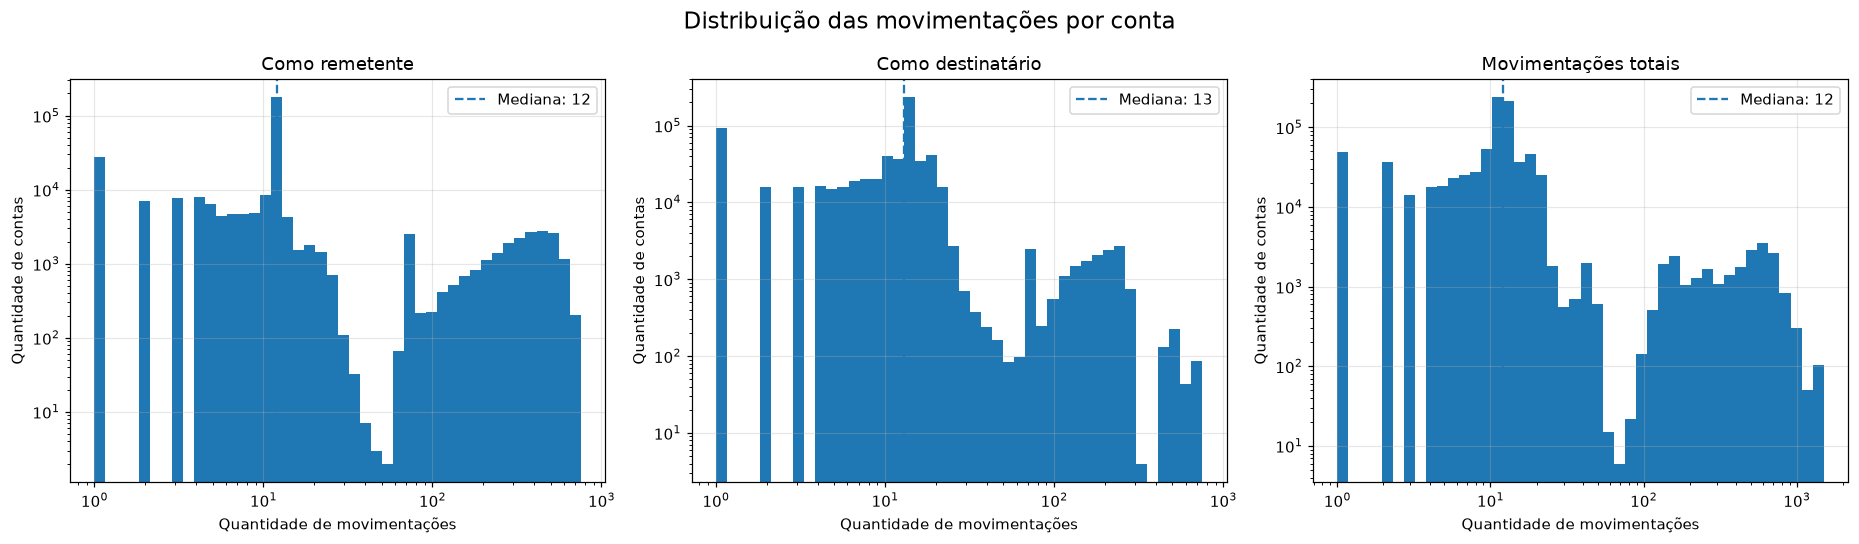


Análise comportamental concluída!


In [12]:
# ============================================================
# 5.7 ANÁLISE COMPORTAMENTAL DAS CONTAS
# ============================================================

print("=" * 65)
print("ANÁLISE COMPORTAMENTAL DAS CONTAS")
print("=" * 65)


# ============================================================
# 1. QUANTIDADE DE TRANSAÇÕES POR CONTA
# ============================================================

print("\n=== 1. FREQUÊNCIA DE MOVIMENTAÇÕES ===")

# Quantidade de vezes que cada conta aparece como remetente
contagem_envios = (
    df.groupby("Sender_account", sort=False)
    .size()
    .rename_axis("account_id")
)

# Quantidade de vezes que cada conta aparece como destinatária
contagem_recebimentos = (
    df.groupby("Receiver_account", sort=False)
    .size()
    .rename_axis("account_id")
)

# Combinar as movimentações dos dois papéis
contagem_eventos = (
    pd.concat([
        contagem_envios,
        contagem_recebimentos
    ])
    .groupby(level=0, sort=False)
    .sum()
)

# Identificar as contas distintas
contas_remetentes = pd.Index(contagem_envios.index)
contas_destinatarias = pd.Index(contagem_recebimentos.index)

contas_comuns = contas_remetentes.intersection(
    contas_destinatarias
)

contas_distintas = contas_remetentes.union(
    contas_destinatarias
)

print("Contas como remetentes:", f"{len(contas_remetentes):,}")

print(
    "Contas como destinatárias:",
    f"{len(contas_destinatarias):,}"
)

print(
    "Contas presentes nos dois papéis:",
    f"{len(contas_comuns):,}"
)

print(
    "Total de contas distintas:",
    f"{len(contas_distintas):,}"
)


# ============================================================
# 2. ESTATÍSTICAS DE MOVIMENTAÇÃO POR CONTA
# ============================================================

def resumir_movimentacoes(serie):

    return {
        "Contas distintas": len(serie),
        "Média": serie.mean(),
        "Mediana": serie.median(),
        "Percentil 90": serie.quantile(0.90),
        "Percentil 95": serie.quantile(0.95),
        "Percentil 99": serie.quantile(0.99),
        "Máximo": serie.max(),
        "Contas com 1 evento": (serie == 1).sum()
    }


resumo_contas = pd.DataFrame({

    "Como remetente": resumir_movimentacoes(
        contagem_envios
    ),

    "Como destinatário": resumir_movimentacoes(
        contagem_recebimentos
    ),

    "Movimentações totais": resumir_movimentacoes(
        contagem_eventos
    )

})

print("\n=== DISTRIBUIÇÃO DAS MOVIMENTAÇÕES ===")

display(
    resumo_contas.round(2)
)


# ============================================================
# 3. CONCENTRAÇÃO DAS MOVIMENTAÇÕES
# ============================================================

print("\n=== CONCENTRAÇÃO DE ATIVIDADE ===")

eventos_ordenados = contagem_eventos.sort_values(
    ascending=False
)

total_eventos = contagem_eventos.sum()

concentracao = []

for percentual in [0.01, 0.05, 0.10]:

    quantidade_contas = max(
        1,
        int(np.ceil(len(eventos_ordenados) * percentual))
    )

    eventos_grupo = eventos_ordenados.iloc[
        :quantidade_contas
    ].sum()

    participacao = (
        eventos_grupo / total_eventos * 100
    )

    concentracao.append({

        "Grupo de contas": f"Top {percentual:.0%}",

        "Quantidade de contas": quantidade_contas,

        "Eventos concentrados": eventos_grupo,

        "Participação dos eventos (%)": participacao

    })


resumo_concentracao = pd.DataFrame(concentracao)

display(
    resumo_concentracao.round(2)
)


# ============================================================
# 4. CONTAS ENVOLVIDAS EM TRANSAÇÕES SUSPEITAS
# ============================================================

print("\n=== CONTAS ENVOLVIDAS EM OPERAÇÕES SUSPEITAS ===")

transacoes_suspeitas = df.loc[
    df["Is_laundering"] == 1,
    ["Sender_account", "Receiver_account"]
]

contas_suspeitas_envio = (
    transacoes_suspeitas["Sender_account"]
    .nunique()
)

contas_suspeitas_recebimento = (
    transacoes_suspeitas["Receiver_account"]
    .nunique()
)

contas_suspeitas = pd.Index(
    pd.concat([
        transacoes_suspeitas["Sender_account"],
        transacoes_suspeitas["Receiver_account"]
    ]).unique()
)

print(
    "Contas remetentes em transações suspeitas:",
    f"{contas_suspeitas_envio:,}"
)

print(
    "Contas destinatárias em transações suspeitas:",
    f"{contas_suspeitas_recebimento:,}"
)

print(
    "Total de contas distintas envolvidas:",
    f"{len(contas_suspeitas):,}"
)

print(
    "Participação sobre todas as contas:",
    f"{len(contas_suspeitas) / len(contas_distintas) * 100:.2f}%"
)


# ============================================================
# 5. POTENCIAL DE CONSTRUÇÃO DE JANELAS
# ============================================================

print("\n=== HISTÓRICO DISPONÍVEL POR CONTA ===")

TAMANHO_JANELA = 10

janelas_teoricas = (
    contagem_eventos // TAMANHO_JANELA
)

total_janelas_teoricas = janelas_teoricas.sum()

eventos_aproveitados = (
    total_janelas_teoricas * TAMANHO_JANELA
)

print(
    "Contas com pelo menos 10 eventos:",
    f"{(contagem_eventos >= 10).sum():,}"
)

print(
    "Janelas completas de 10 eventos:",
    f"{total_janelas_teoricas:,}"
)

print(
    "Eventos aproveitados nas janelas:",
    f"{eventos_aproveitados:,}"
)

print(
    "Cobertura dos eventos:",
    f"{eventos_aproveitados / total_eventos * 100:.2f}%"
)

print(
    "\nObservação: esta é uma estimativa sobre o histórico completo, "
    "antes da separação temporal."
)


# ============================================================
# 6. GRÁFICO DA DISTRIBUIÇÃO DE MOVIMENTAÇÕES
# ============================================================

print("\n=== VISUALIZAÇÃO DA FREQUÊNCIA POR CONTA ===")

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)

series_contas = [
    (contagem_envios, "Como remetente"),
    (contagem_recebimentos, "Como destinatário"),
    (contagem_eventos, "Movimentações totais")
]

for ax, (serie, titulo) in zip(
    axes,
    series_contas
):

    bins = np.logspace(
        0,
        np.log10(serie.max()),
        45
    )

    ax.hist(
        serie,
        bins=bins
    )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.axvline(
        serie.median(),
        linestyle="--",
        label=f"Mediana: {serie.median():.0f}"
    )

    ax.set_title(titulo)
    ax.set_xlabel("Quantidade de movimentações")
    ax.set_ylabel("Quantidade de contas")

    ax.legend()
    ax.grid(alpha=0.3)


plt.suptitle(
    "Distribuição das movimentações por conta",
    fontsize=15
)

plt.tight_layout()
plt.show()


print("\nAnálise comportamental concluída!")

Conclusão da análise comportamental das contas

A investigação identificou 855.460 contas distintas, com diferenças expressivas na frequência de movimentações.

A mediana foi de 12 eventos por conta, enquanto a média alcançou 22,22, demonstrando uma distribuição assimétrica.

Também foi identificada uma concentração significativa: os 1% de contas com maior atividade concentram 30,23% dos eventos, enquanto os 10% mais ativos concentram 58,73%.

Foram identificadas 7.902 contas distintas envolvidas em pelo menos uma transação suspeita, aproximadamente 0,92% das contas existentes.

Esses resultados justificam investigar o comportamento das contas por meio de sequências cronológicas de eventos, considerando movimentações tanto como remetente quanto como destinatário.

5.8 ANÁLISE DAS INTERAÇÕES ENTRE CONTAS

Nesta etapa serão investigadas as relações entre as contas remetentes e destinatárias. O objetivo é identificar a diversidade de contrapartes, a repetição de relacionamentos e possíveis padrões de concentração nas movimentações financeiras.

ANÁLISE DAS INTERAÇÕES ENTRE CONTAS

=== CONTRAPARTES DISTINTAS ===

=== DISTRIBUIÇÃO DAS CONTRAPARTES ===


,Como remetente,Como destinatário
Contas,292715.00,652266.00
Média de contrapartes,3.03,1.36
Mediana,1.00,1.00
Percentil 90,1.00,1.00
Percentil 95,22.00,1.00
Percentil 99,45.00,17.00
Máximo,60.00,50.00
Apenas 1 contraparte,270902.00,631971.00



=== REPETIÇÃO DE RELACIONAMENTOS ===
Relacionamentos direcionados distintos: 887,497
Relacionamentos com mais de uma transação: 781,631
Transações pertencentes a relacionamentos repetidos: 9,398,986
Máximo de transações entre o mesmo par: 84

=== CONTRAPARTES EM TRANSAÇÕES SUSPEITAS ===
Transações suspeitas: 9,873
Relacionamentos suspeitos distintos: 7,758
Remetentes distintos: 4,950
Destinatários distintos: 4,074


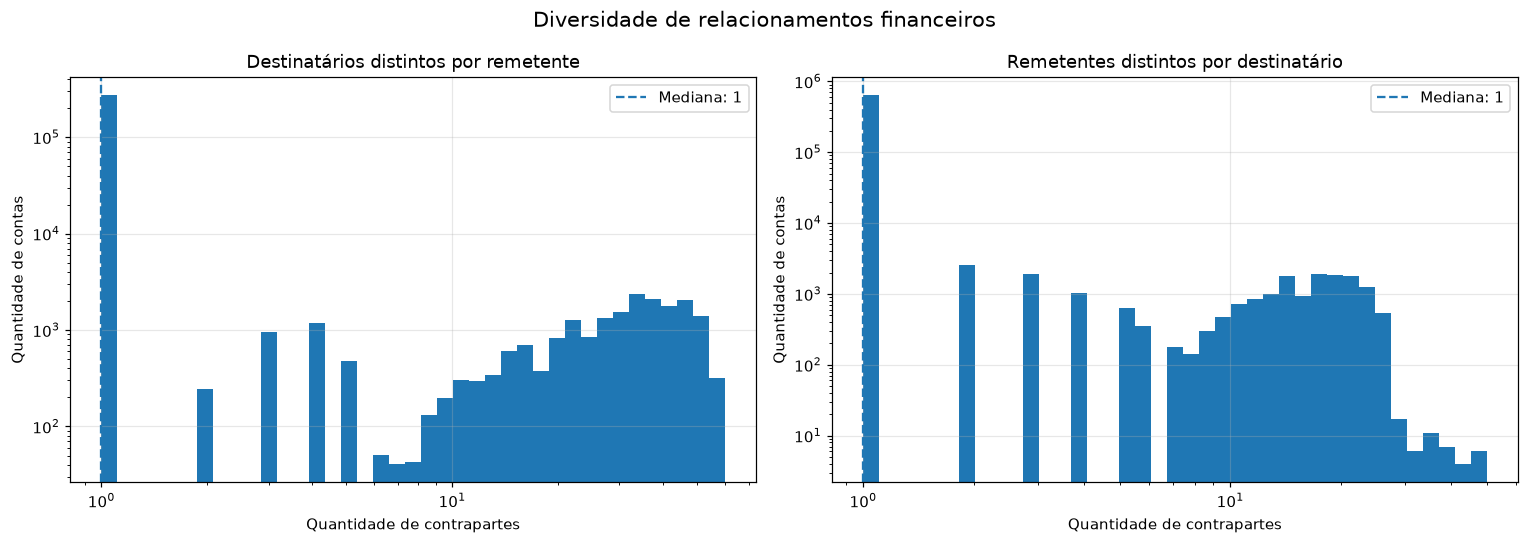


Análise das interações concluída!


In [13]:
# ============================================================
# 5.8 ANÁLISE DAS INTERAÇÕES ENTRE CONTAS
# ============================================================

print("=" * 65)
print("ANÁLISE DAS INTERAÇÕES ENTRE CONTAS")
print("=" * 65)


# ============================================================
# 1. CONTRAPARTES DISTINTAS
# ============================================================

print("\n=== CONTRAPARTES DISTINTAS ===")

# Quantidade de destinatários diferentes por remetente
contrapartes_envio = (
    df.groupby("Sender_account", sort=False)[
        "Receiver_account"
    ]
    .nunique()
)

# Quantidade de remetentes diferentes por destinatário
contrapartes_recebimento = (
    df.groupby("Receiver_account", sort=False)[
        "Sender_account"
    ]
    .nunique()
)


# ============================================================
# 2. ESTATÍSTICAS DAS INTERAÇÕES
# ============================================================

def resumo_contrapartes(serie):

    return {
        "Contas": len(serie),
        "Média de contrapartes": serie.mean(),
        "Mediana": serie.median(),
        "Percentil 90": serie.quantile(0.90),
        "Percentil 95": serie.quantile(0.95),
        "Percentil 99": serie.quantile(0.99),
        "Máximo": serie.max(),
        "Apenas 1 contraparte": (serie == 1).sum()
    }


resumo_interacoes = pd.DataFrame({

    "Como remetente": resumo_contrapartes(
        contrapartes_envio
    ),

    "Como destinatário": resumo_contrapartes(
        contrapartes_recebimento
    )

})

print("\n=== DISTRIBUIÇÃO DAS CONTRAPARTES ===")

display(
    resumo_interacoes.round(2)
)


# ============================================================
# 3. RELACIONAMENTOS REPETIDOS
# ============================================================

print("\n=== REPETIÇÃO DE RELACIONAMENTOS ===")

pares = (
    df.groupby(
        ["Sender_account", "Receiver_account"],
        sort=False
    )
    .size()
    .rename("quantidade_transacoes")
)

pares_repetidos = pares[pares > 1]

print(
    "Relacionamentos direcionados distintos:",
    f"{len(pares):,}"
)

print(
    "Relacionamentos com mais de uma transação:",
    f"{len(pares_repetidos):,}"
)

print(
    "Transações pertencentes a relacionamentos repetidos:",
    f"{pares_repetidos.sum():,}"
)

print(
    "Máximo de transações entre o mesmo par:",
    f"{pares.max():,}"
)


# ============================================================
# 4. ANÁLISE DAS INTERAÇÕES SUSPEITAS
# ============================================================

print("\n=== CONTRAPARTES EM TRANSAÇÕES SUSPEITAS ===")

df_suspeitas = df.loc[
    df["Is_laundering"] == 1
]

pares_suspeitos = df_suspeitas[
    ["Sender_account", "Receiver_account"]
].drop_duplicates()

print(
    "Transações suspeitas:",
    f"{len(df_suspeitas):,}"
)

print(
    "Relacionamentos suspeitos distintos:",
    f"{len(pares_suspeitos):,}"
)

print(
    "Remetentes distintos:",
    f"{pares_suspeitos['Sender_account'].nunique():,}"
)

print(
    "Destinatários distintos:",
    f"{pares_suspeitos['Receiver_account'].nunique():,}"
)


# ============================================================
# 5. DISTRIBUIÇÃO DAS CONTRAPARTES
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

series = [
    (contrapartes_envio, "Destinatários distintos por remetente"),
    (contrapartes_recebimento, "Remetentes distintos por destinatário")
]

for ax, (serie, titulo) in zip(axes, series):

    bins = np.logspace(
        0,
        np.log10(serie.max()),
        40
    )

    ax.hist(
        serie,
        bins=bins
    )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.axvline(
        serie.median(),
        linestyle="--",
        label=f"Mediana: {serie.median():.0f}"
    )

    ax.set_title(titulo)
    ax.set_xlabel("Quantidade de contrapartes")
    ax.set_ylabel("Quantidade de contas")

    ax.legend()
    ax.grid(alpha=0.3)


plt.suptitle(
    "Diversidade de relacionamentos financeiros",
    fontsize=14
)

plt.tight_layout()
plt.show()


print("\nAnálise das interações concluída!")

Conclusão da análise das interações entre contas

A investigação identificou uma concentração significativa de relacionamentos financeiros. A mediana de contrapartes distintas foi igual a uma tanto para remetentes quanto para destinatários, demonstrando que grande parte das contas mantém relacionamentos com poucos participantes.

Entretanto, foram identificados grupos com maior diversidade de interações, especialmente entre remetentes.

Também foram identificados 887.497 relacionamentos direcionados distintos, dos quais 781.631 aparecem em mais de uma transação. Esses relacionamentos concentram aproximadamente 98,89% das transações do dataset.

Os resultados demonstram que a repetição e a diversidade das interações são características potencialmente relevantes para uma análise comportamental de movimentações financeiras.

5.9 ANÁLISE DAS LOCALIZAÇÕES BANCÁRIAS

Esta investigação analisa a distribuição geográfica dos bancos remetentes e destinatários, buscando identificar possíveis diferenças na incidência de transações suspeitas.

Também será investigada a relação entre a localização dos bancos envolvidos na operação, distinguindo movimentações entre bancos da mesma localização e de localizações diferentes.

ANÁLISE DAS LOCALIZAÇÕES BANCÁRIAS

=== DIVERSIDADE GEOGRÁFICA ===
Localizações dos bancos remetentes: 18
Localizações dos bancos destinatários: 18

=== LOCALIZAÇÕES DOS REMETENTES ===


,total_transacoes,suspeitas,normais,participacao (%),taxa_suspeitas (%)
Sender_bank_location,,,,,
UK,9183088,9253,9173835,96.6147,0.1008
Turkey,20902,27,20875,0.2199,0.1292
Switzerland,20503,41,20462,0.2157,0.2000
Pakistan,20346,25,20321,0.2141,0.1229
UAE,20081,34,20047,0.2113,0.1693
Nigeria,20027,25,20002,0.2107,0.1248
Spain,19391,27,19364,0.2040,0.1392
Germany,19259,43,19216,0.2026,0.2233
USA,19027,36,18991,0.2002,0.1892



=== LOCALIZAÇÕES DOS DESTINATÁRIOS ===


,total_transacoes,suspeitas,normais,participacao (%),taxa_suspeitas (%)
Receiver_bank_location,,,,,
UK,8864634,7308,8857326,93.2643,0.0824
Pakistan,38980,169,38811,0.4101,0.4336
Austria,38844,154,38690,0.4087,0.3965
Albania,38783,235,38548,0.4080,0.6059
Japan,38729,83,38646,0.4075,0.2143
Morocco,38704,253,38451,0.4072,0.6537
Germany,38540,102,38438,0.4055,0.2647
France,38512,82,38430,0.4052,0.2129
Mexico,38385,197,38188,0.4038,0.5132



=== COMPARAÇÃO ENTRE LOCALIZAÇÕES ===


,Tipo de movimentação,Total de transações,Suspeitas,Normais,Participação (%),Taxa de suspeitas (%)
0,Mesma localização,8570504,6828,8563676,90.1698,0.0797
1,Localizações diferentes,934348,3045,931303,9.8302,0.3259


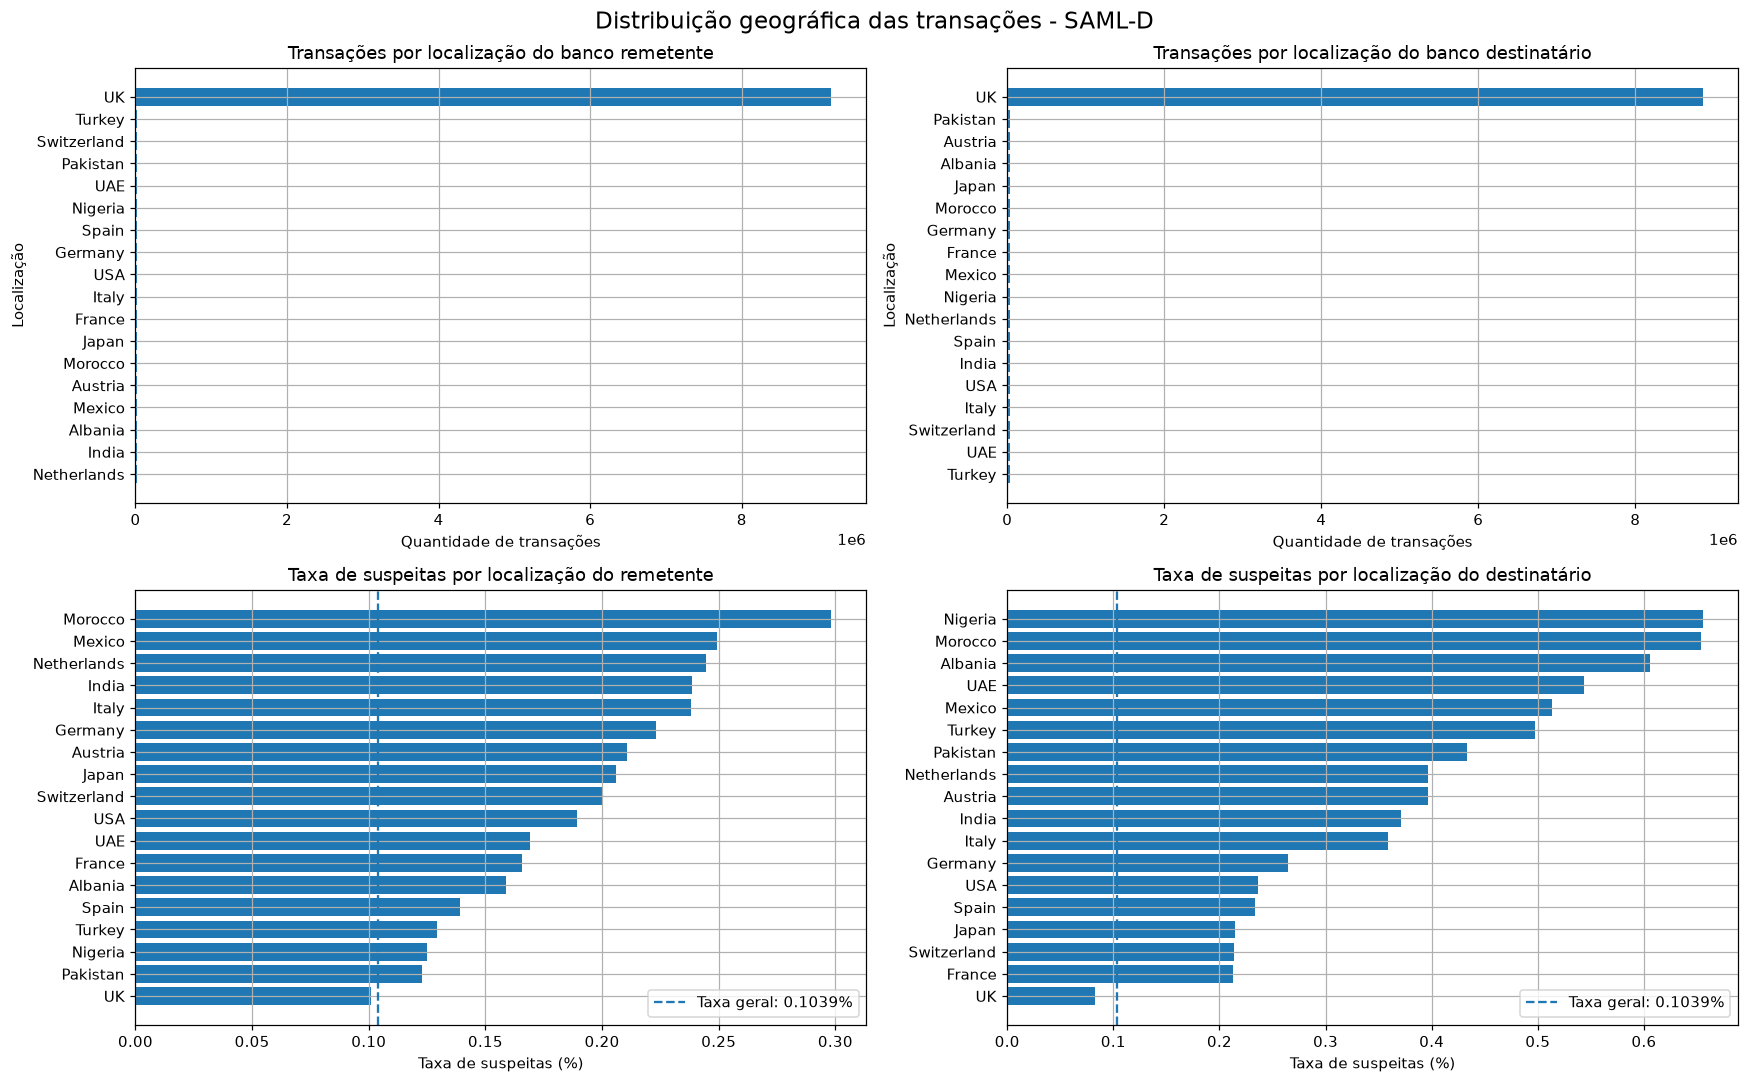


Análise geográfica concluída!


In [14]:
# ============================================================
# 5.9 ANÁLISE DAS LOCALIZAÇÕES BANCÁRIAS
# ============================================================

print("=" * 65)
print("ANÁLISE DAS LOCALIZAÇÕES BANCÁRIAS")
print("=" * 65)


# ============================================================
# 1. RESUMO DAS LOCALIZAÇÕES
# ============================================================

def resumir_localizacao(coluna):

    resumo = (
        df.groupby(coluna, observed=True)
        .agg(
            total_transacoes=("Is_laundering", "size"),
            suspeitas=("Is_laundering", "sum")
        )
    )

    resumo["normais"] = (
        resumo["total_transacoes"] - resumo["suspeitas"]
    )

    resumo["participacao (%)"] = (
        resumo["total_transacoes"] / len(df) * 100
    )

    resumo["taxa_suspeitas (%)"] = (
        resumo["suspeitas"]
        / resumo["total_transacoes"] * 100
    )

    return resumo.sort_values(
        "total_transacoes",
        ascending=False
    )


resumo_bancos_envio = resumir_localizacao(
    "Sender_bank_location"
)

resumo_bancos_recebimento = resumir_localizacao(
    "Receiver_bank_location"
)


# ============================================================
# 2. DIVERSIDADE DE LOCALIZAÇÕES
# ============================================================

print("\n=== DIVERSIDADE GEOGRÁFICA ===")

print(
    "Localizações dos bancos remetentes:",
    df["Sender_bank_location"].nunique()
)

print(
    "Localizações dos bancos destinatários:",
    df["Receiver_bank_location"].nunique()
)


# ============================================================
# 3. TABELAS DE DISTRIBUIÇÃO
# ============================================================

print("\n=== LOCALIZAÇÕES DOS REMETENTES ===")

display(
    resumo_bancos_envio.round(4)
)

print("\n=== LOCALIZAÇÕES DOS DESTINATÁRIOS ===")

display(
    resumo_bancos_recebimento.round(4)
)


# ============================================================
# 4. COMPARAÇÃO ENTRE BANCOS DA MESMA LOCALIZAÇÃO
#    E DE LOCALIZAÇÕES DIFERENTES
# ============================================================

print("\n=== COMPARAÇÃO ENTRE LOCALIZAÇÕES ===")

# Harmonizar as categorias antes da comparação
categorias_locais = (
    df["Sender_bank_location"].cat.categories
    .union(
        df["Receiver_bank_location"].cat.categories
    )
)

codigos_envio = (
    df["Sender_bank_location"]
    .cat.set_categories(categorias_locais)
    .cat.codes
    .to_numpy()
)

codigos_recebimento = (
    df["Receiver_bank_location"]
    .cat.set_categories(categorias_locais)
    .cat.codes
    .to_numpy()
)

# Comparar as localizações de cada operação
localizacoes_diferentes = (
    codigos_envio != codigos_recebimento
)

rotulos = df["Is_laundering"].to_numpy()

resultados_geograficos = []

for diferente, nome in [
    (False, "Mesma localização"),
    (True, "Localizações diferentes")
]:

    mascara = localizacoes_diferentes == diferente

    total = int(mascara.sum())

    suspeitas = int(
        rotulos[mascara].sum()
    )

    resultados_geograficos.append({

        "Tipo de movimentação": nome,

        "Total de transações": total,

        "Suspeitas": suspeitas,

        "Normais": total - suspeitas,

        "Participação (%)": total / len(df) * 100,

        "Taxa de suspeitas (%)": suspeitas / total * 100

    })


resumo_geografico = pd.DataFrame(
    resultados_geograficos
)

display(
    resumo_geografico.round(4)
)


# ============================================================
# 5. VISUALIZAÇÃO DAS LOCALIZAÇÕES
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10)
)

# ------------------------------------------------------------
# VOLUME POR LOCALIZAÇÃO DE ENVIO
# ------------------------------------------------------------

dados = resumo_bancos_envio.sort_values(
    "total_transacoes"
)

axes[0, 0].barh(
    dados.index.astype(str),
    dados["total_transacoes"]
)

axes[0, 0].set_title(
    "Transações por localização do banco remetente"
)

axes[0, 0].set_xlabel("Quantidade de transações")
axes[0, 0].set_ylabel("Localização")


# ------------------------------------------------------------
# VOLUME POR LOCALIZAÇÃO DE RECEBIMENTO
# ------------------------------------------------------------

dados = resumo_bancos_recebimento.sort_values(
    "total_transacoes"
)

axes[0, 1].barh(
    dados.index.astype(str),
    dados["total_transacoes"]
)

axes[0, 1].set_title(
    "Transações por localização do banco destinatário"
)

axes[0, 1].set_xlabel("Quantidade de transações")
axes[0, 1].set_ylabel("Localização")


# ------------------------------------------------------------
# TAXA DE SUSPEITAS - REMETENTES
# ------------------------------------------------------------

dados = resumo_bancos_envio.sort_values(
    "taxa_suspeitas (%)"
)

axes[1, 0].barh(
    dados.index.astype(str),
    dados["taxa_suspeitas (%)"]
)

taxa_geral = df["Is_laundering"].mean() * 100

axes[1, 0].axvline(
    taxa_geral,
    linestyle="--",
    label=f"Taxa geral: {taxa_geral:.4f}%"
)

axes[1, 0].set_title(
    "Taxa de suspeitas por localização do remetente"
)

axes[1, 0].set_xlabel("Taxa de suspeitas (%)")
axes[1, 0].legend()


# ------------------------------------------------------------
# TAXA DE SUSPEITAS - DESTINATÁRIOS
# ------------------------------------------------------------

dados = resumo_bancos_recebimento.sort_values(
    "taxa_suspeitas (%)"
)

axes[1, 1].barh(
    dados.index.astype(str),
    dados["taxa_suspeitas (%)"]
)

axes[1, 1].axvline(
    taxa_geral,
    linestyle="--",
    label=f"Taxa geral: {taxa_geral:.4f}%"
)

axes[1, 1].set_title(
    "Taxa de suspeitas por localização do destinatário"
)

axes[1, 1].set_xlabel("Taxa de suspeitas (%)")
axes[1, 1].legend()


plt.suptitle(
    "Distribuição geográfica das transações - SAML-D",
    fontsize=15
)

plt.tight_layout()
plt.show()


print("\nAnálise geográfica concluída!")

6.1 TRANSFORMAÇÃO DE TRANSAÇÕES EM EVENTOS

Cada transação será representada por dois eventos independentes: envio e recebimento. Essa transformação permite reconstruir o histórico de movimentações de cada conta, considerando os dois papéis desempenhados nas operações financeiras.

Os eventos receberão identificadores e rótulos associados à transação original. Posteriormente, serão ordenados cronologicamente por conta.

In [15]:
# ============================================================
# 6.1 TRANSFORMAÇÃO DE TRANSAÇÕES EM EVENTOS
# ============================================================

print("=" * 65)
print("CRIAÇÃO DOS EVENTOS DO FRAUDRADAR")
print("=" * 65)

# Quantidade original de transações
n = len(df)

# Codificar tipos de pagamento
categorias_pagamento = df["Payment_type"].cat.categories

payment_codes = df["Payment_type"].cat.codes.to_numpy(
    dtype=np.int8
)

# Verificar a codificação
assert payment_codes.min() >= 0
assert payment_codes.max() < len(categorias_pagamento)

# Rótulos das transações
y_transacoes = df["Is_laundering"].to_numpy(
    dtype=np.int8
)

# ============================================================
# CONSTRUIR EVENTOS DE ENVIO E RECEBIMENTO
# ============================================================

eventos_conta = pd.DataFrame({

    # Identificador da transação original
    "transaction_id": np.tile(
        np.arange(n, dtype=np.int32),
        2
    ),

    # Conta que estamos analisando
    "account_id": np.concatenate([
        df["Sender_account"].to_numpy(),
        df["Receiver_account"].to_numpy()
    ]),

    # Outra conta envolvida na operação
    "counterparty_id": np.concatenate([
        df["Receiver_account"].to_numpy(),
        df["Sender_account"].to_numpy()
    ]),

    # Data e horário
    "timestamp": np.concatenate([
        df["timestamp"].to_numpy(),
        df["timestamp"].to_numpy()
    ]),

    # Valor financeiro
    "amount": np.concatenate([
        df["Amount"].to_numpy(dtype=np.float32),
        df["Amount"].to_numpy(dtype=np.float32)
    ]),

    # Tipo de pagamento codificado
    "payment_type": np.concatenate([
        payment_codes,
        payment_codes
    ]),

    # 1 = ENVIO | 0 = RECEBIMENTO
    "direction": np.concatenate([
        np.ones(n, dtype=np.int8),
        np.zeros(n, dtype=np.int8)
    ]),

    # Rótulo da transação original
    "y": np.concatenate([
        y_transacoes,
        y_transacoes
    ])

})


# ============================================================
# VERIFICAÇÃO DOS RESULTADOS
# ============================================================

print("\n=== RESULTADOS ===")

print(
    "Transações originais:",
    f"{n:,}"
)

print(
    "Eventos criados:",
    f"{len(eventos_conta):,}"
)

print(
    "Contas distintas:",
    f"{eventos_conta['account_id'].nunique():,}"
)

print(
    "Contrapartes distintas:",
    f"{eventos_conta['counterparty_id'].nunique():,}"
)

print("\n=== DISTRIBUIÇÃO DOS EVENTOS ===")

display(
    eventos_conta["direction"]
    .value_counts()
    .rename(index={
        1: "ENVIO",
        0: "RECEBIMENTO"
    })
    .to_frame("Quantidade")
)

print("\n=== DISTRIBUIÇÃO DOS RÓTULOS ===")

display(
    eventos_conta["y"]
    .value_counts()
    .sort_index()
    .to_frame("Quantidade")
)

print("\n=== PRIMEIROS EVENTOS ===")

display(
    eventos_conta.head(10)
)

print(
    "\nMemória dos eventos:",
    round(
        eventos_conta.memory_usage(deep=True).sum()
        / 1024**3,
        2
    ),
    "GB"
)

print("\nConstrução dos eventos concluída!")

CRIAÇÃO DOS EVENTOS DO FRAUDRADAR

=== RESULTADOS ===
Transações originais: 9,504,852
Eventos criados: 19,009,704
Contas distintas: 855,460
Contrapartes distintas: 855,460

=== DISTRIBUIÇÃO DOS EVENTOS ===


,Quantidade
direction,
ENVIO,9504852
RECEBIMENTO,9504852



=== DISTRIBUIÇÃO DOS RÓTULOS ===


,Quantidade
y,
0,18989958
1,19746



=== PRIMEIROS EVENTOS ===


,transaction_id,account_id,counterparty_id,timestamp,amount,payment_type,direction,y
0,0,8724731955,2769355426,2022-10-07 10:35:19,1459.150024,1,1,0
1,1,1491989064,8401255335,2022-10-07 10:35:20,6019.640137,5,1,0
2,2,287305149,4404767002,2022-10-07 10:35:20,14328.440430,3,1,0
3,3,5376652437,9600420220,2022-10-07 10:35:21,11895.000000,0,1,0
4,4,9614186178,3803336972,2022-10-07 10:35:21,115.250000,1,1,0
5,5,8974559268,3143547511,2022-10-07 10:35:21,5130.990234,0,1,0
6,6,980191499,8577635959,2022-10-07 10:35:23,12176.519531,0,1,0
7,7,8057793308,9350896213,2022-10-07 10:35:23,56.900002,4,1,0
8,8,6116657264,656192169,2022-10-07 10:35:26,4738.450195,3,1,0
9,9,7421451752,2755709071,2022-10-07 10:35:29,5883.870117,4,1,0



Memória dos eventos: 0.62 GB

Construção dos eventos concluída!


In [16]:
# ============================================================
# 6.2 ORDENAÇÃO CRONOLÓGICA DOS EVENTOS
# ============================================================

print("Ordenando eventos por conta e horário...")

inicio_ordenacao = time.perf_counter()

eventos_conta = eventos_conta.sort_values(
    ["account_id", "timestamp", "transaction_id"],
    kind="stable",
    ignore_index=True
)

tempo_ordenacao = time.perf_counter() - inicio_ordenacao

print("\n=== ORDENAÇÃO CONCLUÍDA ===")

print(
    f"Tempo de execução: {tempo_ordenacao:.2f} segundos"
)

print(
    "Total de eventos:",
    f"{len(eventos_conta):,}"
)

print(
    "Contas distintas:",
    f"{eventos_conta['account_id'].nunique():,}"
)

print("\n=== PRIMEIROS EVENTOS ORDENADOS ===")

display(
    eventos_conta.head(10)
)

Ordenando eventos por conta e horário...

=== ORDENAÇÃO CONCLUÍDA ===
Tempo de execução: 4.82 segundos
Total de eventos: 19,009,704
Contas distintas: 855,460

=== PRIMEIROS EVENTOS ORDENADOS ===


,transaction_id,account_id,counterparty_id,timestamp,amount,payment_type,direction,y
0,8562799,9018,6080420349,2023-07-21 21:32:35,3319.060059,0,0,0
1,8572082,9018,2388293593,2023-07-22 09:51:28,3319.060059,5,1,0
2,1420882,13266,2595228252,2022-11-24 16:20:16,1178.699951,3,0,0
3,1753672,13266,2595228252,2022-12-06 04:28:33,2218.120117,4,0,0
4,2850709,13266,2595228252,2023-01-12 19:44:39,594.969971,4,0,0
5,3186386,13266,2595228252,2023-01-24 09:13:08,1043.719971,3,0,0
6,3290478,13266,2595228252,2023-01-27 18:08:10,674.909973,3,0,0
7,3346265,13266,2595228252,2023-01-29 16:57:38,650.840027,0,0,0
8,3768458,13266,2595228252,2023-02-11 21:30:07,1597.339966,0,0,0
9,5023851,13266,2595228252,2023-03-25 01:51:52,1137.540039,4,0,0


6.3 ENGENHARIA DE CARACTERÍSTICAS DOS EVENTOS

Nesta etapa serão criadas características financeiras, comportamentais e temporais para descrever cada evento.

As características temporais utilizarão transformações cíclicas, permitindo representar corretamente a proximidade entre horários e dias da semana.

Também será calculado o intervalo entre eventos consecutivos da mesma conta, utilizando exclusivamente informações temporais anteriores ao evento analisado.

In [17]:
# ============================================================
# 6.3 ENGENHARIA DE CARACTERÍSTICAS DOS EVENTOS
# ============================================================

print("=" * 65)
print("ENGENHARIA DE CARACTERÍSTICAS")
print("=" * 65)


# ============================================================
# 1. VALOR FINANCEIRO EM ESCALA LOGARÍTMICA
# ============================================================

eventos_conta["log_amount"] = np.log1p(
    eventos_conta["amount"]
).astype("float32")


# ============================================================
# 2. INTERVALO DESDE O EVENTO ANTERIOR
# ============================================================

print("\nCalculando intervalos entre eventos...")

intervalo = (
    eventos_conta
    .groupby("account_id", sort=False)["timestamp"]
    .diff()
)

segundos = intervalo.dt.total_seconds()

# Identificar existência de histórico anterior
eventos_conta["has_previous"] = (
    intervalo.notna()
).astype("int8")

# Transformação logarítmica do intervalo
eventos_conta["gap_log"] = np.log1p(
    segundos.fillna(0).clip(lower=0)
).astype("float32")

# Liberar memória
del intervalo, segundos

gc.collect()


# ============================================================
# 3. CARACTERÍSTICAS CÍCLICAS DO HORÁRIO
# ============================================================

hora = eventos_conta["timestamp"].dt.hour.to_numpy(
    dtype=np.float32
)

eventos_conta["hour_sin"] = np.sin(
    2 * np.pi * hora / 24
).astype("float32")

eventos_conta["hour_cos"] = np.cos(
    2 * np.pi * hora / 24
).astype("float32")


# ============================================================
# 4. CARACTERÍSTICAS CÍCLICAS DO DIA DA SEMANA
# ============================================================

dia = eventos_conta["timestamp"].dt.day_of_week.to_numpy(
    dtype=np.float32
)

eventos_conta["weekday_sin"] = np.sin(
    2 * np.pi * dia / 7
).astype("float32")

eventos_conta["weekday_cos"] = np.cos(
    2 * np.pi * dia / 7
).astype("float32")


# Liberar variáveis temporárias
del hora, dia

gc.collect()


# ============================================================
# 5. DEFINIR AS CARACTERÍSTICAS DO EVENTO
# ============================================================

features_numericas = [
    "log_amount",
    "direction",
    "gap_log",
    "has_previous",
    "hour_sin",
    "hour_cos",
    "weekday_sin",
    "weekday_cos"
]

features_categoricas = [
    "payment_type"
]

features_evento = (
    features_numericas + features_categoricas
)


# ============================================================
# 6. VERIFICAR CARACTERÍSTICAS CRIADAS
# ============================================================

print("\n=== CARACTERÍSTICAS CRIADAS ===")

print(
    "Características numéricas:",
    len(features_numericas)
)

print(
    "Características categóricas:",
    len(features_categoricas)
)

print(
    "Total de características por evento:",
    len(features_evento)
)

# Conferir categorias de pagamento
print("\n=== CATEGORIAS DE PAGAMENTO ===")

for codigo, categoria in enumerate(categorias_pagamento):

    print(f"{codigo}: {categoria}")


# ============================================================
# 7. VERIFICAR VALORES AUSENTES E INVÁLIDOS
# ============================================================

print("\n=== VALIDAÇÃO DAS CARACTERÍSTICAS ===")

display(
    eventos_conta[features_evento]
    .isna()
    .sum()
    .to_frame("Valores ausentes")
)

matriz_numerica = eventos_conta[
    features_numericas
].to_numpy(dtype=np.float32)

print(
    "Valores não finitos:",
    int((~np.isfinite(matriz_numerica)).sum())
)

assert np.isfinite(matriz_numerica).all()

assert eventos_conta["payment_type"].min() >= 0

assert eventos_conta["payment_type"].max() < len(
    categorias_pagamento
)

del matriz_numerica


# ============================================================
# 8. VISUALIZAR ALGUNS EVENTOS
# ============================================================

print("\n=== EXEMPLOS DE EVENTOS COM CARACTERÍSTICAS ===")

display(
    eventos_conta[
        [
            "account_id",
            "timestamp",
            "amount",
            "log_amount",
            "direction",
            "gap_log",
            "has_previous",
            "hour_sin",
            "hour_cos",
            "weekday_sin",
            "weekday_cos",
            "payment_type",
            "y"
        ]
    ].sample(10, random_state=SEED)
)

print("\nEngenharia de características concluída!")

ENGENHARIA DE CARACTERÍSTICAS

Calculando intervalos entre eventos...

=== CARACTERÍSTICAS CRIADAS ===
Características numéricas: 8
Características categóricas: 1
Total de características por evento: 9

=== CATEGORIAS DE PAGAMENTO ===
0: ACH
1: Cash Deposit
2: Cash Withdrawal
3: Cheque
4: Credit card
5: Cross-border
6: Debit card

=== VALIDAÇÃO DAS CARACTERÍSTICAS ===


,Valores ausentes
log_amount,0
direction,0
gap_log,0
has_previous,0
hour_sin,0
hour_cos,0
weekday_sin,0
weekday_cos,0
payment_type,0


Valores não finitos: 0

=== EXEMPLOS DE EVENTOS COM CARACTERÍSTICAS ===


,account_id,timestamp,amount,log_amount,direction,gap_log,has_previous,hour_sin,hour_cos,weekday_sin,weekday_cos,payment_type,y
4761921,2519514724,2023-06-12 16:58:13,6909.240234,8.840759,1,4.543295,1,-0.866025,-4.999999e-01,0.000000,1.000000,4,0
12056254,6343106098,2022-11-16 18:46:47,20571.080078,9.931690,1,8.791486,1,-1.000000,1.192488e-08,0.974928,-0.222521,4,0
1897111,1008114820,2023-03-26 17:16:48,4575.740234,8.428742,0,2.397895,1,-0.965926,-2.588190e-01,-0.781832,0.623490,6,0
14458985,7610760141,2022-12-18 13:14:41,6470.569824,8.775174,0,5.579730,1,-0.258819,-9.659258e-01,-0.781832,0.623490,6,0
4964470,2627841996,2023-04-15 20:02:40,23.990000,3.218476,1,11.570100,1,-0.866025,5.000003e-01,-0.974928,-0.222521,6,0
5210535,2759009808,2023-01-02 00:09:34,161.649994,5.091600,0,14.217612,1,0.000000,1.000000e+00,0.000000,1.000000,0,0
11116517,5847649137,2023-02-11 11:46:55,24131.429688,10.091311,0,9.190546,1,0.258819,-9.659259e-01,-0.974928,-0.222521,5,0
11566597,6083953045,2023-06-27 19:07:14,118.000000,4.779123,0,14.832313,1,-0.965926,2.588190e-01,0.781832,0.623490,0,0
15341611,8076812096,2023-05-31 10:25:52,9113.780273,9.117653,1,4.983607,1,0.500000,-8.660255e-01,0.974928,-0.222521,6,0
11435538,6016900593,2023-06-26 20:12:18,6104.399902,8.716928,0,5.411646,1,-0.866025,5.000003e-01,0.000000,1.000000,0,0



Engenharia de características concluída!


6.4 SEPARAÇÃO TEMPORAL E CONSTRUÇÃO DAS JANELAS

Os eventos serão divididos em três conjuntos cronológicos independentes. Dentro de cada conjunto, os eventos serão agrupados por conta e organizados em janelas não sobrepostas de dez eventos.

Cada janela representará uma amostra para o modelo, e seu rótulo será definido posteriormente como positivo quando pelo menos um dos dez eventos estiver associado a uma transação suspeita.

In [18]:
# ============================================================
# 6.4 SEPARAÇÃO TEMPORAL E CONSTRUÇÃO DAS JANELAS
# ============================================================

print("=" * 65)
print("CONSTRUÇÃO DAS JANELAS DO FRAUDRADAR")
print("=" * 65)

# Tamanho das janelas
TAMANHO_JANELA = 10

# Limites temporais
inicio_validacao = pd.Timestamp("2023-05-19")
inicio_teste = pd.Timestamp("2023-07-06")


# ============================================================
# 1. DEFINIR OS PERÍODOS
# ============================================================

periodos = {

    "treino": (
        eventos_conta["timestamp"] < inicio_validacao
    ).to_numpy(),

    "validacao": (
        (eventos_conta["timestamp"] >= inicio_validacao)
        &
        (eventos_conta["timestamp"] < inicio_teste)
    ).to_numpy(),

    "teste": (
        eventos_conta["timestamp"] >= inicio_teste
    ).to_numpy()

}


# Quantidades anteriormente obtidas com LSTM e GRU
quantidades_esperadas = {

    "treino": 1_078_404,

    "validacao": 194_016,

    "teste": 190_825

}


# ============================================================
# 2. CONSTRUIR OS ÍNDICES DAS JANELAS
# ============================================================

indices_por_periodo = {}

resultados_janelas = []

for nome, mascara in periodos.items():

    print(f"\nConstruindo janelas: {nome.upper()}...", flush=True)

    # Recuperar índices dos eventos pertencentes ao período
    indices_eventos = np.flatnonzero(mascara)

    # Selecionar somente os identificadores das contas
    parte = eventos_conta.loc[
        mascara,
        ["account_id"]
    ].copy()

    # Guardar o índice original de cada evento
    parte["_idx_evento"] = indices_eventos

    # Numerar eventos dentro de cada conta
    parte["_posicao"] = (
        parte.groupby("account_id", sort=False)
        .cumcount()
    )

    # Quantidade total de eventos de cada conta no período
    total_conta = (
        parte.groupby("account_id", sort=False)["_idx_evento"]
        .transform("size")
    )

    # Manter somente eventos pertencentes a janelas completas
    parte = parte.loc[
        parte["_posicao"]
        <
        (total_conta // TAMANHO_JANELA) * TAMANHO_JANELA
    ]

    # Converter os índices em uma matriz:
    # uma linha representa dez eventos de uma conta
    indices = parte["_idx_evento"].to_numpy(
        dtype=np.int32
    ).reshape(-1, TAMANHO_JANELA)

    # Validar dimensões e quantidades esperadas
    assert indices.shape[1] == TAMANHO_JANELA

    assert len(indices) == quantidades_esperadas[nome], (
        f"Quantidade inesperada de janelas em {nome}: "
        f"{len(indices):,}"
    )

    # Armazenar somente os índices, não duplicar os eventos
    indices_por_periodo[nome] = indices

    # Resumo
    resultados_janelas.append({

        "Conjunto": nome.capitalize(),

        "Eventos disponíveis": len(indices_eventos),

        "Janelas completas": len(indices),

        "Eventos aproveitados": indices.size,

        "Eventos descartados": len(indices_eventos) - indices.size

    })

    print(
        f"Eventos disponíveis: {len(indices_eventos):,}"
    )

    print(
        f"Janelas completas: {len(indices):,}"
    )

    print(
        f"Eventos descartados: "
        f"{len(indices_eventos) - indices.size:,}"
    )

    # Liberar memória temporária
    del parte, total_conta, indices_eventos

    gc.collect()


# ============================================================
# 3. APRESENTAR RESULTADOS
# ============================================================

resumo_construcao = pd.DataFrame(
    resultados_janelas
)

print("\n=== RESUMO DA CONSTRUÇÃO ===")

display(resumo_construcao)

print(
    "\nTotal de janelas:",
    f"{sum(len(v) for v in indices_por_periodo.values()):,}"
)

print("\n=== DIMENSÕES DOS ÍNDICES ===")

for nome, indices in indices_por_periodo.items():

    print(
        f"{nome.capitalize()}: {indices.shape}"
    )

print("\nConstrução das janelas concluída!")

CONSTRUÇÃO DAS JANELAS DO FRAUDRADAR

Construindo janelas: TREINO...
Eventos disponíveis: 13,322,446
Janelas completas: 1,078,404
Eventos descartados: 2,538,406

Construindo janelas: VALIDACAO...
Eventos disponíveis: 2,861,610
Janelas completas: 194,016
Eventos descartados: 921,450

Construindo janelas: TESTE...
Eventos disponíveis: 2,825,648
Janelas completas: 190,825
Eventos descartados: 917,398

=== RESUMO DA CONSTRUÇÃO ===


,Conjunto,Eventos disponíveis,Janelas completas,Eventos aproveitados,Eventos descartados
0,Treino,13322446,1078404,10784040,2538406
1,Validacao,2861610,194016,1940160,921450
2,Teste,2825648,190825,1908250,917398



Total de janelas: 1,463,245

=== DIMENSÕES DOS ÍNDICES ===
Treino: (1078404, 10)
Validacao: (194016, 10)
Teste: (190825, 10)

Construção das janelas concluída!


6.5 VALIDAÇÃO DOS RÓTULOS DAS JANELAS

Cada janela receberá um rótulo binário derivado dos dez eventos que a compõem. Uma janela será considerada suspeita quando pelo menos um evento estiver associado a uma transação classificada como lavagem de dinheiro.

Também serão verificadas a integridade das sequências, a ordem cronológica e a correspondência com os resultados dos experimentos anteriores.

In [19]:
# ============================================================
# 6.5 VALIDAÇÃO DOS RÓTULOS DAS JANELAS
# ============================================================

print("=" * 65)
print("VALIDAÇÃO DOS RÓTULOS DAS JANELAS")
print("=" * 65)

# Arrays originais dos eventos
y_eventos = eventos_conta["y"].to_numpy(dtype=np.int8)

account_ids = eventos_conta["account_id"].to_numpy()

timestamps = eventos_conta["timestamp"].to_numpy()

# Quantidades esperadas de janelas suspeitas
positivos_esperados = {
    "treino": 5580,
    "validacao": 683,
    "teste": 786
}

# Estruturas para armazenar os rótulos
rotulos_por_periodo = {}

resultados_validacao = []

for nome, indices in indices_por_periodo.items():

    print(f"\nValidando: {nome.upper()}...", flush=True)

    # Recuperar rótulos dos dez eventos de cada janela
    y_janelas = y_eventos[indices].max(axis=1)

    # Recuperar contas dos eventos
    contas_janelas = account_ids[indices]

    # Garantir que os dez eventos pertencem à mesma conta
    assert np.all(
        contas_janelas == contas_janelas[:, :1]
    ), f"Existem contas diferentes dentro de uma janela: {nome}"

    # Recuperar horários
    tempos_janelas = timestamps[indices]

    # Garantir ordem cronológica dentro das janelas
    assert np.all(
        tempos_janelas[:, 1:] >= tempos_janelas[:, :-1]
    ), f"Sequência cronológica inválida: {nome}"

    # Conferir os rótulos esperados
    quantidade_positivos = int(y_janelas.sum())

    quantidade_negativos = len(y_janelas) - quantidade_positivos

    assert quantidade_positivos == positivos_esperados[nome], (
        f"Quantidade divergente de suspeitas em {nome}: "
        f"{quantidade_positivos}"
    )

    # Armazenar os rótulos
    rotulos_por_periodo[nome] = y_janelas

    resultados_validacao.append({

        "Conjunto": nome.capitalize(),

        "Total de janelas": len(y_janelas),

        "Normais": quantidade_negativos,

        "Suspeitas": quantidade_positivos,

        "Suspeitas (%)": y_janelas.mean() * 100

    })

    print("Janelas:", f"{len(y_janelas):,}")
    print("Normais:", f"{quantidade_negativos:,}")
    print("Suspeitas:", f"{quantidade_positivos:,}")
    print("Integridade das contas: OK")
    print("Ordem cronológica: OK")
    print("Rótulos: OK")

    del contas_janelas, tempos_janelas, y_janelas

    gc.collect()


# ============================================================
# RESUMO FINAL
# ============================================================

resumo_rotulos = pd.DataFrame(
    resultados_validacao
)

print("\n=== DISTRIBUIÇÃO FINAL DAS JANELAS ===")

display(
    resumo_rotulos.round(4)
)

print("\nValidação concluída com sucesso!")

VALIDAÇÃO DOS RÓTULOS DAS JANELAS

Validando: TREINO...
Janelas: 1,078,404
Normais: 1,072,824
Suspeitas: 5,580
Integridade das contas: OK
Ordem cronológica: OK
Rótulos: OK

Validando: VALIDACAO...
Janelas: 194,016
Normais: 193,333
Suspeitas: 683
Integridade das contas: OK
Ordem cronológica: OK
Rótulos: OK

Validando: TESTE...
Janelas: 190,825
Normais: 190,039
Suspeitas: 786
Integridade das contas: OK
Ordem cronológica: OK
Rótulos: OK

=== DISTRIBUIÇÃO FINAL DAS JANELAS ===


,Conjunto,Total de janelas,Normais,Suspeitas,Suspeitas (%)
0,Treino,1078404,1072824,5580,0.5174
1,Validacao,194016,193333,683,0.3520
2,Teste,190825,190039,786,0.4119



Validação concluída com sucesso!


6.6 REPRESENTAÇÃO TABULAR POSICIONAL

Nesta etapa, cada janela de dez eventos será transformada em uma linha de dados tabulares. As características individuais serão distribuídas em colunas posicionais, preservando a ordem dos eventos.

As oito características numéricas serão expandidas em 80 colunas, enquanto a modalidade de pagamento será representada por dez colunas categóricas.

O resultado será uma matriz com 90 características por janela, mantendo os mesmos conjuntos de treinamento, validação e teste utilizados nos experimentos anteriores.

In [20]:
# ============================================================
# 6.6 CONSTRUÇÃO DA REPRESENTAÇÃO TABULAR POSICIONAL
# ============================================================

print("=" * 65)
print("CONSTRUÇÃO DAS MATRIZES POSICIONAIS")
print("=" * 65)

inicio_transformacao = time.perf_counter()

X_posicional = {}
y_posicional = {}

# Categorias fixas para garantir consistência entre conjuntos
categorias_pagamento_codes = list(range(len(categorias_pagamento)))


# ============================================================
# 1. DEFINIR NOMES DAS COLUNAS
# ============================================================

colunas_numericas = [
    f"{feature}_{posicao:02d}"
    for feature in features_numericas
    for posicao in range(1, TAMANHO_JANELA + 1)
]

colunas_categoricas = [
    f"payment_type_{posicao:02d}"
    for posicao in range(1, TAMANHO_JANELA + 1)
]

colunas_posicionais = (
    colunas_numericas + colunas_categoricas
)

assert len(colunas_numericas) == 80
assert len(colunas_categoricas) == 10
assert len(colunas_posicionais) == 90


# ============================================================
# 2. CONSTRUIR UMA MATRIZ POR CONJUNTO
# ============================================================

def construir_matriz_posicional(nome, indices):

    print(f"\nConstruindo: {nome.upper()}...", flush=True)

    quantidade_janelas = len(indices)

    # --------------------------------------------------------
    # Características numéricas
    # --------------------------------------------------------

    matriz_numerica = np.empty(
        (
            quantidade_janelas,
            len(colunas_numericas)
        ),
        dtype=np.float32
    )

    for i, feature in enumerate(features_numericas):

        valores = eventos_conta[feature].to_numpy(
            dtype=np.float32,
            copy=False
        )

        bloco = valores[indices]

        inicio = i * TAMANHO_JANELA
        fim = inicio + TAMANHO_JANELA

        matriz_numerica[:, inicio:fim] = bloco

        del valores, bloco

    # Converter para DataFrame
    X_num = pd.DataFrame(
        matriz_numerica,
        columns=colunas_numericas,
        copy=False
    )

    del matriz_numerica

    # --------------------------------------------------------
    # Características categóricas
    # --------------------------------------------------------

    codigos = eventos_conta[
        "payment_type"
    ].to_numpy(dtype=np.int8, copy=False)

    matriz_categorica = codigos[indices]

    dados_categoricos = {

        coluna: pd.Categorical(
            matriz_categorica[:, posicao],
            categories=categorias_pagamento_codes
        )

        for posicao, coluna in enumerate(
            colunas_categoricas
        )
    }

    X_cat = pd.DataFrame(dados_categoricos)

    del codigos, matriz_categorica, dados_categoricos

    # --------------------------------------------------------
    # Unir características numéricas e categóricas
    # --------------------------------------------------------

    X = pd.concat(
        [X_num, X_cat],
        axis=1,
        copy=False
    )

    del X_num, X_cat

    # Alvo separado das características
    y = rotulos_por_periodo[nome]

    assert X.shape == (
        quantidade_janelas,
        90
    )

    assert len(y) == quantidade_janelas

    assert X.columns.tolist() == colunas_posicionais

    # Verificar tipos das colunas categóricas
    assert all(
        isinstance(X[coluna].dtype, pd.CategoricalDtype)
        for coluna in colunas_categoricas
    )

    return X, y


# ============================================================
# 3. CONSTRUIR TREINO, VALIDAÇÃO E TESTE
# ============================================================

for nome, indices in indices_por_periodo.items():

    X, y = construir_matriz_posicional(
        nome,
        indices
    )

    X_posicional[nome] = X
    y_posicional[nome] = y

    print("Dimensões:", X.shape)

    print(
        "Características numéricas:",
        len(colunas_numericas)
    )

    print(
        "Características categóricas:",
        len(colunas_categoricas)
    )

    print(
        "Memória:",
        round(
            X.memory_usage(deep=True).sum() / 1024**2,
            2
        ),
        "MB"
    )

    print(
        "Janelas suspeitas:",
        int(y.sum())
    )

    gc.collect()


# ============================================================
# 4. VERIFICAÇÃO FINAL
# ============================================================

tempo_transformacao = (
    time.perf_counter() - inicio_transformacao
)

print("\n=== RESUMO DA REPRESENTAÇÃO POSICIONAL ===")

for nome, X in X_posicional.items():

    print(
        f"{nome.capitalize()}: "
        f"{X.shape[0]:,} janelas × {X.shape[1]} características"
    )

print(
    "\nTotal de características:",
    len(colunas_posicionais)
)

print(
    "Tempo de transformação:",
    f"{tempo_transformacao:.2f} segundos"
)

print("\n=== DISTRIBUIÇÃO DOS TIPOS DE DADOS ===")

display(
    X_posicional["treino"]
    .dtypes
    .astype(str)
    .value_counts()
    .to_frame("Quantidade de colunas")
)

print("\n=== PRIMEIRAS LINHAS DO TREINO ===")

display(
    X_posicional["treino"].head()
)

print("\nRepresentação posicional concluída!")

CONSTRUÇÃO DAS MATRIZES POSICIONAIS

Construindo: TREINO...
Dimensões: (1078404, 90)
Características numéricas: 80
Características categóricas: 10
Memória: 339.39 MB
Janelas suspeitas: 5580

Construindo: VALIDACAO...


C:\Users\Aluno\AppData\Local\Temp\ipykernel_9864\952949867.py:119: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  X = pd.concat(


Dimensões: (194016, 90)
Características numéricas: 80
Características categóricas: 10
Memória: 61.06 MB
Janelas suspeitas: 683

Construindo: TESTE...


C:\Users\Aluno\AppData\Local\Temp\ipykernel_9864\952949867.py:119: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  X = pd.concat(


Dimensões: (190825, 90)
Características numéricas: 80
Características categóricas: 10
Memória: 60.06 MB
Janelas suspeitas: 786

=== RESUMO DA REPRESENTAÇÃO POSICIONAL ===
Treino: 1,078,404 janelas × 90 características
Validacao: 194,016 janelas × 90 características
Teste: 190,825 janelas × 90 características

Total de características: 90
Tempo de transformação: 1.10 segundos

=== DISTRIBUIÇÃO DOS TIPOS DE DADOS ===


C:\Users\Aluno\AppData\Local\Temp\ipykernel_9864\952949867.py:119: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  X = pd.concat(


,Quantidade de colunas
float32,80
category,10



=== PRIMEIRAS LINHAS DO TREINO ===


,log_amount_01,log_amount_02,log_amount_03,log_amount_04,log_amount_05,log_amount_06,log_amount_07,log_amount_08,log_amount_09,log_amount_10,...,payment_type_01,payment_type_02,payment_type_03,payment_type_04,payment_type_05,payment_type_06,payment_type_07,payment_type_08,payment_type_09,payment_type_10
0,7.073015,7.704866,6.390190,6.951504,6.516060,6.479799,7.376721,7.037502,6.227445,6.426666,...,3,4,4,3,3,0,0,4,6,0
1,8.531492,8.528297,8.529436,8.537090,8.523012,8.531830,8.527577,8.544476,8.566118,8.551198,...,0,0,0,3,0,6,0,6,3,0
2,8.939919,9.908986,10.112669,10.329784,10.098732,9.616885,9.563293,9.192879,10.329545,9.598264,...,4,4,0,4,4,6,6,0,4,3
3,8.522943,8.514969,8.517015,8.525693,8.514120,8.522078,8.516919,8.512917,8.530397,8.509201,...,5,5,5,5,5,5,5,5,5,5
4,5.280815,8.424768,6.892550,9.368526,4.843951,8.184330,7.327373,7.431312,4.589549,7.238762,...,3,0,3,4,4,6,6,6,2,6



Representação posicional concluída!


6.7 VALIDAÇÃO DA REPRESENTAÇÃO POSICIONAL

A representação tabular será submetida a verificações de integridade para garantir que a transformação preservou os valores originais, a ordem cronológica dos eventos, as categorias de pagamento e os rótulos das janelas.

Essa validação é necessária para assegurar que o LightGBM receberá exatamente as mesmas amostras utilizadas nos experimentos de redes neurais.

In [21]:
# ============================================================
# 6.7 VALIDAÇÃO DA REPRESENTAÇÃO POSICIONAL
# ============================================================

print("=" * 65)
print("VALIDAÇÃO DA REPRESENTAÇÃO POSICIONAL")
print("=" * 65)

categorias_esperadas = list(range(len(categorias_pagamento)))

resultados_validacao_posicional = []


# ============================================================
# 1. VALIDAR CADA CONJUNTO
# ============================================================

for nome in ["treino", "validacao", "teste"]:

    print(f"\nValidando {nome.upper()}...")

    X = X_posicional[nome]
    y = y_posicional[nome]
    indices = indices_por_periodo[nome]

    # --------------------------------------------------------
    # Dimensões
    # --------------------------------------------------------

    assert X.shape == (len(indices), 90)

    assert len(y) == len(indices)

    assert len(colunas_numericas) == 80

    assert len(colunas_categoricas) == 10

    print("Dimensões: OK")

    # --------------------------------------------------------
    # Tipos numéricos
    # --------------------------------------------------------

    assert all(
        X[coluna].dtype == np.float32
        for coluna in colunas_numericas
    )

    print("80 características numéricas float32: OK")

    # --------------------------------------------------------
    # Tipos categóricos
    # --------------------------------------------------------

    for coluna in colunas_categoricas:

        assert isinstance(
            X[coluna].dtype,
            pd.CategoricalDtype
        )

        assert X[coluna].cat.categories.tolist() == (
            categorias_esperadas
        )

        assert (X[coluna].cat.codes >= 0).all()

    print("10 características categóricas: OK")

    # --------------------------------------------------------
    # Valores ausentes
    # --------------------------------------------------------

    assert not X.isna().any().any()

    print("Valores ausentes: 0")

    # --------------------------------------------------------
    # Valores numéricos finitos
    # --------------------------------------------------------

    for coluna in colunas_numericas:

        assert np.isfinite(
            X[coluna].to_numpy()
        ).all()

    print("Valores numéricos não finitos: 0")

    # --------------------------------------------------------
    # Verificar rótulos
    # --------------------------------------------------------

    y_recalculado = (
        y_eventos[indices]
        .max(axis=1)
    )

    assert np.array_equal(
        y,
        y_recalculado
    )

    assert set(np.unique(y)).issubset({0, 1})

    print("Correspondência dos rótulos: OK")

    del y_recalculado

    # --------------------------------------------------------
    # Verificar valores posicionais na origem
    # --------------------------------------------------------

    amostras_teste = [
        0,
        len(indices) // 2,
        len(indices) - 1
    ]

    for linha in amostras_teste:

        for i, feature in enumerate(features_numericas):

            for posicao in [0, 9]:

                indice_evento = indices[
                    linha,
                    posicao
                ]

                valor_original = eventos_conta[
                    feature
                ].iloc[indice_evento]

                coluna = f"{feature}_{posicao + 1:02d}"

                valor_tabular = X[
                    coluna
                ].iloc[linha]

                assert np.isclose(
                    valor_original,
                    valor_tabular,
                    rtol=1e-6,
                    atol=1e-6
                )

    print("Correspondência com eventos originais: OK")

    # --------------------------------------------------------
    # Resumo
    # --------------------------------------------------------

    resultados_validacao_posicional.append({

        "Conjunto": nome.capitalize(),

        "Janelas": len(X),

        "Características": X.shape[1],

        "Suspeitas": int(y.sum()),

        "Memória (MB)": (
            X.memory_usage(deep=True).sum() / 1024**2
        )

    })

    print("Integridade da representação: OK")


# ============================================================
# 2. RESUMO FINAL
# ============================================================

print("\n=== RESUMO DA VALIDAÇÃO ===")

display(
    pd.DataFrame(
        resultados_validacao_posicional
    ).round(2)
)

print("\nTodas as verificações foram aprovadas!")

VALIDAÇÃO DA REPRESENTAÇÃO POSICIONAL

Validando TREINO...
Dimensões: OK
80 características numéricas float32: OK
10 características categóricas: OK
Valores ausentes: 0
Valores numéricos não finitos: 0
Correspondência dos rótulos: OK
Correspondência com eventos originais: OK
Integridade da representação: OK

Validando VALIDACAO...
Dimensões: OK
80 características numéricas float32: OK
10 características categóricas: OK
Valores ausentes: 0
Valores numéricos não finitos: 0
Correspondência dos rótulos: OK
Correspondência com eventos originais: OK
Integridade da representação: OK

Validando TESTE...
Dimensões: OK
80 características numéricas float32: OK
10 características categóricas: OK
Valores ausentes: 0
Valores numéricos não finitos: 0
Correspondência dos rótulos: OK
Correspondência com eventos originais: OK
Integridade da representação: OK

=== RESUMO DA VALIDAÇÃO ===


,Conjunto,Janelas,Características,Suspeitas,Memória (MB)
0,Treino,1078404,90,5580,339.39
1,Validacao,194016,90,683,61.06
2,Teste,190825,90,786,60.06



Todas as verificações foram aprovadas!


6.8 ENGENHARIA DE CARACTERÍSTICAS AGREGADAS

Além das características posicionais, serão calculadas estatísticas descritivas sobre cada janela de dez eventos.

O objetivo é representar o comportamento financeiro, temporal e operacional da janela por meio de agregações estatísticas.

Todas as características serão calculadas exclusivamente com informações pertencentes à própria janela, sem utilização de rótulos ou dados futuros.

In [22]:
# ============================================================
# 6.8 CONSTRUÇÃO DAS CARACTERÍSTICAS AGREGADAS
# ============================================================

print("=" * 65)
print("CONSTRUÇÃO DAS CARACTERÍSTICAS AGREGADAS")
print("=" * 65)

inicio_agregacao = time.perf_counter()


# ============================================================
# 1. DEFINIR AS 34 CARACTERÍSTICAS
# ============================================================

features_agregadas = [

    # Valores financeiros: 8
    "amount_mean",
    "amount_std",
    "amount_min",
    "amount_max",
    "amount_median",
    "amount_q25",
    "amount_q75",
    "amount_range",

    # Intervalos: 8
    "gap_mean",
    "gap_std",
    "gap_min",
    "gap_max",
    "gap_median",
    "gap_q25",
    "gap_q75",
    "gap_range",

    # Direção: 2
    "envios_count",
    "direction_changes",

    # Histórico: 1
    "has_previous_count",

    # Pagamentos: 9
    *[
        f"payment_type_count_{codigo}"
        for codigo in range(7)
    ],
    "payment_type_distinct",
    "payment_type_changes",

    # Horários: 3
    "hour_sin_mean",
    "hour_cos_mean",
    "hour_concentration",

    # Dias da semana: 3
    "weekday_sin_mean",
    "weekday_cos_mean",
    "weekday_concentration"

]

assert len(features_agregadas) == 34
assert len(set(features_agregadas)) == 34

print(
    "\nCaracterísticas agregadas planejadas:",
    len(features_agregadas)
)


# ============================================================
# 2. PREPARAR ARRAYS DOS EVENTOS
# ============================================================

print("\nPreparando arrays dos eventos...")

arrays_eventos = {

    feature: eventos_conta[feature].to_numpy(
        dtype=np.float32,
        copy=False
    )

    for feature in features_numericas

}

arrays_eventos["payment_type"] = (
    eventos_conta["payment_type"].to_numpy(
        dtype=np.int8,
        copy=False
    )
)

categorias_validas = np.arange(
    len(categorias_pagamento),
    dtype=np.int8
)


# ============================================================
# 3. FUNÇÃO DE AGREGAÇÃO POR JANELA
# ============================================================

def construir_agregados(indices, nome):

    print(
        f"\nCalculando agregados: {nome.upper()}...",
        flush=True
    )

    dados = {}

    # --------------------------------------------------------
    # A. VALORES FINANCEIROS
    # --------------------------------------------------------

    amount = arrays_eventos["log_amount"][indices]

    # Formato: (quantidade de janelas, 10 eventos)

    dados["amount_mean"] = np.mean(amount, axis=1)

    dados["amount_std"] = np.std(amount, axis=1)

    dados["amount_min"] = np.min(amount, axis=1)

    dados["amount_max"] = np.max(amount, axis=1)

    dados["amount_median"] = np.median(amount, axis=1)

    quartis = np.percentile(
        amount,
        [25, 75],
        axis=1
    )

    dados["amount_q25"] = quartis[0]

    dados["amount_q75"] = quartis[1]

    dados["amount_range"] = (
        dados["amount_max"] - dados["amount_min"]
    )

    del amount, quartis

    # --------------------------------------------------------
    # B. INTERVALOS ENTRE EVENTOS
    # --------------------------------------------------------

    gaps = arrays_eventos["gap_log"][indices]

    has_previous = arrays_eventos["has_previous"][indices]

    # Excluir eventos sem histórico anterior
    gaps_validos = np.where(
        has_previous == 1,
        gaps,
        np.nan
    )

    # Garantir que exista pelo menos um intervalo válido
    assert np.all(
        np.isfinite(gaps_validos).any(axis=1)
    )

    dados["gap_mean"] = np.nanmean(
        gaps_validos,
        axis=1
    )

    dados["gap_std"] = np.nanstd(
        gaps_validos,
        axis=1
    )

    dados["gap_min"] = np.nanmin(
        gaps_validos,
        axis=1
    )

    dados["gap_max"] = np.nanmax(
        gaps_validos,
        axis=1
    )

    dados["gap_median"] = np.nanmedian(
        gaps_validos,
        axis=1
    )

    quartis_gap = np.nanpercentile(
        gaps_validos,
        [25, 75],
        axis=1
    )

    dados["gap_q25"] = quartis_gap[0]

    dados["gap_q75"] = quartis_gap[1]

    dados["gap_range"] = (
        dados["gap_max"] - dados["gap_min"]
    )

    del gaps, gaps_validos, quartis_gap

    # --------------------------------------------------------
    # C. DIREÇÃO DOS EVENTOS
    # --------------------------------------------------------

    direction = arrays_eventos["direction"][indices]

    # 1 = envio
    dados["envios_count"] = np.sum(
        direction,
        axis=1
    )

    # Quantidade de mudanças entre envio e recebimento
    dados["direction_changes"] = np.sum(
        direction[:, 1:] != direction[:, :-1],
        axis=1
    )

    del direction

    # --------------------------------------------------------
    # D. HISTÓRICO ANTERIOR
    # --------------------------------------------------------

    dados["has_previous_count"] = np.sum(
        has_previous,
        axis=1
    )

    del has_previous

    # --------------------------------------------------------
    # E. FREQUÊNCIA DAS CATEGORIAS DE PAGAMENTO
    # --------------------------------------------------------

    payment = arrays_eventos["payment_type"][indices]

    frequencias = []

    for codigo in categorias_validas:

        frequencia = np.sum(
            payment == codigo,
            axis=1
        )

        dados[
            f"payment_type_count_{codigo}"
        ] = frequencia

        frequencias.append(frequencia)

    frequencias = np.column_stack(frequencias)

    # Quantidade de modalidades diferentes
    dados["payment_type_distinct"] = np.sum(
        frequencias > 0,
        axis=1
    )

    # Mudanças entre categorias consecutivas
    dados["payment_type_changes"] = np.sum(
        payment[:, 1:] != payment[:, :-1],
        axis=1
    )

    del payment, frequencias

    # --------------------------------------------------------
    # F. CARACTERÍSTICAS CÍCLICAS DO HORÁRIO
    # --------------------------------------------------------

    hour_sin = arrays_eventos["hour_sin"][indices]

    hour_cos = arrays_eventos["hour_cos"][indices]

    dados["hour_sin_mean"] = np.mean(
        hour_sin,
        axis=1
    )

    dados["hour_cos_mean"] = np.mean(
        hour_cos,
        axis=1
    )

    # Concentração circular
    dados["hour_concentration"] = np.sqrt(
        dados["hour_sin_mean"] ** 2
        +
        dados["hour_cos_mean"] ** 2
    )

    del hour_sin, hour_cos

    # --------------------------------------------------------
    # G. CARACTERÍSTICAS CÍCLICAS DO DIA DA SEMANA
    # --------------------------------------------------------

    weekday_sin = arrays_eventos["weekday_sin"][indices]

    weekday_cos = arrays_eventos["weekday_cos"][indices]

    dados["weekday_sin_mean"] = np.mean(
        weekday_sin,
        axis=1
    )

    dados["weekday_cos_mean"] = np.mean(
        weekday_cos,
        axis=1
    )

    dados["weekday_concentration"] = np.sqrt(
        dados["weekday_sin_mean"] ** 2
        +
        dados["weekday_cos_mean"] ** 2
    )

    del weekday_sin, weekday_cos

    # --------------------------------------------------------
    # H. CRIAR DATAFRAME
    # --------------------------------------------------------

    X_agregado = pd.DataFrame(
        dados,
        dtype=np.float32
    )

    assert X_agregado.shape == (
        len(indices),
        34
    )

    assert X_agregado.columns.tolist() == (
        features_agregadas
    )

    return X_agregado


# ============================================================
# 4. CONSTRUIR TREINO, VALIDAÇÃO E TESTE
# ============================================================

X_agregadas = {}

for nome, indices in indices_por_periodo.items():

    X_agg = construir_agregados(
        indices,
        nome
    )

    X_agregadas[nome] = X_agg

    print(
        "Dimensões:",
        X_agg.shape
    )

    print(
        "Memória:",
        round(
            X_agg.memory_usage(deep=True).sum() / 1024**2,
            2
        ),
        "MB"
    )

    gc.collect()


# ============================================================
# 5. RESUMO FINAL
# ============================================================

tempo_agregacao = (
    time.perf_counter() - inicio_agregacao
)

print("\n=== RESUMO DAS CARACTERÍSTICAS AGREGADAS ===")

for nome, X in X_agregadas.items():

    print(
        f"{nome.capitalize()}: "
        f"{X.shape[0]:,} janelas × {X.shape[1]} características"
    )

print(
    "\nTotal de características agregadas:",
    len(features_agregadas)
)

print(
    "Tempo total de execução:",
    f"{tempo_agregacao:.2f} segundos"
)

print("\n=== TIPOS DE DADOS ===")

display(
    X_agregadas["treino"]
    .dtypes
    .astype(str)
    .value_counts()
    .to_frame("Quantidade")
)

print("\n=== PRIMEIRAS JANELAS ===")

display(
    X_agregadas["treino"].head()
)

print("\nConstrução das características agregadas concluída!")

CONSTRUÇÃO DAS CARACTERÍSTICAS AGREGADAS

Características agregadas planejadas: 34

Preparando arrays dos eventos...

Calculando agregados: TREINO...
Dimensões: (1078404, 34)
Memória: 139.87 MB

Calculando agregados: VALIDACAO...
Dimensões: (194016, 34)
Memória: 25.16 MB

Calculando agregados: TESTE...
Dimensões: (190825, 34)
Memória: 24.75 MB

=== RESUMO DAS CARACTERÍSTICAS AGREGADAS ===
Treino: 1,078,404 janelas × 34 características
Validacao: 194,016 janelas × 34 características
Teste: 190,825 janelas × 34 características

Total de características agregadas: 34
Tempo total de execução: 33.67 segundos

=== TIPOS DE DADOS ===


,Quantidade
float32,34



=== PRIMEIRAS JANELAS ===


,amount_mean,amount_std,amount_min,amount_max,amount_median,amount_q25,amount_q75,amount_range,gap_mean,gap_std,...,payment_type_count_5,payment_type_count_6,payment_type_distinct,payment_type_changes,hour_sin_mean,hour_cos_mean,hour_concentration,weekday_sin_mean,weekday_cos_mean,weekday_concentration
0,6.818376,0.460457,6.227445,7.704866,6.733782,6.439950,7.064137,1.477421,13.750957,1.155958,...,0.0,1.0,4.0,6.0,-0.369798,-0.074118,0.377152,-0.170907,-0.050000,0.178071
1,8.537052,0.012569,8.523012,8.566118,8.531661,8.528582,8.542629,0.043106,8.137827,1.377186,...,0.0,2.0,3.0,7.0,-0.029289,0.050731,0.058579,-0.974928,-0.222521,1.000000
2,9.769096,0.445984,8.939919,10.329784,9.762936,9.572035,10.109184,1.389865,13.301354,2.389101,...,0.0,2.0,4.0,6.0,-0.399087,0.269798,0.481727,0.086777,0.130798,0.156966
3,8.518625,0.006162,8.509201,8.530397,8.516968,8.514332,8.522726,0.021196,8.339490,0.739034,...,10.0,0.0,1.0,0.0,0.040010,-0.435690,0.437523,-0.433884,-0.900969,1.000000
4,6.958194,1.510007,4.589549,9.368526,7.283068,5.683749,7.996076,4.778978,11.081541,1.565991,...,0.0,4.0,5.0,6.0,-0.143185,-0.231551,0.272246,-0.082952,0.072252,0.110007



Construção das características agregadas concluída!


In [23]:
# ============================================================
# 6.9 VALIDAÇÃO DAS CARACTERÍSTICAS AGREGADAS
# ============================================================

print("=" * 65)
print("VALIDAÇÃO DAS CARACTERÍSTICAS AGREGADAS")
print("=" * 65)


# ============================================================
# 1. CORRIGIR NOMES DAS CARACTERÍSTICAS FINANCEIRAS
# ============================================================

renomear = {

    "amount_mean": "log_amount_mean",
    "amount_std": "log_amount_std",
    "amount_min": "log_amount_min",
    "amount_max": "log_amount_max",
    "amount_median": "log_amount_median",
    "amount_q25": "log_amount_q25",
    "amount_q75": "log_amount_q75",
    "amount_range": "log_amount_range"

}

features_agregadas = [
    renomear.get(coluna, coluna)
    for coluna in features_agregadas
]

# Atualizar os DataFrames existentes
for nome in X_agregadas:

    X_agregadas[nome].rename(
        columns=renomear,
        inplace=True
    )


# ============================================================
# 2. VALIDAR DIMENSÕES E TIPOS
# ============================================================

resultados = []

for nome in ["treino", "validacao", "teste"]:

    print(f"\nValidando {nome.upper()}...")

    X = X_agregadas[nome]

    assert X.shape == (
        len(indices_por_periodo[nome]),
        34
    )

    assert X.columns.tolist() == features_agregadas

    assert all(
        X[coluna].dtype == np.float32
        for coluna in features_agregadas
    )

    assert np.isfinite(
        X.to_numpy()
    ).all()

    # --------------------------------------------------------
    # Estatísticas financeiras
    # --------------------------------------------------------

    assert (
        X["log_amount_min"] <= X["log_amount_median"]
    ).all()

    assert (
        X["log_amount_median"] <= X["log_amount_max"]
    ).all()

    assert (
        X["log_amount_q25"] <= X["log_amount_q75"]
    ).all()

    assert (
        X["log_amount_std"] >= 0
    ).all()

    assert (
        X["log_amount_range"] >= 0
    ).all()

    # --------------------------------------------------------
    # Intervalos temporais
    # --------------------------------------------------------

    assert (X["gap_std"] >= 0).all()
    assert (X["gap_range"] >= 0).all()

    assert (
        X["gap_min"] <= X["gap_median"]
    ).all()

    assert (
        X["gap_median"] <= X["gap_max"]
    ).all()

    assert (
        X["gap_q25"] <= X["gap_q75"]
    ).all()

    # --------------------------------------------------------
    # Frequências das categorias
    # --------------------------------------------------------

    colunas_frequencia = [
        f"payment_type_count_{i}"
        for i in range(7)
    ]

    # Cada janela possui exatamente dez pagamentos
    assert (
        X[colunas_frequencia].sum(axis=1) == 10
    ).all()

    # Quantidade de categorias distintas
    assert np.array_equal(
        X["payment_type_distinct"].to_numpy(),
        (X[colunas_frequencia] > 0)
        .sum(axis=1).to_numpy()
    )

    # --------------------------------------------------------
    # Direção e histórico
    # --------------------------------------------------------

    assert X["envios_count"].between(0, 10).all()

    assert X["direction_changes"].between(0, 9).all()

    assert X["has_previous_count"].between(9, 10).all()

    # --------------------------------------------------------
    # Concentração circular
    # --------------------------------------------------------

    assert X["hour_concentration"].between(
        0, 1.00001
    ).all()

    assert X["weekday_concentration"].between(
        0, 1.00001
    ).all()

    print("Dimensões: OK")
    print("Tipos de dados: OK")
    print("Valores finitos: OK")
    print("Estatísticas financeiras: OK")
    print("Intervalos temporais: OK")
    print("Frequências de pagamento: OK")
    print("Direção e histórico: OK")
    print("Concentração circular: OK")

    resultados.append({

        "Conjunto": nome.capitalize(),

        "Janelas": len(X),

        "Características": X.shape[1],

        "Valores ausentes": int(X.isna().sum().sum()),

        "Memória (MB)": (
            X.memory_usage(deep=True).sum() / 1024**2
        )

    })


# ============================================================
# 3. RESUMO FINAL
# ============================================================

print("\n=== RESUMO DA VALIDAÇÃO ===")

display(
    pd.DataFrame(resultados).round(2)
)

print("\nTodas as características agregadas foram validadas!")

VALIDAÇÃO DAS CARACTERÍSTICAS AGREGADAS

Validando TREINO...
Dimensões: OK
Tipos de dados: OK
Valores finitos: OK
Estatísticas financeiras: OK
Intervalos temporais: OK
Frequências de pagamento: OK
Direção e histórico: OK
Concentração circular: OK

Validando VALIDACAO...
Dimensões: OK
Tipos de dados: OK
Valores finitos: OK
Estatísticas financeiras: OK
Intervalos temporais: OK
Frequências de pagamento: OK
Direção e histórico: OK
Concentração circular: OK

Validando TESTE...
Dimensões: OK
Tipos de dados: OK
Valores finitos: OK
Estatísticas financeiras: OK
Intervalos temporais: OK
Frequências de pagamento: OK
Direção e histórico: OK
Concentração circular: OK

=== RESUMO DA VALIDAÇÃO ===


C:\Users\Aluno\AppData\Local\Temp\ipykernel_9864\2469407821.py:35: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_agregadas[nome].rename(


,Conjunto,Janelas,Características,Valores ausentes,Memória (MB)
0,Treino,1078404,34,0,139.87
1,Validacao,194016,34,0,25.16
2,Teste,190825,34,0,24.75



Todas as características agregadas foram validadas!


6.10 INTEGRAÇÃO DAS CARACTERÍSTICAS

As representações posicionais e agregadas serão combinadas em uma única matriz por conjunto. Essa estrutura permitirá comparar dois experimentos controlados, mantendo as mesmas janelas e os mesmos rótulos.

In [24]:
# ============================================================
# 6.10 UNIÃO DAS REPRESENTAÇÕES
# ============================================================

print("=" * 65)
print("INTEGRAÇÃO DAS CARACTERÍSTICAS")
print("=" * 65)

inicio_integracao = time.perf_counter()

X_completo = {}

colunas_completas = (
    colunas_posicionais + features_agregadas
)

# Garantir que não existam nomes repetidos
assert len(colunas_completas) == 124
assert len(set(colunas_completas)) == 124


# ============================================================
# 1. COMBINAR AS MATRIZES
# ============================================================

for nome in ["treino", "validacao", "teste"]:

    print(f"\nIntegrando {nome.upper()}...", flush=True)

    X = pd.concat(
        [
            X_posicional[nome],
            X_agregadas[nome]
        ],
        axis=1
    )

    # Garantir ordem das colunas
    X = X[colunas_completas]

    # Validar dimensões
    assert X.shape == (
        len(indices_por_periodo[nome]),
        124
    )

    # Confirmar categorias nativas
    assert all(
        isinstance(
            X[coluna].dtype,
            pd.CategoricalDtype
        )
        for coluna in colunas_categoricas
    )

    # Confirmar tipos numéricos
    assert all(
        X[coluna].dtype == np.float32
        for coluna in (
            colunas_numericas + features_agregadas
        )
    )

    # Confirmar ausência de valores ausentes
    assert not X.isna().any().any()

    # Confirmar alinhamento dos alvos
    assert len(y_posicional[nome]) == len(X)

    X_completo[nome] = X

    print("Dimensões:", X.shape)

    print(
        "Memória:",
        round(
            X.memory_usage(deep=True).sum() / 1024**2,
            2
        ),
        "MB"
    )

    print("Integração: OK")

    gc.collect()


# ============================================================
# 2. RESUMO DAS REPRESENTAÇÕES
# ============================================================

print("\n=== RESUMO FINAL ===")

for nome in ["treino", "validacao", "teste"]:

    print(f"\n{nome.upper()}")

    print(
        "Experimento A:",
        X_posicional[nome].shape
    )

    print(
        "Experimento B:",
        X_completo[nome].shape
    )

    print(
        "Janelas suspeitas:",
        int(y_posicional[nome].sum())
    )


# ============================================================
# 3. DISTRIBUIÇÃO DOS TIPOS
# ============================================================

print("\n=== TIPOS DE DADOS DO EXPERIMENTO B ===")

display(
    X_completo["treino"]
    .dtypes
    .astype(str)
    .value_counts()
    .to_frame("Quantidade de colunas")
)


# ============================================================
# 4. MEMÓRIA TOTAL
# ============================================================

memoria_total = sum(
    X.memory_usage(deep=True).sum()
    for X in X_completo.values()
)

print(
    "\nMemória das três matrizes completas:",
    round(memoria_total / 1024**3, 2),
    "GB"
)

print(
    "\nTempo de integração:",
    f"{time.perf_counter() - inicio_integracao:.2f} segundos"
)

print("\nIntegração concluída!")

INTEGRAÇÃO DAS CARACTERÍSTICAS

Integrando TREINO...
Dimensões: (1078404, 124)
Memória: 479.26 MB
Integração: OK

Integrando VALIDACAO...
Dimensões: (194016, 124)
Memória: 86.23 MB
Integração: OK

Integrando TESTE...
Dimensões: (190825, 124)
Memória: 84.81 MB
Integração: OK

=== RESUMO FINAL ===

TREINO
Experimento A: (1078404, 90)
Experimento B: (1078404, 124)
Janelas suspeitas: 5580

VALIDACAO
Experimento A: (194016, 90)
Experimento B: (194016, 124)
Janelas suspeitas: 683

TESTE
Experimento A: (190825, 90)
Experimento B: (190825, 124)
Janelas suspeitas: 786

=== TIPOS DE DADOS DO EXPERIMENTO B ===


,Quantidade de colunas
float32,114
category,10



Memória das três matrizes completas: 0.64 GB

Tempo de integração: 0.34 segundos

Integração concluída!


6.11 PREPARAÇÃO DOS DATASETS PARA O LIGHTGBM

Nesta etapa, os conjuntos de treinamento e validação serão convertidos para a estrutura nativa do LightGBM.

As variáveis categóricas serão identificadas explicitamente para que o algoritmo utilize seu tratamento nativo, sem necessidade de One-Hot Encoding.

O conjunto de teste permanecerá reservado e não será utilizado nesta etapa.

In [25]:
# ============================================================
# 6.11 PREPARAÇÃO DOS DATASETS LIGHTGBM
# EXPERIMENTO A - 90 CARACTERÍSTICAS
# ============================================================

print("=" * 65)
print("PREPARAÇÃO DOS DATASETS LIGHTGBM")
print("=" * 65)

inicio_preparacao = time.perf_counter()


# ============================================================
# 1. SELECIONAR TREINO E VALIDAÇÃO
# ============================================================

X_train_a = X_posicional["treino"]
X_val_a = X_posicional["validacao"]

y_train_a = y_posicional["treino"].astype(np.int8)
y_val_a = y_posicional["validacao"].astype(np.int8)


# ============================================================
# 2. CALCULAR DESBALANCEAMENTO
# ============================================================

positivos = int(y_train_a.sum())

negativos = len(y_train_a) - positivos

peso_positivo = negativos / positivos

print("\n=== DESBALANCEAMENTO DO TREINO ===")

print("Janelas positivas:", f"{positivos:,}")
print("Janelas negativas:", f"{negativos:,}")

print(
    "Relação negativo/positivo:",
    f"{peso_positivo:.4f}"
)


# ============================================================
# 3. CRIAR DATASET DE TREINAMENTO
# ============================================================

print("\nCriando Dataset de treinamento...")

train_data_a = lgb.Dataset(

    data=X_train_a,

    label=y_train_a,

    feature_name=colunas_posicionais,

    categorical_feature=colunas_categoricas,

    free_raw_data=True

)


# Construir estrutura interna do LightGBM
train_data_a.construct()


# ============================================================
# 4. CRIAR DATASET DE VALIDAÇÃO
# ============================================================

print("Criando Dataset de validação...")

valid_data_a = lgb.Dataset(

    data=X_val_a,

    label=y_val_a,

    reference=train_data_a,

    feature_name=colunas_posicionais,

    categorical_feature=colunas_categoricas,

    free_raw_data=True

)

valid_data_a.construct()


# ============================================================
# 5. VALIDAR ESTRUTURA DOS DATASETS
# ============================================================

print("\n=== VALIDAÇÃO DOS DATASETS ===")

print(
    "Treino - amostras:",
    f"{train_data_a.num_data():,}"
)

print(
    "Treino - características:",
    train_data_a.num_feature()
)

print(
    "Validação - amostras:",
    f"{valid_data_a.num_data():,}"
)

print(
    "Validação - características:",
    valid_data_a.num_feature()
)

print(
    "Categorias identificadas:",
    len(colunas_categoricas)
)

# Conferir nomes das características
assert (
    train_data_a.get_feature_name()
    == colunas_posicionais
)

assert (
    valid_data_a.get_feature_name()
    == colunas_posicionais
)

# Conferir rótulos
assert np.array_equal(
    train_data_a.get_label(),
    y_train_a
)

assert np.array_equal(
    valid_data_a.get_label(),
    y_val_a
)


# ============================================================
# 6. RESULTADO FINAL
# ============================================================

tempo_preparacao = (
    time.perf_counter() - inicio_preparacao
)

print("\nTempo de preparação:")

print(f"{tempo_preparacao:.2f} segundos")

print("\nDatasets preparados e validados!")

print("\nO conjunto de teste permanece reservado.")

PREPARAÇÃO DOS DATASETS LIGHTGBM

=== DESBALANCEAMENTO DO TREINO ===
Janelas positivas: 5,580
Janelas negativas: 1,072,824
Relação negativo/positivo: 192.2624

Criando Dataset de treinamento...
Criando Dataset de validação...

=== VALIDAÇÃO DOS DATASETS ===
Treino - amostras: 1,078,404
Treino - características: 90
Validação - amostras: 194,016
Validação - características: 90
Categorias identificadas: 10

Tempo de preparação:
1.11 segundos

Datasets preparados e validados!

O conjunto de teste permanece reservado.


7.1 TREINAMENTO DO LIGHTGBM A — REPRESENTAÇÃO POSICIONAL

O primeiro modelo será treinado utilizando 90 características por janela. Será utilizada ponderação da classe positiva para lidar com o desbalanceamento, e a seleção da melhor iteração será realizada com base na Average Precision do conjunto de validação.

In [28]:
# ============================================================
# 7.1 TREINAMENTO DO FRAUDRADAR LIGHTGBM A
# REPRESENTAÇÃO POSICIONAL - 90 CARACTERÍSTICAS
# ============================================================

print("=" * 65)
print("TREINAMENTO DO FRAUDRADAR LIGHTGBM A")
print("=" * 65)

# ============================================================
# 1. CONFIGURAÇÕES DO MODELO
# ============================================================

params_lgbm_a = {

    # Problema de classificação
    "objective": "binary",
    "metric": "average_precision",
    "boosting_type": "gbdt",

    # Aprendizado
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "min_data_in_leaf": 100,

    # Controle de amostras e características
    "feature_fraction": 0.9,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,

    # Regularização
    "lambda_l1": 0.0,
    "lambda_l2": 1.0,

    # Desbalanceamento
    "scale_pos_weight": peso_positivo,

    # Configurações computacionais
    "device_type": "cpu",
    "num_threads": -1,
    "max_bin": 255,

    # Reprodutibilidade
    "seed": SEED,
    "feature_fraction_seed": SEED,
    "bagging_seed": SEED,
    "data_random_seed": SEED,

    # Exibição
    "verbosity": -1

}


# ============================================================
# 2. APRESENTAR CONFIGURAÇÕES
# ============================================================

print("\n=== CONFIGURAÇÕES INICIAIS ===")

for parametro, valor in params_lgbm_a.items():

    print(f"{parametro}: {valor}")


# ============================================================
# 3. TREINAMENTO
# ============================================================

NUM_BOOST_ROUND = 2000
EARLY_STOPPING = 100

print("\n=== INICIANDO TREINAMENTO ===")

inicio_treinamento = time.perf_counter()

historico_lgbm_a = {}

modelo_lgbm_a = lgb.train(

    params=params_lgbm_a,

    train_set=train_data_a,

    num_boost_round=NUM_BOOST_ROUND,

    valid_sets=[
        train_data_a,
        valid_data_a
    ],

    valid_names=[
        "treino",
        "validacao"
    ],

    callbacks=[

        lgb.early_stopping(
            stopping_rounds=EARLY_STOPPING,
            first_metric_only=True,
            verbose=True
        ),

        lgb.log_evaluation(
            period=50
        ),

        lgb.record_evaluation(
            historico_lgbm_a
        )

    ]

)

tempo_treinamento_lgbm_a = (
    time.perf_counter() - inicio_treinamento
)


# ============================================================
# 4. RESULTADOS DO TREINAMENTO
# ============================================================

print("\n=== TREINAMENTO CONCLUÍDO ===")

print(
    "Melhor iteração:",
    modelo_lgbm_a.best_iteration
)

print(
    "Melhor AP na validação:",
    f"{modelo_lgbm_a.best_score['validacao']['average_precision']:.6f}"
)

print(
    "Tempo de treinamento:",
    f"{tempo_treinamento_lgbm_a:.2f} segundos"
)

print(
    "Tempo em minutos:",
    f"{tempo_treinamento_lgbm_a / 60:.2f}"
)


# ============================================================
# 5. PREVISÕES NA VALIDAÇÃO
# ============================================================

print("\n=== AVALIAÇÃO NA VALIDAÇÃO ===")

scores_lgbm_a_val = modelo_lgbm_a.predict(
    X_val_a,
    num_iteration=modelo_lgbm_a.best_iteration
)

ap_lgbm_a_val = average_precision_score(
    y_val_a,
    scores_lgbm_a_val
)

print(
    "Average Precision - LightGBM A:",
    f"{ap_lgbm_a_val:.6f}"
)

print(
    "Average Precision - LightGBM registrada:",
    f"{modelo_lgbm_a.best_score['validacao']['average_precision']:.6f}"
)


# ============================================================
# 6. AVALIAÇÃO TOP-K NA VALIDAÇÃO
# ============================================================

def avaliar_top_k(rotulos, pontuacoes, valores_k):

    ordem = np.argsort(pontuacoes)[::-1]

    total_suspeitos = int(rotulos.sum())

    resultados = []

    for k in valores_k:

        indices_top = ordem[:k]

        verdadeiros_positivos = int(
            rotulos[indices_top].sum()
        )

        precisao = verdadeiros_positivos / k

        recall = (
            verdadeiros_positivos / total_suspeitos
            if total_suspeitos > 0 else 0
        )

        resultados.append({

            "Top K": k,

            "Suspeitas encontradas": verdadeiros_positivos,

            "Precisão (%)": precisao * 100,

            "Recall (%)": recall * 100

        })

    return pd.DataFrame(resultados)


resultados_top_k_lgbm_a = avaliar_top_k(
    y_val_a,
    scores_lgbm_a_val,
    [100, 300, 1000, 3000]
)

print("\n=== PRECISION E RECALL TOP-K ===")

display(
    resultados_top_k_lgbm_a.round(2)
)


# ============================================================
# 7. TAMANHO DO MODELO
# ============================================================

print("\n=== ESTRUTURA DO MODELO ===")

print(
    "Quantidade de árvores:",
    modelo_lgbm_a.num_trees()
)

print(
    "Quantidade de características:",
    modelo_lgbm_a.num_feature()
)

print("\nPrimeiro treinamento finalizado!")

TREINAMENTO DO FRAUDRADAR LIGHTGBM A

=== CONFIGURAÇÕES INICIAIS ===
objective: binary
metric: average_precision
boosting_type: gbdt
learning_rate: 0.05
num_leaves: 31
max_depth: -1
min_data_in_leaf: 100
feature_fraction: 0.9
bagging_fraction: 0.8
bagging_freq: 1
lambda_l1: 0.0
lambda_l2: 1.0
scale_pos_weight: 192.26236559139784
device_type: cpu
num_threads: -1
max_bin: 255
seed: 42
feature_fraction_seed: 42
bagging_seed: 42
data_random_seed: 42
verbosity: -1

=== INICIANDO TREINAMENTO ===
Training until validation scores don't improve for 100 rounds
[50]	treino's average_precision: 0.143442	validacao's average_precision: 0.0299135
[100]	treino's average_precision: 0.177172	validacao's average_precision: 0.037647
[150]	treino's average_precision: 0.200454	validacao's average_precision: 0.0419443
[200]	treino's average_precision: 0.218715	validacao's average_precision: 0.0443038
[250]	treino's average_precision: 0.242252	validacao's average_precision: 0.0458791
[300]	treino's average_pr

,Top K,Suspeitas encontradas,Precisão (%),Recall (%)
0,100,27,27.00,3.95
1,300,61,20.33,8.93
2,1000,113,11.30,16.54
3,3000,180,6.00,26.35



=== ESTRUTURA DO MODELO ===
Quantidade de árvores: 999
Quantidade de características: 90

Primeiro treinamento finalizado!


7.1.1 AJUSTE DOS DATASETS

Os conjuntos de treinamento e validação serão reconstruídos com os parâmetros de preparação compatíveis com o treinamento do LightGBM. Essa configuração deve ser informada antes da construção interna dos histogramas.

In [27]:
# ============================================================
# 7.1.1 RECONSTRUÇÃO DOS DATASETS LIGHTGBM
# ============================================================

print("=" * 65)
print("RECONSTRUÇÃO DOS DATASETS")
print("=" * 65)

inicio_reconstrucao = time.perf_counter()

# Parâmetros utilizados durante a construção dos histogramas
dataset_params_a = {
    "data_random_seed": SEED,
    "max_bin": params_lgbm_a["max_bin"]
}


# ============================================================
# 1. RECONSTRUIR TREINAMENTO
# ============================================================

print("\nReconstruindo Dataset de treinamento...")

train_data_a = lgb.Dataset(

    data=X_train_a,

    label=y_train_a,

    feature_name=colunas_posicionais,

    categorical_feature=colunas_categoricas,

    params=dataset_params_a,

    free_raw_data=True

)

train_data_a.construct()


# ============================================================
# 2. RECONSTRUIR VALIDAÇÃO
# ============================================================

print("Reconstruindo Dataset de validação...")

valid_data_a = lgb.Dataset(

    data=X_val_a,

    label=y_val_a,

    reference=train_data_a,

    feature_name=colunas_posicionais,

    categorical_feature=colunas_categoricas,

    params=dataset_params_a,

    free_raw_data=True

)

valid_data_a.construct()


# ============================================================
# 3. VALIDAR
# ============================================================

assert train_data_a.num_data() == len(y_train_a)

assert valid_data_a.num_data() == len(y_val_a)

assert train_data_a.num_feature() == 90

assert valid_data_a.num_feature() == 90

assert np.array_equal(
    train_data_a.get_label(),
    y_train_a
)

assert np.array_equal(
    valid_data_a.get_label(),
    y_val_a
)

print("\n=== RESULTADO ===")

print("Treino:", train_data_a.num_data())
print("Validação:", valid_data_a.num_data())

print("Características:", train_data_a.num_feature())

print("Seed dos histogramas:", SEED)

print(
    "\nTempo de reconstrução:",
    f"{time.perf_counter() - inicio_reconstrucao:.2f} segundos"
)

print("\nDatasets reconstruídos corretamente!")

RECONSTRUÇÃO DOS DATASETS

Reconstruindo Dataset de treinamento...
Reconstruindo Dataset de validação...

=== RESULTADO ===
Treino: 1078404
Validação: 194016
Características: 90
Seed dos histogramas: 42

Tempo de reconstrução: 1.09 segundos

Datasets reconstruídos corretamente!


7.2 DIAGNÓSTICO DO PRIMEIRO MODELO

Após o treinamento inicial, serão analisadas as curvas de desempenho, a diferença entre treino e validação e a importância das características.

O objetivo é identificar possíveis sinais de sobreajuste e compreender quais informações foram mais utilizadas pelo modelo.

DIAGNÓSTICO DO LIGHTGBM A

=== MELHOR ITERAÇÃO ===
Melhor iteração: 999
Iterações realizadas: 999
Árvores: 999

Melhores métricas registradas:


,treino,validacao
average_precision,0.52636,0.060669



=== AP NO TREINAMENTO ===
AP treinamento: 0.526360
AP validação:   0.060669
Diferença:      0.465691

=== HISTÓRICO DE AP ===
Melhor AP no histórico: 0.060669
Iteração correspondente: 999

Últimas 10 avaliações:


,Iteração,AP treinamento,AP validação
1089,1090,0.553833,0.059178
1090,1091,0.554027,0.059178
1091,1092,0.554278,0.059155
1092,1093,0.554586,0.059274
1093,1094,0.554927,0.059240
1094,1095,0.555130,0.059288
1095,1096,0.555322,0.059269
1096,1097,0.555593,0.059279
1097,1098,0.555825,0.059134
1098,1099,0.556399,0.059441


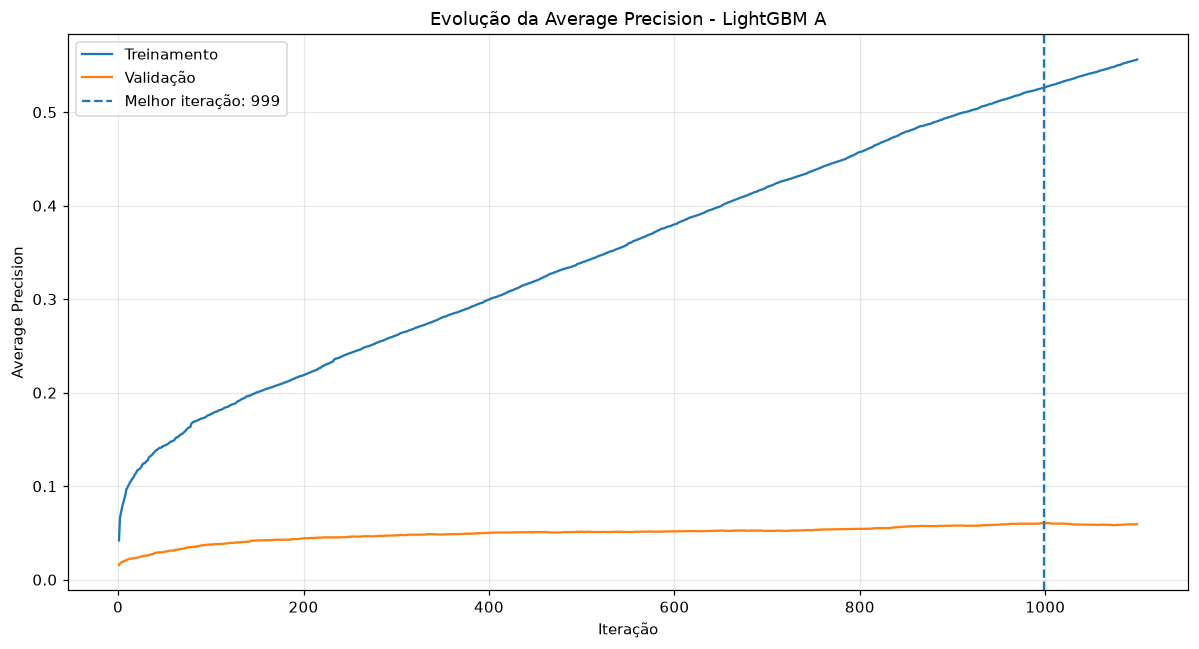


=== IMPORTÂNCIA DAS CARACTERÍSTICAS ===


,Característica,Gain,Split
25,gap_log_06,14994342.85,842
22,gap_log_03,7053000.51,730
29,gap_log_10,5631968.50,742
84,payment_type_05,2622458.03,669
21,gap_log_02,2237650.97,841
18,direction_09,1749557.94,97
20,gap_log_01,1682531.99,779
11,direction_02,1557126.42,87
89,payment_type_10,1512382.49,666
81,payment_type_02,1394632.53,653


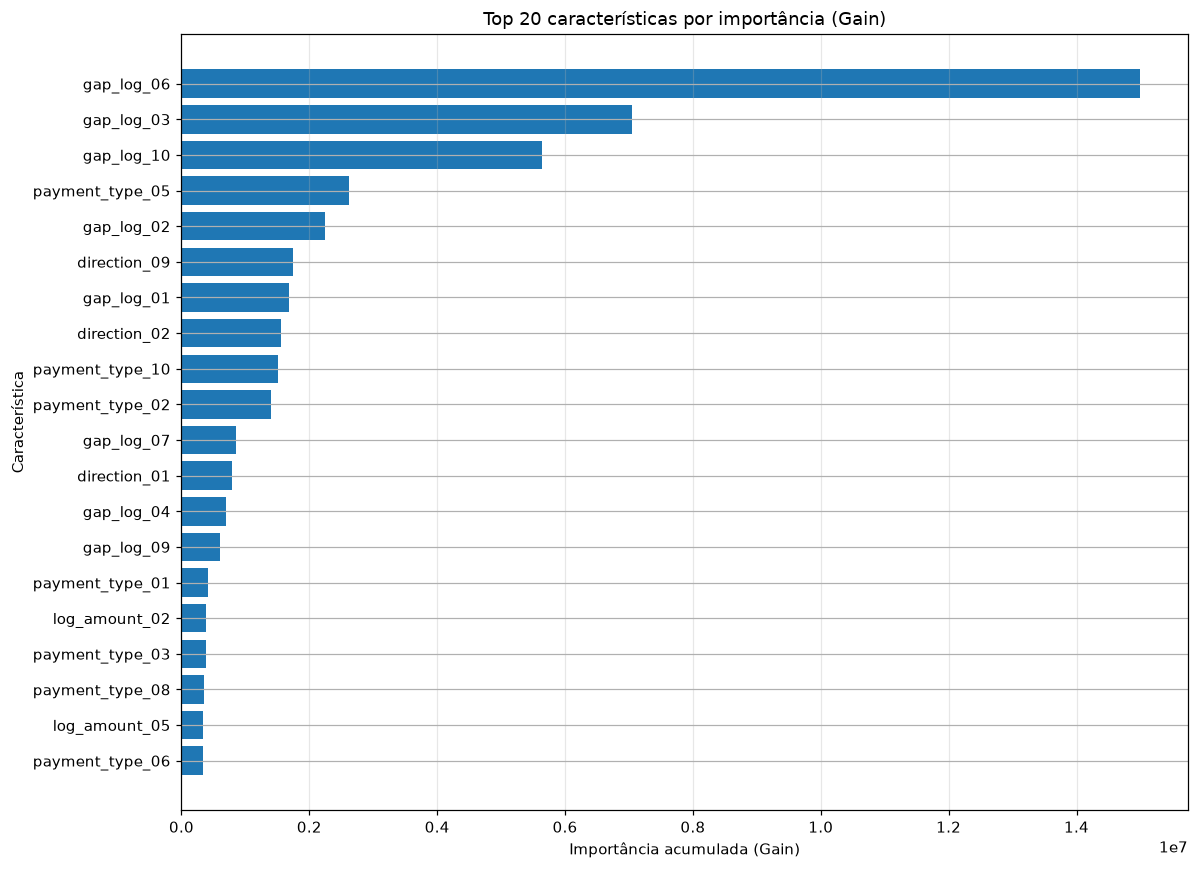


Diagnóstico concluído!


In [29]:
# ============================================================
# 7.2 DIAGNÓSTICO DO LIGHTGBM A
# ============================================================

print("=" * 65)
print("DIAGNÓSTICO DO LIGHTGBM A")
print("=" * 65)


# ============================================================
# 1. MELHOR ITERAÇÃO E RESULTADOS
# ============================================================

print("\n=== MELHOR ITERAÇÃO ===")

print("Melhor iteração:", modelo_lgbm_a.best_iteration)
print("Iterações realizadas:", modelo_lgbm_a.current_iteration())
print("Árvores:", modelo_lgbm_a.num_trees())

print("\nMelhores métricas registradas:")

display(
    pd.DataFrame(modelo_lgbm_a.best_score)
)


# ============================================================
# 2. AVERAGE PRECISION NO TREINAMENTO
# ============================================================

print("\n=== AP NO TREINAMENTO ===")

scores_lgbm_a_train = modelo_lgbm_a.predict(
    X_train_a,
    num_iteration=modelo_lgbm_a.best_iteration
)

ap_lgbm_a_train = average_precision_score(
    y_train_a,
    scores_lgbm_a_train
)

print(f"AP treinamento: {ap_lgbm_a_train:.6f}")
print(f"AP validação:   {ap_lgbm_a_val:.6f}")

diferenca_ap = (
    ap_lgbm_a_train - ap_lgbm_a_val
)

print(f"Diferença:      {diferenca_ap:.6f}")


# ============================================================
# 3. HISTÓRICO DO TREINAMENTO
# ============================================================

historico_treino = np.array(
    historico_lgbm_a["treino"]["average_precision"]
)

historico_validacao = np.array(
    historico_lgbm_a["validacao"]["average_precision"]
)

melhor_iteracao_historico = (
    np.argmax(historico_validacao) + 1
)

print("\n=== HISTÓRICO DE AP ===")

print(
    "Melhor AP no histórico:",
    f"{historico_validacao.max():.6f}"
)

print(
    "Iteração correspondente:",
    melhor_iteracao_historico
)

# Últimas iterações registradas
resumo_historico = pd.DataFrame({

    "Iteração": np.arange(
        1,
        len(historico_validacao) + 1
    ),

    "AP treinamento": historico_treino,

    "AP validação": historico_validacao

})

print("\nÚltimas 10 avaliações:")

display(
    resumo_historico.tail(10).round(6)
)


# ============================================================
# 4. GRÁFICO DAS CURVAS DE AP
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    resumo_historico["Iteração"],
    resumo_historico["AP treinamento"],
    label="Treinamento"
)

ax.plot(
    resumo_historico["Iteração"],
    resumo_historico["AP validação"],
    label="Validação"
)

ax.axvline(
    modelo_lgbm_a.best_iteration,
    linestyle="--",
    label=f"Melhor iteração: {modelo_lgbm_a.best_iteration}"
)

ax.set_title(
    "Evolução da Average Precision - LightGBM A"
)

ax.set_xlabel("Iteração")
ax.set_ylabel("Average Precision")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 5. IMPORTÂNCIA DAS CARACTERÍSTICAS
# ============================================================

print("\n=== IMPORTÂNCIA DAS CARACTERÍSTICAS ===")

importancia = pd.DataFrame({

    "Característica": modelo_lgbm_a.feature_name(),

    "Gain": modelo_lgbm_a.feature_importance(
        importance_type="gain"
    ),

    "Split": modelo_lgbm_a.feature_importance(
        importance_type="split"
    )

})

importancia = importancia.sort_values(
    "Gain",
    ascending=False
)

display(
    importancia.head(20).round(2)
)


# ============================================================
# 6. GRÁFICO DAS 20 PRINCIPAIS CARACTERÍSTICAS
# ============================================================

top_importancia = (
    importancia
    .head(20)
    .sort_values("Gain")
)

fig, ax = plt.subplots(figsize=(11, 8))

ax.barh(
    top_importancia["Característica"],
    top_importancia["Gain"]
)

ax.set_title(
    "Top 20 características por importância (Gain)"
)

ax.set_xlabel("Importância acumulada (Gain)")
ax.set_ylabel("Característica")

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


print("\nDiagnóstico concluído!")

7.3 ANÁLISE DE GENERALIZAÇÃO E MUDANÇA DE DISTRIBUIÇÃO

Após observar uma diferença expressiva entre a Average Precision de treinamento e validação, será investigada a estabilidade das características entre os períodos.

O objetivo é identificar possíveis mudanças na distribuição dos dados e verificar se as características mais importantes do modelo apresentam comportamentos semelhantes nos conjuntos de treinamento e validação.

ANÁLISE DE DISTRIBUIÇÃO - TREINO VS VALIDAÇÃO

=== MAIORES DIFERENÇAS ENTRE TREINO E VALIDAÇÃO ===


,Característica,Média treino,Média validação,Mediana treino,Mediana validação,P90 treino,P90 validação,SMD
6,gap_log_07,8.8942,8.1179,8.7328,8.1274,13.0370,11.6763,-0.2728
8,gap_log_09,8.8912,8.1185,8.7310,8.1239,13.0292,11.6711,-0.2715
7,gap_log_08,8.8894,8.1196,8.7325,8.1301,13.0203,11.6621,-0.2710
9,gap_log_10,8.8921,8.1223,8.7357,8.1253,13.0285,11.6734,-0.2705
5,gap_log_06,8.8944,8.1257,8.7352,8.1268,13.0455,11.6831,-0.2700
4,gap_log_05,8.9018,8.1375,8.7546,8.1591,13.0351,11.6781,-0.2686
3,gap_log_04,8.9206,8.1637,8.8145,8.2134,13.0389,11.6914,-0.2660
2,gap_log_03,8.9856,8.2475,9.0206,8.4134,13.0464,11.7027,-0.2596
1,gap_log_02,9.1153,8.4028,9.4001,8.8356,13.0507,11.7082,-0.2514
0,gap_log_01,5.0940,6.0286,5.2832,6.0259,11.6082,12.0322,0.2011



=== COMPORTAMENTO DOS INTERVALOS POR CLASSE ===


,Conjunto,Característica,Classe,Quantidade,Média,Mediana,P90
0,Treino,gap_log_03,Normal,1072824,8.9732,9.0057,13.0287
1,Treino,gap_log_03,Suspeita,5580,11.3607,11.5710,14.3481
2,Treino,gap_log_06,Normal,1072824,8.8818,8.7206,13.0293
3,Treino,gap_log_06,Suspeita,5580,11.3166,11.5040,14.2431
4,Treino,gap_log_10,Normal,1072824,8.8807,8.7223,13.0170
5,Treino,gap_log_10,Suspeita,5580,11.0758,11.3552,14.0356
6,Validação,gap_log_03,Normal,193333,8.2384,8.4016,11.6944
7,Validação,gap_log_03,Suspeita,683,10.8231,11.1208,12.7851
8,Validação,gap_log_06,Normal,193333,8.1178,8.1182,11.6779
9,Validação,gap_log_06,Suspeita,683,10.3517,10.7806,12.3611



=== DISTRIBUIÇÃO DO PAYMENT_TYPE_05 ===


,Conjunto,Classe,Payment type,Percentual (%)
0,Treino,Normal,0,21.300
1,Treino,Normal,1,1.714
2,Treino,Normal,2,2.834
3,Treino,Normal,3,21.308
4,Treino,Normal,4,21.435
5,Treino,Normal,5,10.121
6,Treino,Normal,6,21.286
7,Treino,Suspeita,0,16.846
8,Treino,Suspeita,1,13.208
9,Treino,Suspeita,2,11.577


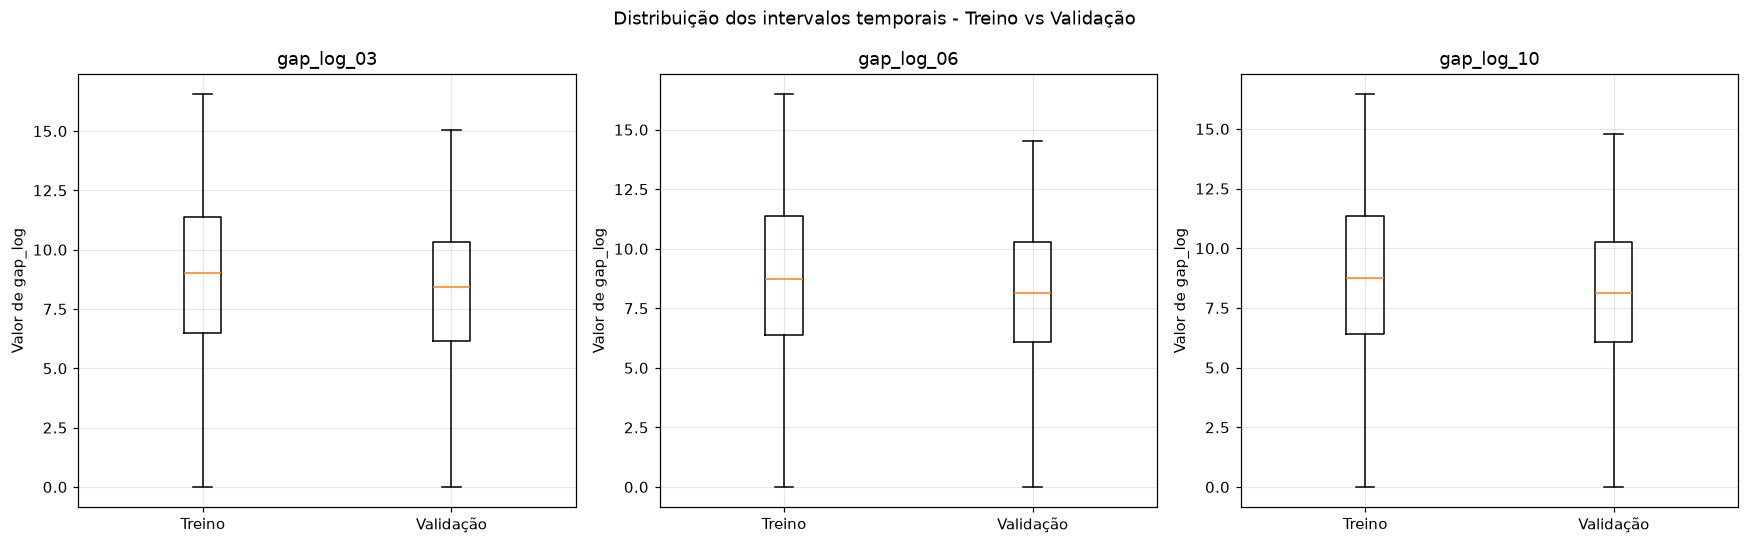


Investigação de distribuição concluída!


In [30]:
# ============================================================
# 7.3 ANÁLISE DE GENERALIZAÇÃO E DATA DRIFT
# ============================================================

print("=" * 65)
print("ANÁLISE DE DISTRIBUIÇÃO - TREINO VS VALIDAÇÃO")
print("=" * 65)


# ============================================================
# 1. COMPARAR DISTRIBUIÇÕES NUMÉRICAS
# ============================================================

# Características mais importantes e famílias relacionadas
features_drift = (

    [
        f"gap_log_{i:02d}"
        for i in range(1, 11)
    ]

    +

    [
        f"log_amount_{i:02d}"
        for i in range(1, 11)
    ]

    +

    [
        f"direction_{i:02d}"
        for i in range(1, 11)
    ]

)

resultados_drift = []

for feature in features_drift:

    treino = X_train_a[feature].to_numpy()
    validacao = X_val_a[feature].to_numpy()

    media_treino = np.mean(treino)
    media_val = np.mean(validacao)

    std_treino = np.std(treino)
    std_val = np.std(validacao)

    # Diferença média padronizada
    denominador = np.sqrt(
        (std_treino**2 + std_val**2) / 2
    )

    smd = (
        (media_val - media_treino) / denominador
        if denominador > 0 else 0
    )

    resultados_drift.append({

        "Característica": feature,

        "Média treino": media_treino,

        "Média validação": media_val,

        "Mediana treino": np.median(treino),

        "Mediana validação": np.median(validacao),

        "P90 treino": np.quantile(treino, 0.90),

        "P90 validação": np.quantile(validacao, 0.90),

        "SMD": smd

    })


df_drift = pd.DataFrame(
    resultados_drift
)

df_drift["SMD absoluto"] = df_drift["SMD"].abs()

df_drift = df_drift.sort_values(
    "SMD absoluto",
    ascending=False
)

print("\n=== MAIORES DIFERENÇAS ENTRE TREINO E VALIDAÇÃO ===")

display(
    df_drift.drop(columns="SMD absoluto")
    .round(4)
)


# ============================================================
# 2. COMPARAR GAP_LOG POR CLASSE
# ============================================================

print("\n=== COMPORTAMENTO DOS INTERVALOS POR CLASSE ===")

features_gap_importantes = [
    "gap_log_03",
    "gap_log_06",
    "gap_log_10"
]

resultados_gap_classe = []

for conjunto, X, y in [
    ("Treino", X_train_a, y_train_a),
    ("Validação", X_val_a, y_val_a)
]:

    for feature in features_gap_importantes:

        for classe, nome_classe in [
            (0, "Normal"),
            (1, "Suspeita")
        ]:

            valores = X.loc[
                y == classe,
                feature
            ].to_numpy()

            resultados_gap_classe.append({

                "Conjunto": conjunto,

                "Característica": feature,

                "Classe": nome_classe,

                "Quantidade": len(valores),

                "Média": np.mean(valores),

                "Mediana": np.median(valores),

                "P90": np.quantile(valores, 0.90)

            })


df_gap_classe = pd.DataFrame(
    resultados_gap_classe
)

display(
    df_gap_classe.round(4)
)


# ============================================================
# 3. COMPARAR PAYMENT_TYPE_05
# ============================================================

print("\n=== DISTRIBUIÇÃO DO PAYMENT_TYPE_05 ===")

resultados_payment = []

for conjunto, X, y in [
    ("Treino", X_train_a, y_train_a),
    ("Validação", X_val_a, y_val_a)
]:

    pagamentos = X["payment_type_05"].cat.codes.to_numpy()

    for classe, nome_classe in [
        (0, "Normal"),
        (1, "Suspeita")
    ]:

        valores = pagamentos[y == classe]

        frequencias = (
            pd.Series(valores)
            .value_counts(normalize=True)
            .reindex(range(7), fill_value=0)
        )

        for codigo, percentual in frequencias.items():

            resultados_payment.append({

                "Conjunto": conjunto,

                "Classe": nome_classe,

                "Payment type": codigo,

                "Percentual (%)": percentual * 100

            })


df_payment_drift = pd.DataFrame(
    resultados_payment
)

display(
    df_payment_drift.round(3)
)


# ============================================================
# 4. GRÁFICO COMPARATIVO DOS PRINCIPAIS GAP_LOG
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

for ax, feature in zip(
    axes,
    features_gap_importantes
):

    ax.boxplot(

        [
            X_train_a[feature].to_numpy(),
            X_val_a[feature].to_numpy()
        ],

        tick_labels=[
            "Treino",
            "Validação"
        ],

        showfliers=False

    )

    ax.set_title(feature)

    ax.set_ylabel("Valor de gap_log")

    ax.grid(alpha=0.3)


plt.suptitle(
    "Distribuição dos intervalos temporais - Treino vs Validação"
)

plt.tight_layout()
plt.show()


print("\nInvestigação de distribuição concluída!")

7.4 PREPARAÇÃO DO LIGHTGBM B

O segundo experimento utilizará a combinação das características posicionais e agregadas, totalizando 124 variáveis por janela.

Serão mantidos os mesmos períodos, rótulos, categorias e configurações de preparação do experimento A.

In [31]:
# ============================================================
# 7.4 PREPARAÇÃO DOS DATASETS LIGHTGBM B
# 124 CARACTERÍSTICAS
# ============================================================

print("=" * 65)
print("PREPARAÇÃO DO LIGHTGBM B")
print("=" * 65)

inicio_preparacao_b = time.perf_counter()


# ============================================================
# 1. SELECIONAR MATRIZES
# ============================================================

X_train_b = X_completo["treino"]
X_val_b = X_completo["validacao"]

y_train_b = y_posicional["treino"].astype(np.int8)
y_val_b = y_posicional["validacao"].astype(np.int8)


# ============================================================
# 2. CONFIGURAÇÕES DO DATASET
# ============================================================

dataset_params_b = {
    "data_random_seed": SEED,
    "max_bin": params_lgbm_a["max_bin"]
}


# ============================================================
# 3. CONSTRUIR DATASET DE TREINAMENTO
# ============================================================

print("\nCriando Dataset de treinamento...")

train_data_b = lgb.Dataset(

    data=X_train_b,

    label=y_train_b,

    feature_name=colunas_completas,

    categorical_feature=colunas_categoricas,

    params=dataset_params_b,

    free_raw_data=True

)

train_data_b.construct()


# ============================================================
# 4. CONSTRUIR DATASET DE VALIDAÇÃO
# ============================================================

print("Criando Dataset de validação...")

valid_data_b = lgb.Dataset(

    data=X_val_b,

    label=y_val_b,

    reference=train_data_b,

    feature_name=colunas_completas,

    categorical_feature=colunas_categoricas,

    params=dataset_params_b,

    free_raw_data=True

)

valid_data_b.construct()


# ============================================================
# 5. VALIDAR ESTRUTURA
# ============================================================

assert train_data_b.num_data() == 1_078_404

assert valid_data_b.num_data() == 194_016

assert train_data_b.num_feature() == 124

assert valid_data_b.num_feature() == 124

assert np.array_equal(
    train_data_b.get_label(),
    y_train_b
)

assert np.array_equal(
    valid_data_b.get_label(),
    y_val_b
)

assert (
    train_data_b.get_feature_name()
    == colunas_completas
)

# Confirmar as categorias nativas
assert all(
    isinstance(
        X_train_b[coluna].dtype,
        pd.CategoricalDtype
    )
    for coluna in colunas_categoricas
)


# ============================================================
# 6. RESULTADOS
# ============================================================

print("\n=== DATASETS LIGHTGBM B ===")

print("Treino:", f"{train_data_b.num_data():,}")
print("Validação:", f"{valid_data_b.num_data():,}")

print("Características:", train_data_b.num_feature())

print("Categorias nativas:", len(colunas_categoricas))

print("Suspeitas no treino:", int(y_train_b.sum()))

print("Suspeitas na validação:", int(y_val_b.sum()))

print(
    "\nMemória das matrizes completas:",
    round(
        (
            X_train_b.memory_usage(deep=True).sum()
            + X_val_b.memory_usage(deep=True).sum()
        ) / 1024**3,
        2
    ),
    "GB"
)

print(
    "\nTempo de preparação:",
    f"{time.perf_counter() - inicio_preparacao_b:.2f} segundos"
)

print("\nLightGBM B preparado corretamente!")

PREPARAÇÃO DO LIGHTGBM B

Criando Dataset de treinamento...
Criando Dataset de validação...

=== DATASETS LIGHTGBM B ===
Treino: 1,078,404
Validação: 194,016
Características: 124
Categorias nativas: 10
Suspeitas no treino: 5580
Suspeitas na validação: 683

Memória das matrizes completas: 0.55 GB

Tempo de preparação: 1.60 segundos

LightGBM B preparado corretamente!


7.5 TREINAMENTO DO LIGHTGBM B — REPRESENTAÇÃO POSICIONAL E AGREGADA

O segundo modelo utilizará 124 características por janela, combinando informações posicionais e estatísticas agregadas.

Serão mantidas as configurações do primeiro experimento, permitindo avaliar o impacto da representação dos dados sobre a capacidade de generalização.

In [32]:
# ============================================================
# 7.5 TREINAMENTO DO FRAUDRADAR LIGHTGBM B
# 124 CARACTERÍSTICAS
# ============================================================

print("=" * 65)
print("TREINAMENTO DO FRAUDRADAR LIGHTGBM B")
print("=" * 65)


# ============================================================
# 1. REUTILIZAR HIPERPARÂMETROS DO LIGHTGBM A
# ============================================================

params_lgbm_b = params_lgbm_a.copy()

print("\nConfiguração experimental:")
print("Características:", 124)
print("Mesmos hiperparâmetros do LightGBM A")
print("Ponderação positiva:", peso_positivo)


# ============================================================
# 2. TREINAMENTO
# ============================================================

NUM_BOOST_ROUND = 2000
EARLY_STOPPING = 100

print("\n=== INICIANDO TREINAMENTO ===")

inicio_treinamento_b = time.perf_counter()

historico_lgbm_b = {}

modelo_lgbm_b = lgb.train(

    params=params_lgbm_b,

    train_set=train_data_b,

    num_boost_round=NUM_BOOST_ROUND,

    valid_sets=[
        train_data_b,
        valid_data_b
    ],

    valid_names=[
        "treino",
        "validacao"
    ],

    callbacks=[

        lgb.early_stopping(
            stopping_rounds=EARLY_STOPPING,
            first_metric_only=True,
            verbose=True
        ),

        lgb.log_evaluation(
            period=50
        ),

        lgb.record_evaluation(
            historico_lgbm_b
        )

    ]

)

tempo_treinamento_lgbm_b = (
    time.perf_counter() - inicio_treinamento_b
)


# ============================================================
# 3. RESULTADOS DO TREINAMENTO
# ============================================================

print("\n=== TREINAMENTO CONCLUÍDO ===")

melhor_ap_lgbm_b = (
    modelo_lgbm_b.best_score["validacao"]["average_precision"]
)

print(
    "Melhor iteração:",
    modelo_lgbm_b.best_iteration
)

print(
    "Melhor AP na validação:",
    f"{melhor_ap_lgbm_b:.6f}"
)

print(
    "Tempo de treinamento:",
    f"{tempo_treinamento_lgbm_b:.2f} segundos"
)

print(
    "Tempo em minutos:",
    f"{tempo_treinamento_lgbm_b / 60:.2f}"
)


# ============================================================
# 4. PREVISÕES NA VALIDAÇÃO
# ============================================================

print("\n=== AVALIAÇÃO NA VALIDAÇÃO ===")

scores_lgbm_b_val = modelo_lgbm_b.predict(

    X_val_b,

    num_iteration=modelo_lgbm_b.best_iteration

)

ap_lgbm_b_val = average_precision_score(

    y_val_b,

    scores_lgbm_b_val

)

print(
    "Average Precision - LightGBM B:",
    f"{ap_lgbm_b_val:.6f}"
)


# ============================================================
# 5. PRECISION E RECALL TOP-K
# ============================================================

resultados_top_k_lgbm_b = avaliar_top_k(

    y_val_b,

    scores_lgbm_b_val,

    [100, 300, 1000, 3000]

)

print("\n=== RESULTADOS TOP-K ===")

display(
    resultados_top_k_lgbm_b.round(2)
)


# ============================================================
# 6. ESTRUTURA DO MODELO
# ============================================================

print("\n=== ESTRUTURA DO MODELO ===")

print(
    "Quantidade de árvores:",
    modelo_lgbm_b.num_trees()
)

print(
    "Quantidade de características:",
    modelo_lgbm_b.num_feature()
)

print("\nTreinamento do LightGBM B finalizado!")

TREINAMENTO DO FRAUDRADAR LIGHTGBM B

Configuração experimental:
Características: 124
Mesmos hiperparâmetros do LightGBM A
Ponderação positiva: 192.26236559139784

=== INICIANDO TREINAMENTO ===
Training until validation scores don't improve for 100 rounds
[50]	treino's average_precision: 0.234299	validacao's average_precision: 0.090343
[100]	treino's average_precision: 0.257807	validacao's average_precision: 0.103345
[150]	treino's average_precision: 0.281763	validacao's average_precision: 0.107437
[200]	treino's average_precision: 0.302394	validacao's average_precision: 0.112194
[250]	treino's average_precision: 0.32589	validacao's average_precision: 0.116174
[300]	treino's average_precision: 0.349286	validacao's average_precision: 0.118581
[350]	treino's average_precision: 0.375345	validacao's average_precision: 0.121621
[400]	treino's average_precision: 0.40261	validacao's average_precision: 0.123956
[450]	treino's average_precision: 0.429434	validacao's average_precision: 0.126234


,Top K,Suspeitas encontradas,Precisão (%),Recall (%)
0,100,62,62.00,9.08
1,300,102,34.00,14.93
2,1000,162,16.20,23.72
3,3000,242,8.07,35.43



=== ESTRUTURA DO MODELO ===
Quantidade de árvores: 1268
Quantidade de características: 124

Treinamento do LightGBM B finalizado!


7.6 DIAGNÓSTICO DO LIGHTGBM B

Serão analisadas as curvas de aprendizado, a diferença de desempenho entre treinamento e validação e a importância das características.

Também será investigada a contribuição das características agregadas em comparação às características posicionais.

DIAGNÓSTICO DO LIGHTGBM B

=== RESULTADOS GERAIS ===
Melhor iteração: 1268
Árvores: 1268
Características: 124
Tempo de treinamento: 76.52 segundos
AP validação: 0.148075

=== AP TREINAMENTO VS VALIDAÇÃO ===
AP treinamento: 0.721915
AP validação:   0.148075
Diferença:      0.573841

=== MELHOR RESULTADO DO HISTÓRICO ===
Iteração: 1268
AP máxima: 0.148075

Últimas 10 avaliações:


,Iteração,AP treinamento,AP validação
1358,1359,0.757308,0.147376
1359,1360,0.757595,0.147191
1360,1361,0.757836,0.147156
1361,1362,0.758084,0.147153
1362,1363,0.758394,0.147002
1363,1364,0.758679,0.147116
1364,1365,0.759065,0.147133
1365,1366,0.759833,0.147222
1366,1367,0.760077,0.147436
1367,1368,0.760252,0.147669


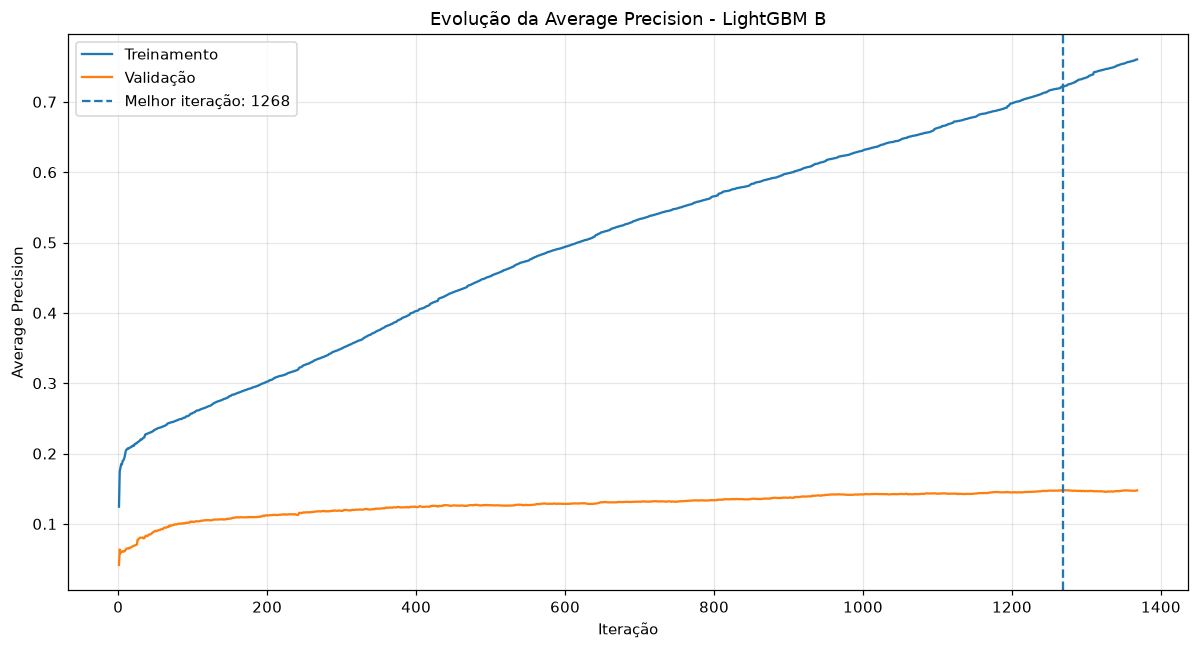


=== IMPORTÂNCIA DAS CARACTERÍSTICAS ===

=== TOP 25 CARACTERÍSTICAS ===


,Característica,Gain,Split,Grupo
91,log_amount_std,29176260.05,571,Agregada
101,gap_max,7638101.82,925,Agregada
99,gap_std,4338473.10,440,Agregada
114,payment_type_count_5,2370010.77,211,Agregada
107,direction_changes,1777631.50,185,Agregada
104,gap_q75,1397160.30,545,Agregada
116,payment_type_distinct,1097246.52,155,Agregada
111,payment_type_count_2,927296.74,133,Agregada
98,gap_mean,912818.34,363,Agregada
106,envios_count,716370.86,463,Agregada



=== CONTRIBUIÇÃO POR GRUPO ===


,Gain_total,Split_total,Caracteristicas_utilizadas,Participacao_Gain (%),Participacao_Split (%)
Grupo,,,,,
Agregada,54987821.46,13452,34,88.16,35.36
Posicional,7384969.79,24588,81,11.84,64.64


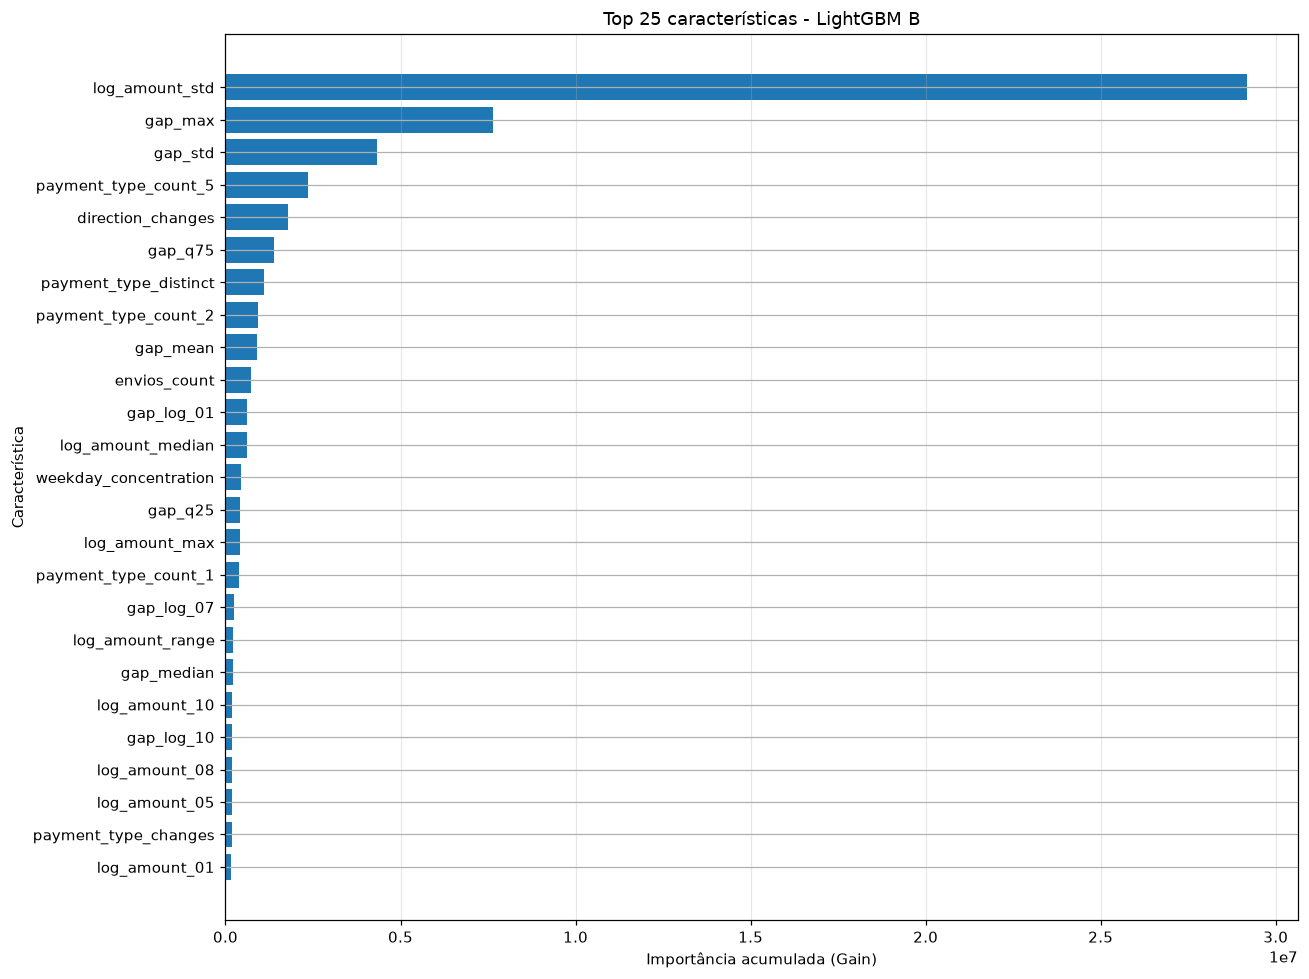


Diagnóstico do LightGBM B concluído!


In [33]:
# ============================================================
# 7.6 DIAGNÓSTICO DO LIGHTGBM B
# ============================================================

print("=" * 65)
print("DIAGNÓSTICO DO LIGHTGBM B")
print("=" * 65)


# ============================================================
# 1. RESULTADOS DO TREINAMENTO
# ============================================================

print("\n=== RESULTADOS GERAIS ===")

print("Melhor iteração:", modelo_lgbm_b.best_iteration)

print("Árvores:", modelo_lgbm_b.num_trees())

print("Características:", modelo_lgbm_b.num_feature())

print(
    "Tempo de treinamento:",
    f"{tempo_treinamento_lgbm_b:.2f} segundos"
)

print(
    "AP validação:",
    f"{ap_lgbm_b_val:.6f}"
)


# ============================================================
# 2. AP NO CONJUNTO DE TREINAMENTO
# ============================================================

print("\n=== AP TREINAMENTO VS VALIDAÇÃO ===")

scores_lgbm_b_train = modelo_lgbm_b.predict(
    X_train_b,
    num_iteration=modelo_lgbm_b.best_iteration
)

ap_lgbm_b_train = average_precision_score(
    y_train_b,
    scores_lgbm_b_train
)

diferenca_ap_b = (
    ap_lgbm_b_train - ap_lgbm_b_val
)

print(f"AP treinamento: {ap_lgbm_b_train:.6f}")

print(f"AP validação:   {ap_lgbm_b_val:.6f}")

print(f"Diferença:      {diferenca_ap_b:.6f}")


# ============================================================
# 3. HISTÓRICO DAS ITERAÇÕES
# ============================================================

historico_treino_b = np.array(
    historico_lgbm_b["treino"]["average_precision"]
)

historico_validacao_b = np.array(
    historico_lgbm_b["validacao"]["average_precision"]
)

melhor_iteracao_b = (
    np.argmax(historico_validacao_b) + 1
)

resumo_historico_b = pd.DataFrame({

    "Iteração": np.arange(
        1,
        len(historico_validacao_b) + 1
    ),

    "AP treinamento": historico_treino_b,

    "AP validação": historico_validacao_b

})

print("\n=== MELHOR RESULTADO DO HISTÓRICO ===")

print("Iteração:", melhor_iteracao_b)

print(
    "AP máxima:",
    f"{historico_validacao_b.max():.6f}"
)

print("\nÚltimas 10 avaliações:")

display(
    resumo_historico_b.tail(10).round(6)
)


# ============================================================
# 4. GRÁFICO DAS CURVAS DE AP
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    resumo_historico_b["Iteração"],
    resumo_historico_b["AP treinamento"],
    label="Treinamento"
)

ax.plot(
    resumo_historico_b["Iteração"],
    resumo_historico_b["AP validação"],
    label="Validação"
)

ax.axvline(
    modelo_lgbm_b.best_iteration,
    linestyle="--",
    label=f"Melhor iteração: {modelo_lgbm_b.best_iteration}"
)

ax.set_title(
    "Evolução da Average Precision - LightGBM B"
)

ax.set_xlabel("Iteração")
ax.set_ylabel("Average Precision")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 5. IMPORTÂNCIA DAS 124 CARACTERÍSTICAS
# ============================================================

print("\n=== IMPORTÂNCIA DAS CARACTERÍSTICAS ===")

importancia_b = pd.DataFrame({

    "Característica": modelo_lgbm_b.feature_name(),

    "Gain": modelo_lgbm_b.feature_importance(
        importance_type="gain"
    ),

    "Split": modelo_lgbm_b.feature_importance(
        importance_type="split"
    )

})

# Identificar a origem das características
importancia_b["Grupo"] = np.where(
    importancia_b["Característica"].isin(features_agregadas),
    "Agregada",
    "Posicional"
)

importancia_b = importancia_b.sort_values(
    "Gain",
    ascending=False
)

print("\n=== TOP 25 CARACTERÍSTICAS ===")

display(
    importancia_b.head(25).round(2)
)


# ============================================================
# 6. CONTRIBUIÇÃO DOS GRUPOS DE CARACTERÍSTICAS
# ============================================================

print("\n=== CONTRIBUIÇÃO POR GRUPO ===")

contribuicao_grupos = (
    importancia_b
    .groupby("Grupo")
    .agg(
        Gain_total=("Gain", "sum"),
        Split_total=("Split", "sum"),
        Caracteristicas_utilizadas=(
            "Característica",
            lambda x: (importancia_b.loc[x.index, "Gain"] > 0).sum()
        )
    )
)

contribuicao_grupos["Participacao_Gain (%)"] = (
    contribuicao_grupos["Gain_total"]
    / contribuicao_grupos["Gain_total"].sum()
    * 100
)

contribuicao_grupos["Participacao_Split (%)"] = (
    contribuicao_grupos["Split_total"]
    / contribuicao_grupos["Split_total"].sum()
    * 100
)

display(
    contribuicao_grupos.round(2)
)


# ============================================================
# 7. GRÁFICO DA IMPORTÂNCIA DAS 25 PRINCIPAIS
# ============================================================

top25_b = (
    importancia_b
    .head(25)
    .sort_values("Gain")
)

fig, ax = plt.subplots(figsize=(12, 9))

ax.barh(
    top25_b["Característica"],
    top25_b["Gain"]
)

ax.set_title(
    "Top 25 características - LightGBM B"
)

ax.set_xlabel("Importância acumulada (Gain)")
ax.set_ylabel("Característica")

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


print("\nDiagnóstico do LightGBM B concluído!")

7.7 PREPARAÇÃO DO LIGHTGBM C — MODELO REGULARIZADO

Será mantida a representação de 124 características do LightGBM B, mas com árvores menos complexas e maior regularização.

O objetivo é investigar se a redução da complexidade melhora a generalização sem comprometer a capacidade de identificar janelas suspeitas.

In [34]:
# ============================================================
# 7.7 PREPARAÇÃO DO LIGHTGBM C
# ============================================================

print("=" * 65)
print("PREPARAÇÃO DO LIGHTGBM C")
print("=" * 65)


# ============================================================
# 1. CONFIGURAÇÕES REGULARIZADAS
# ============================================================

params_lgbm_c = params_lgbm_b.copy()

params_lgbm_c.update({

    "num_leaves": 15,

    "max_depth": 6,

    "min_data_in_leaf": 500,

    "lambda_l1": 1.0,

    "lambda_l2": 10.0

})


# ============================================================
# 2. PARÂMETROS DE CONSTRUÇÃO DOS DATASETS
# ============================================================

dataset_params_c = {

    "data_random_seed": SEED,

    "max_bin": params_lgbm_c["max_bin"],

    "min_data_in_leaf": params_lgbm_c["min_data_in_leaf"]

}


# ============================================================
# 3. CONSTRUIR DATASET DE TREINAMENTO
# ============================================================

print("\nCriando Dataset de treinamento...")

inicio_preparacao_c = time.perf_counter()

train_data_c = lgb.Dataset(

    data=X_train_b,

    label=y_train_b,

    feature_name=colunas_completas,

    categorical_feature=colunas_categoricas,

    params=dataset_params_c,

    free_raw_data=True

)

train_data_c.construct()


# ============================================================
# 4. CONSTRUIR DATASET DE VALIDAÇÃO
# ============================================================

print("Criando Dataset de validação...")

valid_data_c = lgb.Dataset(

    data=X_val_b,

    label=y_val_b,

    reference=train_data_c,

    feature_name=colunas_completas,

    categorical_feature=colunas_categoricas,

    params=dataset_params_c,

    free_raw_data=True

)

valid_data_c.construct()


# ============================================================
# 5. VALIDAR
# ============================================================

assert train_data_c.num_data() == 1_078_404

assert valid_data_c.num_data() == 194_016

assert train_data_c.num_feature() == 124

assert valid_data_c.num_feature() == 124

assert np.array_equal(
    train_data_c.get_label(),
    y_train_b
)

assert np.array_equal(
    valid_data_c.get_label(),
    y_val_b
)


# ============================================================
# 6. RESULTADOS
# ============================================================

print("\n=== CONFIGURAÇÕES DO LIGHTGBM C ===")

for parametro in [
    "num_leaves",
    "max_depth",
    "min_data_in_leaf",
    "lambda_l1",
    "lambda_l2",
    "scale_pos_weight"
]:

    print(
        f"{parametro}: {params_lgbm_c[parametro]}"
    )


print("\n=== DATASETS CONSTRUÍDOS ===")

print("Treino:", f"{train_data_c.num_data():,}")

print("Validação:", f"{valid_data_c.num_data():,}")

print("Características:", train_data_c.num_feature())

print(
    "\nTempo de preparação:",
    f"{time.perf_counter() - inicio_preparacao_c:.2f} segundos"
)

print("\nLightGBM C preparado corretamente!")

PREPARAÇÃO DO LIGHTGBM C

Criando Dataset de treinamento...
Criando Dataset de validação...

=== CONFIGURAÇÕES DO LIGHTGBM C ===
num_leaves: 15
max_depth: 6
min_data_in_leaf: 500
lambda_l1: 1.0
lambda_l2: 10.0
scale_pos_weight: 192.26236559139784

=== DATASETS CONSTRUÍDOS ===
Treino: 1,078,404
Validação: 194,016
Características: 124

Tempo de preparação: 1.54 segundos

LightGBM C preparado corretamente!


7.8 TREINAMENTO DO LIGHTGBM C — MODELO REGULARIZADO

O terceiro experimento utilizará a mesma representação de 124 características do LightGBM B, com parâmetros de regularização mais fortes.

O objetivo é reduzir o sobreajuste e melhorar a generalização para o conjunto de validação.

In [35]:
# ============================================================
# 7.8 TREINAMENTO DO FRAUDRADAR LIGHTGBM C
# MODELO REGULARIZADO - 124 CARACTERÍSTICAS
# ============================================================

print("=" * 65)
print("TREINAMENTO DO FRAUDRADAR LIGHTGBM C")
print("=" * 65)


# ============================================================
# 1. APRESENTAR CONFIGURAÇÕES
# ============================================================

print("\n=== CONFIGURAÇÕES ===")

for parametro, valor in params_lgbm_c.items():
    print(f"{parametro}: {valor}")


# ============================================================
# 2. CONFIGURAÇÕES DE TREINAMENTO
# ============================================================

NUM_BOOST_ROUND = 2000
EARLY_STOPPING = 100

print("\n=== INICIANDO TREINAMENTO ===")

inicio_treinamento_c = time.perf_counter()

historico_lgbm_c = {}


# ============================================================
# 3. TREINAR MODELO
# ============================================================

modelo_lgbm_c = lgb.train(

    params=params_lgbm_c,

    train_set=train_data_c,

    num_boost_round=NUM_BOOST_ROUND,

    valid_sets=[
        train_data_c,
        valid_data_c
    ],

    valid_names=[
        "treino",
        "validacao"
    ],

    callbacks=[

        lgb.early_stopping(
            stopping_rounds=EARLY_STOPPING,
            first_metric_only=True,
            verbose=True
        ),

        lgb.log_evaluation(
            period=50
        ),

        lgb.record_evaluation(
            historico_lgbm_c
        )

    ]

)


# ============================================================
# 4. TEMPO E MELHORES RESULTADOS
# ============================================================

tempo_treinamento_lgbm_c = (
    time.perf_counter() - inicio_treinamento_c
)

melhor_ap_lgbm_c = (
    modelo_lgbm_c
    .best_score["validacao"]["average_precision"]
)

print("\n=== TREINAMENTO CONCLUÍDO ===")

print(
    "Melhor iteração:",
    modelo_lgbm_c.best_iteration
)

print(
    "Quantidade de árvores:",
    modelo_lgbm_c.num_trees()
)

print(
    "Melhor AP na validação:",
    f"{melhor_ap_lgbm_c:.6f}"
)

print(
    "Tempo de treinamento:",
    f"{tempo_treinamento_lgbm_c:.2f} segundos"
)


# ============================================================
# 5. PREVISÕES NA VALIDAÇÃO
# ============================================================

print("\n=== AVALIAÇÃO NA VALIDAÇÃO ===")

scores_lgbm_c_val = modelo_lgbm_c.predict(

    X_val_b,

    num_iteration=modelo_lgbm_c.best_iteration

)

ap_lgbm_c_val = average_precision_score(

    y_val_b,

    scores_lgbm_c_val

)

print(
    "Average Precision - LightGBM C:",
    f"{ap_lgbm_c_val:.6f}"
)


# ============================================================
# 6. PRECISION E RECALL TOP-K
# ============================================================

resultados_top_k_lgbm_c = avaliar_top_k(

    y_val_b,

    scores_lgbm_c_val,

    [100, 300, 1000, 3000]

)

print("\n=== RESULTADOS TOP-K ===")

display(
    resultados_top_k_lgbm_c.round(2)
)


# ============================================================
# 7. ESTRUTURA FINAL
# ============================================================

print("\n=== ESTRUTURA DO MODELO ===")

print(
    "Árvores:",
    modelo_lgbm_c.num_trees()
)

print(
    "Características:",
    modelo_lgbm_c.num_feature()
)

print("\nLightGBM C finalizado!")

TREINAMENTO DO FRAUDRADAR LIGHTGBM C

=== CONFIGURAÇÕES ===
objective: binary
metric: average_precision
boosting_type: gbdt
learning_rate: 0.05
num_leaves: 15
max_depth: 6
min_data_in_leaf: 500
feature_fraction: 0.9
bagging_fraction: 0.8
bagging_freq: 1
lambda_l1: 1.0
lambda_l2: 10.0
scale_pos_weight: 192.26236559139784
device_type: cpu
num_threads: -1
max_bin: 255
seed: 42
feature_fraction_seed: 42
bagging_seed: 42
data_random_seed: 42
verbosity: -1

=== INICIANDO TREINAMENTO ===
Training until validation scores don't improve for 100 rounds
[50]	treino's average_precision: 0.218885	validacao's average_precision: 0.102237
[100]	treino's average_precision: 0.240553	validacao's average_precision: 0.114325
[150]	treino's average_precision: 0.253752	validacao's average_precision: 0.119856
[200]	treino's average_precision: 0.264389	validacao's average_precision: 0.119371
[250]	treino's average_precision: 0.272305	validacao's average_precision: 0.119825
[300]	treino's average_precision: 0.28

,Top K,Suspeitas encontradas,Precisão (%),Recall (%)
0,100,43,43.00,6.30
1,300,79,26.33,11.57
2,1000,142,14.20,20.79
3,3000,237,7.90,34.70



=== ESTRUTURA DO MODELO ===
Árvores: 317
Características: 124

LightGBM C finalizado!


COMPARAÇÃO DE GENERALIZAÇÃO

Calculando AP de treinamento do LightGBM C...

=== COMPARAÇÃO DOS MODELOS ===


,Modelo,AP treino,AP validação,Iterações,Tempo (segundos),Diferença AP
0,LightGBM A,0.526360,0.060669,999,54.014512,0.465691
1,LightGBM B,0.721915,0.148075,1268,76.522533,0.573841
2,LightGBM C,0.282895,0.122338,317,23.786289,0.160557



=== COMPARAÇÃO TOP-K NA VALIDAÇÃO ===


,Modelo,Top K,Suspeitas,Precisão (%),Recall (%)
0,LightGBM A,100,27,27.00,3.95
1,LightGBM A,300,61,20.33,8.93
2,LightGBM A,1000,113,11.30,16.54
3,LightGBM A,3000,180,6.00,26.35
4,LightGBM B,100,62,62.00,9.08
5,LightGBM B,300,102,34.00,14.93
6,LightGBM B,1000,162,16.20,23.72
7,LightGBM B,3000,242,8.07,35.43
8,LightGBM C,100,43,43.00,6.30
9,LightGBM C,300,79,26.33,11.57


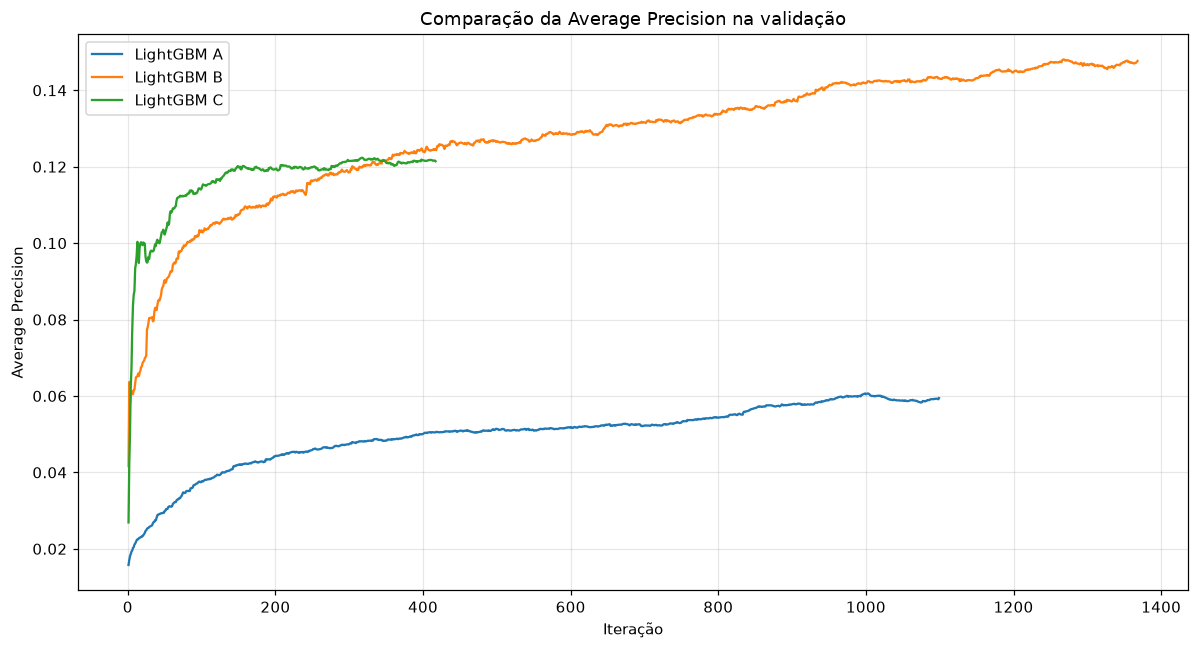


Comparação concluída!


In [36]:
# ============================================================
# 7.9 COMPARAÇÃO DE GENERALIZAÇÃO
# LIGHTGBM A, B E C
# ============================================================

print("=" * 65)
print("COMPARAÇÃO DE GENERALIZAÇÃO")
print("=" * 65)


# ============================================================
# 1. AP DE TREINAMENTO DO LIGHTGBM C
# ============================================================

print("\nCalculando AP de treinamento do LightGBM C...")

scores_lgbm_c_train = modelo_lgbm_c.predict(
    X_train_b,
    num_iteration=modelo_lgbm_c.best_iteration
)

ap_lgbm_c_train = average_precision_score(
    y_train_b,
    scores_lgbm_c_train
)


# ============================================================
# 2. CONSOLIDAR RESULTADOS
# ============================================================

resultados_modelos = pd.DataFrame({

    "Modelo": [
        "LightGBM A",
        "LightGBM B",
        "LightGBM C"
    ],

    "AP treino": [
        ap_lgbm_a_train,
        ap_lgbm_b_train,
        ap_lgbm_c_train
    ],

    "AP validação": [
        ap_lgbm_a_val,
        ap_lgbm_b_val,
        ap_lgbm_c_val
    ],

    "Iterações": [
        modelo_lgbm_a.best_iteration,
        modelo_lgbm_b.best_iteration,
        modelo_lgbm_c.best_iteration
    ],

    "Tempo (segundos)": [
        tempo_treinamento_lgbm_a,
        tempo_treinamento_lgbm_b,
        tempo_treinamento_lgbm_c
    ]

})

resultados_modelos["Diferença AP"] = (
    resultados_modelos["AP treino"]
    - resultados_modelos["AP validação"]
)

print("\n=== COMPARAÇÃO DOS MODELOS ===")

display(
    resultados_modelos.round(6)
)


# ============================================================
# 3. COMPARAÇÃO TOP-K
# ============================================================

print("\n=== COMPARAÇÃO TOP-K NA VALIDAÇÃO ===")

comparacao_topk = []

for nome, resultado in [
    ("LightGBM A", resultados_top_k_lgbm_a),
    ("LightGBM B", resultados_top_k_lgbm_b),
    ("LightGBM C", resultados_top_k_lgbm_c)
]:

    for _, linha in resultado.iterrows():

        comparacao_topk.append({

            "Modelo": nome,

            "Top K": int(linha["Top K"]),

            "Suspeitas": int(
                linha["Suspeitas encontradas"]
            ),

            "Precisão (%)": linha["Precisão (%)"],

            "Recall (%)": linha["Recall (%)"]

        })


df_comparacao_topk = pd.DataFrame(
    comparacao_topk
)

display(
    df_comparacao_topk.round(2)
)


# ============================================================
# 4. COMPARAÇÃO DAS CURVAS DE VALIDAÇÃO
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    np.arange(
        1,
        len(historico_lgbm_a["validacao"]["average_precision"]) + 1
    ),
    historico_lgbm_a["validacao"]["average_precision"],
    label="LightGBM A"
)

ax.plot(
    np.arange(
        1,
        len(historico_lgbm_b["validacao"]["average_precision"]) + 1
    ),
    historico_lgbm_b["validacao"]["average_precision"],
    label="LightGBM B"
)

ax.plot(
    np.arange(
        1,
        len(historico_lgbm_c["validacao"]["average_precision"]) + 1
    ),
    historico_lgbm_c["validacao"]["average_precision"],
    label="LightGBM C"
)

ax.set_title(
    "Comparação da Average Precision na validação"
)

ax.set_xlabel("Iteração")
ax.set_ylabel("Average Precision")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


print("\nComparação concluída!")

In [37]:
# ============================================================
# LIGHTGBM D — REGULARIZAÇÃO INTERMEDIÁRIA
# ============================================================

import time
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import average_precision_score

# 1. Parâmetros: equilíbrio entre B e C
params_lgbm_d = params_lgbm_b.copy()

params_lgbm_d.update({
    "num_leaves": 23,
    "max_depth": 8,
    "min_data_in_leaf": 250,
    "lambda_l1": 0.1,
    "lambda_l2": 5.0
})

# 2. Reconstruir os Datasets com os novos parâmetros
# Isso evita reutilizar estruturas construídas com outro min_data_in_leaf.
params_dataset_d = {
    "data_random_seed": 42,
    "max_bin": 255,
    "min_data_in_leaf": 250
}

train_data_d = lgb.Dataset(
    X_train_b,
    label=y_train_b,
    categorical_feature="auto",
    free_raw_data=False,
    params=params_dataset_d
)

valid_data_d = lgb.Dataset(
    X_val_b,
    label=y_val_b,
    categorical_feature="auto",
    reference=train_data_d,
    free_raw_data=False,
    params=params_dataset_d
)

print("Datasets do LightGBM D preparados.")
print("Treino:", X_train_b.shape)
print("Validação:", X_val_b.shape)

# 3. Treinamento
historico_lgbm_d = {}

inicio_d = time.time()

modelo_lgbm_d = lgb.train(
    params=params_lgbm_d,
    train_set=train_data_d,
    num_boost_round=2000,
    valid_sets=[train_data_d, valid_data_d],
    valid_names=["treino", "validacao"],
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=100,
            first_metric_only=True,
            verbose=True
        ),
        lgb.log_evaluation(period=50),
        lgb.record_evaluation(historico_lgbm_d)
    ]
)

tempo_treinamento_lgbm_d = time.time() - inicio_d

# 4. AP no treino e na validação
scores_lgbm_d_train = modelo_lgbm_d.predict(
    X_train_b,
    num_iteration=modelo_lgbm_d.best_iteration
)

scores_lgbm_d_val = modelo_lgbm_d.predict(
    X_val_b,
    num_iteration=modelo_lgbm_d.best_iteration
)

ap_lgbm_d_train = average_precision_score(
    y_train_b, scores_lgbm_d_train
)

ap_lgbm_d_val = average_precision_score(
    y_val_b, scores_lgbm_d_val
)

diferenca_ap_d = ap_lgbm_d_train - ap_lgbm_d_val

print("\n" + "=" * 60)
print("RESULTADO DO LIGHTGBM D")
print("=" * 60)
print(f"Melhor iteração: {modelo_lgbm_d.best_iteration}")
print(f"Árvores construídas: {modelo_lgbm_d.num_trees()}")
print(f"AP treino: {ap_lgbm_d_train:.6f}")
print(f"AP validação: {ap_lgbm_d_val:.6f}")
print(f"Diferença AP: {diferenca_ap_d:.6f}")
print(f"Tempo: {tempo_treinamento_lgbm_d:.2f} segundos")

# 5. Avaliação Top-K na validação
total_suspeitas_val = int(y_val_b.sum())
resultados_d = []

for k in [100, 300, 1000, 3000]:
    indices_top = np.argsort(scores_lgbm_d_val)[::-1][:k]
    suspeitas = int(y_val_b[indices_top].sum())

    resultados_d.append({
        "Modelo": "LightGBM D",
        "Top K": k,
        "Suspeitas": suspeitas,
        "Precisão (%)": round(suspeitas / k * 100, 2),
        "Recall (%)": round(
            suspeitas / total_suspeitas_val * 100, 2
        )
    })

resultados_top_k_lgbm_d = pd.DataFrame(resultados_d)

print("\n=== TOP-K — VALIDAÇÃO ===")
display(resultados_top_k_lgbm_d)

Datasets do LightGBM D preparados.
Treino: (1078404, 124)
Validação: (194016, 124)
Training until validation scores don't improve for 100 rounds
[50]	treino's average_precision: 0.210805	validacao's average_precision: 0.0864276
[100]	treino's average_precision: 0.241816	validacao's average_precision: 0.108804
[150]	treino's average_precision: 0.260803	validacao's average_precision: 0.116396
[200]	treino's average_precision: 0.275474	validacao's average_precision: 0.118885
[250]	treino's average_precision: 0.292265	validacao's average_precision: 0.124613
[300]	treino's average_precision: 0.306856	validacao's average_precision: 0.125998
[350]	treino's average_precision: 0.324968	validacao's average_precision: 0.128062
[400]	treino's average_precision: 0.34551	validacao's average_precision: 0.131045
[450]	treino's average_precision: 0.362191	validacao's average_precision: 0.130879
[500]	treino's average_precision: 0.381931	validacao's average_precision: 0.134456
[550]	treino's average_pre

,Modelo,Top K,Suspeitas,Precisão (%),Recall (%)
0,LightGBM D,100,62,62.00,9.08
1,LightGBM D,300,113,37.67,16.54
2,LightGBM D,1000,161,16.10,23.57
3,LightGBM D,3000,231,7.70,33.82


In [38]:
# ============================================================
# CONSOLIDAÇÃO DOS RESULTADOS — LIGHTGBM A, B, C E D
# ============================================================

comparacao_ap = pd.DataFrame([
    {
        "Modelo": "LightGBM A",
        "AP treino": ap_lgbm_a_train,
        "AP validação": ap_lgbm_a_val,
        "Iterações": modelo_lgbm_a.best_iteration,
        "Diferença AP": ap_lgbm_a_train - ap_lgbm_a_val,
        "Tempo (s)": tempo_treinamento_lgbm_a
    },
    {
        "Modelo": "LightGBM B",
        "AP treino": ap_lgbm_b_train,
        "AP validação": ap_lgbm_b_val,
        "Iterações": modelo_lgbm_b.best_iteration,
        "Diferença AP": ap_lgbm_b_train - ap_lgbm_b_val,
        "Tempo (s)": tempo_treinamento_lgbm_b
    },
    {
        "Modelo": "LightGBM C",
        "AP treino": ap_lgbm_c_train,
        "AP validação": ap_lgbm_c_val,
        "Iterações": modelo_lgbm_c.best_iteration,
        "Diferença AP": ap_lgbm_c_train - ap_lgbm_c_val,
        "Tempo (s)": tempo_treinamento_lgbm_c
    },
    {
        "Modelo": "LightGBM D",
        "AP treino": ap_lgbm_d_train,
        "AP validação": ap_lgbm_d_val,
        "Iterações": modelo_lgbm_d.best_iteration,
        "Diferença AP": ap_lgbm_d_train - ap_lgbm_d_val,
        "Tempo (s)": tempo_treinamento_lgbm_d
    }
])

print("=== COMPARAÇÃO DE GENERALIZAÇÃO ===")
display(comparacao_ap.round(6))

print("\n=== MELHOR RESULTADO REGISTRADO PELO LIGHTGBM D ===")
print(modelo_lgbm_d.best_score)

print("\n=== COMPARAÇÃO TOP-K ===")

comparacao_top_k = pd.concat([
    resultados_top_k_lgbm_a,
    resultados_top_k_lgbm_b,
    resultados_top_k_lgbm_c,
    resultados_top_k_lgbm_d
], ignore_index=True)

display(comparacao_top_k)

=== COMPARAÇÃO DE GENERALIZAÇÃO ===


,Modelo,AP treino,AP validação,Iterações,Diferença AP,Tempo (s)
0,LightGBM A,0.526360,0.060669,999,0.465691,54.014512
1,LightGBM B,0.721915,0.148075,1268,0.573841,76.522533
2,LightGBM C,0.282895,0.122338,317,0.160557,23.786289
3,LightGBM D,0.753300,0.163388,1978,0.589913,114.468375



=== MELHOR RESULTADO REGISTRADO PELO LIGHTGBM D ===
defaultdict(<class 'collections.OrderedDict'>, {'treino': OrderedDict({'average_precision': np.float64(0.7533004391746619)}), 'validacao': OrderedDict({'average_precision': np.float64(0.16338755904169494)})})

=== COMPARAÇÃO TOP-K ===


,Top K,Suspeitas encontradas,Precisão (%),Recall (%),Modelo,Suspeitas
0,100,27.0,27.000000,3.953148,NaN,NaN
1,300,61.0,20.333333,8.931186,NaN,NaN
2,1000,113.0,11.300000,16.544656,NaN,NaN
3,3000,180.0,6.000000,26.354319,NaN,NaN
4,100,62.0,62.000000,9.077599,NaN,NaN
5,300,102.0,34.000000,14.934114,NaN,NaN
6,1000,162.0,16.200000,23.718887,NaN,NaN
7,3000,242.0,8.066667,35.431918,NaN,NaN
8,100,43.0,43.000000,6.295754,NaN,NaN
9,300,79.0,26.333333,11.566618,NaN,NaN


DIAGNÓSTICO DO TREINAMENTO D
Rodadas executadas: 2000
Árvores no modelo: 1978
Melhor iteração: 1978
Melhor AP validação: 0.163388
AP validação na última rodada: 0.162976

Últimas 10 rodadas:
Iteração 1991 | Treino: 0.756157 | Validação: 0.162832
Iteração 1992 | Treino: 0.756488 | Validação: 0.162857
Iteração 1993 | Treino: 0.756744 | Validação: 0.162851
Iteração 1994 | Treino: 0.756971 | Validação: 0.162815
Iteração 1995 | Treino: 0.757166 | Validação: 0.162799
Iteração 1996 | Treino: 0.757464 | Validação: 0.162816
Iteração 1997 | Treino: 0.757419 | Validação: 0.163033
Iteração 1998 | Treino: 0.757562 | Validação: 0.163051
Iteração 1999 | Treino: 0.757771 | Validação: 0.163053
Iteração 2000 | Treino: 0.757760 | Validação: 0.162976

ATENÇÃO: o treinamento chegou ao limite de 2.000 rodadas.


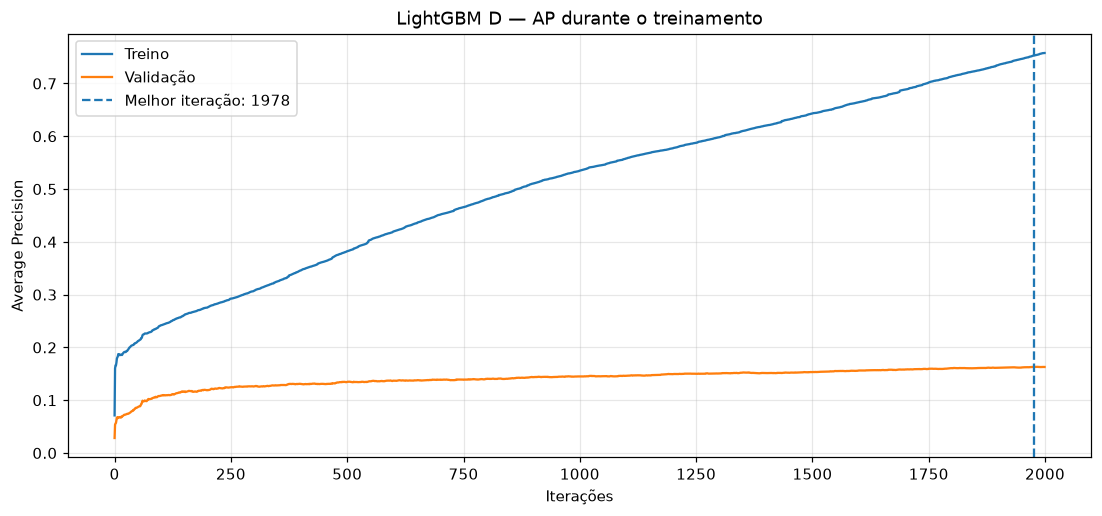

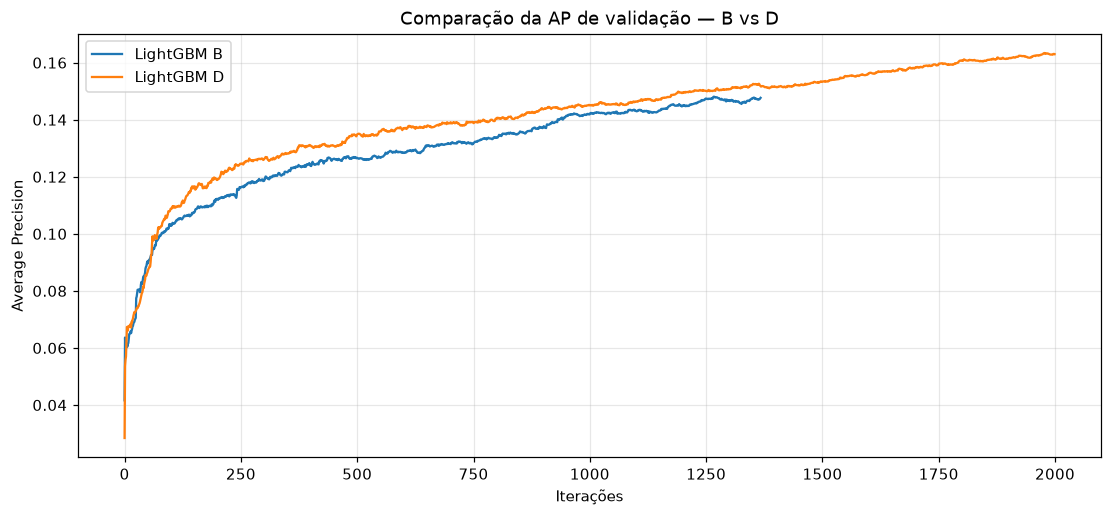

In [39]:
# ============================================================
# DIAGNÓSTICO DAS CURVAS — LIGHTGBM B E D
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Histórico do modelo D
curva_d_treino = historico_lgbm_d["treino"]["average_precision"]
curva_d_val = historico_lgbm_d["validacao"]["average_precision"]

melhor_epoca_d = int(np.argmax(curva_d_val)) + 1
melhor_ap_d = max(curva_d_val)

print("=" * 60)
print("DIAGNÓSTICO DO TREINAMENTO D")
print("=" * 60)

print(f"Rodadas executadas: {len(curva_d_val)}")
print(f"Árvores no modelo: {modelo_lgbm_d.num_trees()}")
print(f"Melhor iteração: {melhor_epoca_d}")
print(f"Melhor AP validação: {melhor_ap_d:.6f}")
print(f"AP validação na última rodada: {curva_d_val[-1]:.6f}")

print("\nÚltimas 10 rodadas:")
for i in range(max(0, len(curva_d_val) - 10), len(curva_d_val)):
    print(
        f"Iteração {i + 1:4d} | "
        f"Treino: {curva_d_treino[i]:.6f} | "
        f"Validação: {curva_d_val[i]:.6f}"
    )

if len(curva_d_val) == 2000:
    print("\nATENÇÃO: o treinamento chegou ao limite de 2.000 rodadas.")

# 1. Evolução de treino e validação do D
plt.figure(figsize=(12, 5))
plt.plot(curva_d_treino, label="Treino")
plt.plot(curva_d_val, label="Validação")
plt.axvline(
    melhor_epoca_d - 1,
    linestyle="--",
    label=f"Melhor iteração: {melhor_epoca_d}"
)
plt.title("LightGBM D — AP durante o treinamento")
plt.xlabel("Iterações")
plt.ylabel("Average Precision")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. Comparação da AP de validação entre B e D
curva_b_val = historico_lgbm_b["validacao"]["average_precision"]

plt.figure(figsize=(12, 5))
plt.plot(curva_b_val, label="LightGBM B")
plt.plot(curva_d_val, label="LightGBM D")
plt.title("Comparação da AP de validação — B vs D")
plt.xlabel("Iterações")
plt.ylabel("Average Precision")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [40]:
# ============================================================
# LIGHTGBM D — CONTINUAÇÃO DO TREINAMENTO
# ============================================================

# Preservar o modelo original como referência
modelo_lgbm_d_base = modelo_lgbm_d
ap_lgbm_d_val_base = ap_lgbm_d_val

historico_lgbm_d_cont = {}

inicio_cont = time.time()

modelo_lgbm_d_cont = lgb.train(
    params=params_lgbm_d,
    train_set=train_data_d,
    num_boost_round=2000,
    valid_sets=[train_data_d, valid_data_d],
    valid_names=["treino", "validacao"],
    init_model=modelo_lgbm_d_base,
    keep_training_booster=True,
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=150,
            first_metric_only=True,
            verbose=True
        ),
        lgb.log_evaluation(period=50),
        lgb.record_evaluation(historico_lgbm_d_cont)
    ]
)

tempo_continuacao = time.time() - inicio_cont

# ============================================================
# AVALIAR A CONTINUAÇÃO
# ============================================================

scores_d_cont_val = modelo_lgbm_d_cont.predict(
    X_val_b,
    num_iteration=modelo_lgbm_d_cont.best_iteration
)

ap_d_cont_val = average_precision_score(
    y_val_b,
    scores_d_cont_val
)

print("\n" + "=" * 60)
print("RESULTADO DA CONTINUAÇÃO DO LIGHTGBM D")
print("=" * 60)

print(f"Rodadas adicionais: {len(historico_lgbm_d_cont['validacao']['average_precision'])}")
print(f"Iteração de melhor resultado: {modelo_lgbm_d_cont.best_iteration}")
print(f"Árvores no modelo: {modelo_lgbm_d_cont.num_trees()}")
print(f"AP validação original: {ap_lgbm_d_val_base:.6f}")
print(f"AP validação continuação: {ap_d_cont_val:.6f}")
print(f"Tempo adicional: {tempo_continuacao:.2f} segundos")

# ============================================================
# SELECIONAR O MELHOR MODELO D
# ============================================================

if ap_d_cont_val > ap_lgbm_d_val_base:
    modelo_lgbm_d_final = modelo_lgbm_d_cont
    scores_lgbm_d_final_val = scores_d_cont_val
    ap_lgbm_d_final_val = ap_d_cont_val
    origem_modelo_d = "Continuação"
else:
    modelo_lgbm_d_final = modelo_lgbm_d_base
    scores_lgbm_d_final_val = modelo_lgbm_d_base.predict(
        X_val_b,
        num_iteration=modelo_lgbm_d_base.best_iteration
    )
    ap_lgbm_d_final_val = ap_lgbm_d_val_base
    origem_modelo_d = "Modelo original"

print(f"\nMelhor versão selecionada: {origem_modelo_d}")
print(f"AP final de validação: {ap_lgbm_d_final_val:.6f}")

# ============================================================
# TOP-K DO MELHOR MODELO D
# ============================================================

total_suspeitas_val = int(y_val_b.sum())
resultados_d_final = []

for k in [100, 300, 1000, 3000]:
    indices_top = np.argsort(scores_lgbm_d_final_val)[::-1][:k]
    suspeitas = int(y_val_b[indices_top].sum())

    resultados_d_final.append({
        "Modelo": "LightGBM D final",
        "Top K": k,
        "Suspeitas": suspeitas,
        "Precisão (%)": round(suspeitas / k * 100, 2),
        "Recall (%)": round(
            suspeitas / total_suspeitas_val * 100, 2
        )
    })

resultados_top_k_lgbm_d_final = pd.DataFrame(resultados_d_final)

display(resultados_top_k_lgbm_d_final)

Training until validation scores don't improve for 150 rounds
[2000]	treino's average_precision: 0.758917	validacao's average_precision: 0.164027
[2050]	treino's average_precision: 0.771984	validacao's average_precision: 0.163828
[2100]	treino's average_precision: 0.784964	validacao's average_precision: 0.162866
[2150]	treino's average_precision: 0.795306	validacao's average_precision: 0.163147
Early stopping, best iteration is:
[2030]	treino's average_precision: 0.766764	validacao's average_precision: 0.164214
Evaluated only: average_precision

RESULTADO DA CONTINUAÇÃO DO LIGHTGBM D
Rodadas adicionais: 202
Iteração de melhor resultado: 2030
Árvores no modelo: 2180
AP validação original: 0.163388
AP validação continuação: 0.164214
Tempo adicional: 20.38 segundos

Melhor versão selecionada: Continuação
AP final de validação: 0.164214


,Modelo,Top K,Suspeitas,Precisão (%),Recall (%)
0,LightGBM D final,100,62,62.00,9.08
1,LightGBM D final,300,112,37.33,16.40
2,LightGBM D final,1000,162,16.20,23.72
3,LightGBM D final,3000,231,7.70,33.82


In [41]:
# ============================================================
# LIGHTGBM E — SOMENTE ATRIBUTOS AGREGADOS
# ============================================================

# 1. Dados
X_train_e = X_agregadas["treino"]
X_val_e = X_agregadas["validacao"]

y_train_e = y_train_b
y_val_e = y_val_b

print("Formato dos dados:")
print("Treino:", X_train_e.shape)
print("Validação:", X_val_e.shape)

# 2. Parâmetros iguais aos do LightGBM D
# A única mudança experimental será a representação dos atributos.
params_lgbm_e = params_lgbm_d.copy()

params_dataset_e = {
    "data_random_seed": 42,
    "max_bin": 255,
    "min_data_in_leaf": 250
}

# 3. Construção dos Datasets
train_data_e = lgb.Dataset(
    X_train_e,
    label=y_train_e,
    free_raw_data=False,
    params=params_dataset_e
)

valid_data_e = lgb.Dataset(
    X_val_e,
    label=y_val_e,
    reference=train_data_e,
    free_raw_data=False,
    params=params_dataset_e
)

# 4. Treinamento
historico_lgbm_e = {}

inicio_e = time.time()

modelo_lgbm_e = lgb.train(
    params=params_lgbm_e,
    train_set=train_data_e,
    num_boost_round=3000,
    valid_sets=[train_data_e, valid_data_e],
    valid_names=["treino", "validacao"],
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=150,
            first_metric_only=True,
            verbose=True
        ),
        lgb.log_evaluation(period=100),
        lgb.record_evaluation(historico_lgbm_e)
    ]
)

tempo_treinamento_lgbm_e = time.time() - inicio_e

# 5. AP de treino e validação
scores_lgbm_e_train = modelo_lgbm_e.predict(
    X_train_e,
    num_iteration=modelo_lgbm_e.best_iteration
)

scores_lgbm_e_val = modelo_lgbm_e.predict(
    X_val_e,
    num_iteration=modelo_lgbm_e.best_iteration
)

ap_lgbm_e_train = average_precision_score(
    y_train_e, scores_lgbm_e_train
)

ap_lgbm_e_val = average_precision_score(
    y_val_e, scores_lgbm_e_val
)

print("\n" + "=" * 60)
print("RESULTADO DO LIGHTGBM E")
print("=" * 60)

print(f"Melhor iteração: {modelo_lgbm_e.best_iteration}")
print(f"Árvores: {modelo_lgbm_e.num_trees()}")
print(f"AP treino: {ap_lgbm_e_train:.6f}")
print(f"AP validação: {ap_lgbm_e_val:.6f}")
print(f"Diferença AP: {ap_lgbm_e_train - ap_lgbm_e_val:.6f}")
print(f"Tempo: {tempo_treinamento_lgbm_e:.2f} segundos")

# 6. Avaliação Top-K
total_suspeitas_val = int(y_val_e.sum())
resultados_e = []

for k in [100, 300, 1000, 3000]:
    indices_top = np.argsort(scores_lgbm_e_val)[::-1][:k]
    suspeitas = int(y_val_e[indices_top].sum())

    resultados_e.append({
        "Modelo": "LightGBM E",
        "Top K": k,
        "Suspeitas": suspeitas,
        "Precisão (%)": round(suspeitas / k * 100, 2),
        "Recall (%)": round(
            suspeitas / total_suspeitas_val * 100, 2
        )
    })

resultados_top_k_lgbm_e = pd.DataFrame(resultados_e)

display(resultados_top_k_lgbm_e)

Formato dos dados:
Treino: (1078404, 34)
Validação: (194016, 34)
Training until validation scores don't improve for 150 rounds
[100]	treino's average_precision: 0.269396	validacao's average_precision: 0.10048
[200]	treino's average_precision: 0.308675	validacao's average_precision: 0.122287
[300]	treino's average_precision: 0.331119	validacao's average_precision: 0.133395
[400]	treino's average_precision: 0.349001	validacao's average_precision: 0.133685
[500]	treino's average_precision: 0.371744	validacao's average_precision: 0.135524
[600]	treino's average_precision: 0.392988	validacao's average_precision: 0.136869
[700]	treino's average_precision: 0.413737	validacao's average_precision: 0.137775
[800]	treino's average_precision: 0.437161	validacao's average_precision: 0.142321
[900]	treino's average_precision: 0.457679	validacao's average_precision: 0.146255
[1000]	treino's average_precision: 0.478452	validacao's average_precision: 0.147318
[1100]	treino's average_precision: 0.501887

,Modelo,Top K,Suspeitas,Precisão (%),Recall (%)
0,LightGBM E,100,66,66.00,9.66
1,LightGBM E,300,109,36.33,15.96
2,LightGBM E,1000,170,17.00,24.89
3,LightGBM E,3000,229,7.63,33.53
